# Player Replacement Scouting: Mining Top-Club Replacements from Lower-Table Talent across Europe's Top 5 Leagues
 <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Data mining on a multi-source football data lake</span>

**Question.** Can data mining find *young players at non-elite clubs* in any of the five big European leagues who play like a current starter of an **elite club** (a top-N side of *its own* league), and do those players later **move up**, whether to a top club in their league, a top club abroad, or a stronger league?

**Big-data stack used and why**
| Step | Technique | Why it fits |
|---|---|---|
| Ingest + outcome join | **DuckDB** (columnar SQL, window functions, `arg_max`, self-join) | 7 seasons x 5 leagues of player rows; the t -> t+1/t+2 self-join over *every* row (any minutes) is a set operation, not a loop |
| Dynamic elite clubs | **League tables for all 5 leagues** rebuilt from Understat match rows (group-by aggregation), checked against the official PL table | No hard-coded list of elite clubs; only a short list of traditional giants is fixed (by design) |
| Profile matching | Standardised 16-D vectors + **cosine similarity** (and 6 other measures) | Finds "same style" players, limited to a short ranked shortlist |
| Pattern discovery | **Apriori vs FP-Growth**, then **class association rules** with Fisher test + Benjamini-Hochberg FDR and redundancy pruning | Finds which *combinations* of traits precede a move up, without us guessing the traits |
| Validation | **Out-of-time** split, walk-forward tests, a base-rate **lift** for every claim, and a **sensitivity analysis** of the reference set | A hit rate means nothing without a baseline |

**What changed in this version (Barath_)**
| Area | Original notebook | This version |
|---|---|---|
| Who is the reference ("whom do we replace?") | starters of the **Premier League top 3** only (about 30 profiles a season) | starters of the **top-N of each of the five leagues** (`ELITE_TOP_N = 6`; `REFERENCE_SCOPE = 'PL'` switches back to PL only); section 8C tests top 3 / 4 / 6 for PL only versus all five leagues |
| Who can be scouted (feeders) | under-25s at Premier League and Ligue 1 clubs only | under-25s at **every non-elite club of all five leagues** |
| What counts as "moving up" | a move to a PL traditional-six or PL top-3 club, or Ligue 1 to PL | a move to **any top-N club or traditional giant of any of the five leagues** (Real Madrid, Bayern, Inter, PSG, ...), graded by tier, or to a **stronger league** |
| When and how the move is detected | only the club two seasons later, and only if the player had 900+ minutes there (a benched star signing was counted as "left the top 5 leagues") | the best destination in **either of the next two seasons, at any minutes**, with an age check against name clashes (DuckDB window query) |
| Reading aid | many short forms, few explanations | a **legend** under every chart and table, a **What this shows / Key takeaway** box after every result, and the **Big Data concept** next to every heading and chart title |

Run the cells top to bottom; every number in the takeaway boxes is computed from the data, nothing is typed in.

## Syllabus coverage map
| Syllabus topic | Where in this notebook | What is done with it |
|---|---|---|
| Descriptive statistics, visualisation and interpretation | 6A | mean/median/std/IQR/skewness/kurtosis, box plots by position, clustered correlation heatmap |
| Data pre-processing | 2, 5, 6B | schema mapping, missing values, GK and minutes filters, de-duplication, winsorising, per-90 scaling, percentile and z transforms, discretisation for rules |
| Data integration and entity resolution | 4A, 4A-2, 5 | Understat to FBref club matching, five league tables, player identity across seasons (name + age check) |
| Domain-specific feature extraction | 6C | shot quality, finishing, creation, progression, box threat, defensive load, age-adjusted performance, starter share + AUC feature selection |
| Dimensionality reduction | 6D | PCA (scree, loadings, 2-D projection); PCA space reused for clustering, outliers and similarity |
| Inferential statistics | 7, 8A, 8C, 6E, 9A | Fisher exact, Benjamini-Hochberg FDR, chi-square, Mann-Whitney, Wilson intervals, permutation and bootstrap tests, Cohen's h |
| Association rules (Apriori, FP-Growth) and interestingness | 7 | both algorithms, class rules, support/confidence/lift/leverage/conviction + null-invariant cosine, Jaccard, Kulczynski |
| Closed and maximal itemsets | 7 (7c2) | compression ratios, lossless check |
| Frequent-itemset algorithms of the course | 7 (7c3) | Apriori, hash-based Apriori (DHP), Dynamic Itemset Counting, vertical Eclat, Partition, A-Close and Pincer-Search written from scratch, verified against FP-Growth, compared on scans, candidates and runtime |
| Clustering (partitioning, hierarchical, model-based, density) | 4B, 6E | K-Means, Ward + dendrogram, Gaussian mixture (BIC), DBSCAN; silhouette, Davies-Bouldin, Calinski-Harabasz, ARI, chi-square vs outcome |
| Outlier analysis | 6F | robust Mahalanobis, Isolation Forest, LOF; agreement and link to outcome |
| Similarity measures | 8, 8B, 8C | cosine, Pearson, Euclidean, Manhattan, Mahalanobis on three representations; reference-set sensitivity |
| Classification and its measures | 9A | logistic regression, decision tree, random forest, naive Bayes; ROC-AUC, PR-AUC, precision@K, confusion matrix, walk-forward validation |
| Decision tree induction | 9A-3 | Gini vs entropy vs log-loss, depth, leaf size and cost-complexity pruning; over-fitting check; text rules, tree drawing and per-player decision paths |
| Bucket-brigade classifier | 9A | two-stage learning classifier system with credit assignment |
| Prediction (regression) | 9B | ridge and gradient boosting vs persistence; MAE, RMSE, R-squared |
| Supervised vs unsupervised | 4B, 6D to 6F (unsupervised), 7 to 9 (supervised) | labels used only from Part V and the rule mining |

<details>
<summary><b>Master legend</b> (click to open): every short form used in this notebook</summary>

**Per-90 metrics** (per 90 minutes played): **gls** goals · **npxg** non-penalty expected goals · **sh** shots · **ast** assists · **kp** key passes (passes that lead to a shot) · **sca** shot-creating actions · **ppa** passes into the penalty area · **prgp** progressive passes · **prgc** progressive carries · **take_on** take-ons (dribbles) attempted · **att_pen** carries into the penalty area · **tklw** tackles won · **int** interceptions · **clr** clearances · **blocks** shots blocked · **aer_won** % of aerial duels won

**Suffixes**: **_p90** per 90 minutes · **_pct** percentile within season and position (0-100) · **_z** winsorised z-score within position · **_p90raw** before team-style and league weighting · **t / t+2** the scouting season / two seasons later

**Positions and leagues**: **DF** defender · **MF** midfielder · **FW** forward · **GK** goalkeeper · **PL** Premier League · **LL** La Liga · **BL** Bundesliga · **SA** Serie A · **L1** Ligue 1

**Team style** (Understat): **x_dom** territorial dominance (deep-completion share, logit, vs league-season mean) · **x_press** pressing intensity (minus log PPDA, vs league-season mean) · **x_str** team strength (non-penalty xG difference per match, standardised) · **PPDA** opponent passes allowed per defensive action (lower = more pressing) · **deep** passes completed within about 20 m of goal · **npxGD** non-penalty xG difference

**Rule items**: **HI_x** top quartile (75th percentile or more) for metric x · **COMPOSITE_Q4** top quartile of the composite index · **AGE_U21 / AGE_21_22 / AGE_23_24** age band · **POS_x** position · **LEAGUE_x** league · **OUT_TOP_CLUB** moved to a top-N or giant club · **OUT_STRONGER_LEAGUE** moved to a club in a stronger league

**Engineered features**: **x_shot_quality** npxG per shot · **x_finishing** goals minus npxG · **x_creation** assists + key passes · **x_progression** progressive passes + carries · **x_box_threat** passes + carries into the box · **x_def_actions** tackles won + interceptions + clearances + blocks · **x_age_adj_perf** composite index minus the average for the same age and season · **x_starter_share** minutes / 3,420 (a full season) · **composite_perf_index** mean percentile over the 16 metrics

**Statistics**: **AUC** area under the ROC curve (0.5 = coin flip) · **AP** average precision (PR-AUC) · **precision@K** share of hits among the top K picks · **CI95** 95% confidence interval · **IQR** inter-quartile range · **FDR** false discovery rate · **q-value** FDR-adjusted p-value · **eta²** share of variance explained by a grouping · **PC** principal component · **ARI** adjusted Rand index · **DB** Davies-Bouldin · **CH** Calinski-Harabasz · **BIC** Bayesian information criterion · **IF** Isolation Forest · **LOF** Local Outlier Factor · **MCD** minimum covariance determinant · **MAE / RMSE** mean absolute / root-mean-square error · **R²** share of variance explained · **lift** rate in a group / overall rate · **LCS** learning classifier system · **ARM** association rule mining
</details>

## 1. Fetch the datasets with the Kaggle CLI <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Data acquisition (Kaggle CLI)</span>

In [1]:
import os, subprocess, glob

DATASETS = {
    'data/fbref': 'akshankrithick/fbref-2017-2024-for-europes-top-5-leagues',
    'data/standings': 'evangower/english-premier-league-standings',
    'data/understat': 'mexwell/understat-database',
}
OUT_DIR = 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)

# Fetch via Kaggle CLI (needs ~/.kaggle/kaggle.json); skipped when already downloaded
for target, slug in DATASETS.items():
    if not glob.glob(f'{target}/**/*.csv', recursive=True):
        subprocess.run(['kaggle', 'datasets', 'download', '-d', slug, '-p', target, '--unzip'], check=True)

## 1b. Chart, table and legend helpers <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Visual analytics standards</span>

One place for the colour theme and the three reading aids used everywhere below: `legend(...)` (a compact one-line glossary of the short forms in that output), `takeaway(...)` (what the output shows and the key takeaway, written from the computed numbers) and `show(fig, name, concept)` (puts the Big Data concept next to every chart title and keeps titles, legends and subplot titles from overlapping). Every pandas table is drawn with the same clean style.

In [2]:
import html as _html
import numpy as np
import pandas as pd
import plotly.graph_objects as go, plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display as _ipy_display, HTML

BLUE, ORANGE, GREY, GREEN = '#2a78d6', '#eb6834', '#898781', '#1baf7a'
INK, INK2, GRID, TAG = '#0b0b0b', '#52514e', '#e1e0d9', '#184f95'
POS3 = ['DF', 'MF', 'FW']; POS_COL = {'DF': BLUE, 'MF': ORANGE, 'FW': GREEN}
SEQ_SCALE = [[0, '#cde2fb'], [0.25, '#86b6ef'], [0.5, '#2a78d6'], [0.75, '#184f95'], [1, '#0d366b']]
DIV_SCALE = [[0, ORANGE], [0.5, '#f0efec'], [1, BLUE]]
FONT = 'Segoe UI, Arial, sans-serif'

pio.renderers.default = 'plotly_mimetype+notebook_connected'   # interactive in Jupyter/VS Code; the CDN script keeps nbconvert HTML interactive too
pio.templates['scout'] = go.layout.Template(layout=dict(
    font=dict(family=FONT, size=12, color=INK), paper_bgcolor='#fcfcfb', plot_bgcolor='#fcfcfb',
    colorway=[BLUE, ORANGE, GREEN, '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948'],
    xaxis=dict(gridcolor=GRID, linecolor='#c3c2b7', zeroline=False, automargin=True, title_standoff=10),
    yaxis=dict(gridcolor=GRID, linecolor='#c3c2b7', zeroline=False, automargin=True, title_standoff=10),
    hoverlabel=dict(bgcolor='white', font_size=12, font_family=FONT), legend=dict(bgcolor='rgba(0,0,0,0)', font_size=11)))
pio.templates.default = 'scout'

GLOSSARY = {
    # per-90 metrics
    'gls': 'goals', 'npxg': 'non-penalty expected goals', 'sh': 'shots', 'ast': 'assists', 'kp': 'key passes (lead to a shot)',
    'sca': 'shot-creating actions', 'ppa': 'passes into the penalty area', 'prgp': 'progressive passes', 'prgc': 'progressive carries',
    'take_on': 'take-ons (dribbles) attempted', 'att_pen': 'carries into the penalty area', 'tklw': 'tackles won', 'int': 'interceptions',
    'clr': 'clearances', 'blocks': 'shots blocked', 'aer_won': '% of aerial duels won', 'sot': 'shots on target', 'xag': 'expected assisted goals',
    'p90': 'per 90 minutes played', 'pct': 'percentile within season and position (0-100)', 'z': 'winsorised z-score within position',
    'raw': 'before team-style and league weighting', 'weighted': 'after team-style and league weighting',
    # positions, leagues
    'DF': 'defender', 'MF': 'midfielder', 'FW': 'forward', 'PL': 'Premier League', 'LL': 'La Liga', 'BL': 'Bundesliga', 'SA': 'Serie A', 'L1': 'Ligue 1',
    # team style
    'x_dom': 'territorial dominance (deep-completion share vs league-season mean, logit)', 'x_press': 'pressing intensity (minus log PPDA vs league-season mean)',
    'x_str': 'team strength (npxG difference per match, standardised)', 'PPDA': 'opponent passes allowed per defensive action (lower = more pressing)',
    'deep_share': "share of a match's deep completions made by the team", 'npxGD_pm': 'non-penalty xG difference per match', 'poss_proxy': "FBref possession proxy (team's share of passes)",
    'directness': 'progressive passes per pass', 'pts': 'league points', 'elasticity': '% change in a per-90 action per unit of the style variable (0.3 = +30%)',
    'log ratio vs PL': 'log of output in that league / output in the Premier League (-0.2 = about 18% less)', 'eta²': 'share of variance explained by the grouping (0 = none)',
    # table and outcome
    'table_pos': 'final league position', 'ppm': 'points per match', 'gd': 'goal difference', 'top-N': f'clubs finishing in the first N places of their league',
    'giant': 'traditional big club (fixed list), always counted as elite', 'tier': '3 = elite club (top-4 or giant), 2 = top-N club, 1 = stronger league, 0 = no move up',
    'hit rate': 'share of picks with any positive outcome weight', 'weighted precision': 'mean outcome weight of the picks (1 elite move ... 0.25 breakout)',
    'base rate': 'the same rate for the whole feeder pool', 'lift': 'rate in the group / base rate (1 = no better than chance)',
    'feeder': 'under-25 with 900+ minutes at a non-elite club', 'elite starter': 'player with 1,350+ minutes at a top-N club of a reference league',
    # rule items
    'HI_x': 'top quartile (75th pct or more) for metric x', 'COMPOSITE_Q4': 'top quartile of the composite index', 'AGE_U21': 'age 20 or under',
    'AGE_21_22': 'age 21-22', 'AGE_23_24': 'age 23-24', 'POS_x': 'position x', 'LEAGUE_x': 'plays in league x', 'OUT_TOP_CLUB': 'moved to a top-N / giant club',
    'OUT_STRONGER_LEAGUE': 'moved to a club in a stronger league', 'support': 'share of transactions containing the itemset', 'confidence': 'P(outcome | antecedent)',
    'leverage': 'support above what independence predicts', 'conviction': '(1 - P(outcome)) / (1 - confidence); 1 = independent',
    'cosine': 'null-invariant: support / sqrt(sup(A) x sup(B))', 'jaccard': 'support / sup(A or B)', 'kulczynski': 'mean of the two confidences (null-invariant)',
    'n_antecedent': 'players matching the rule body', 'n_joint': 'players matching body and outcome', 'p_value': 'one-sided Fisher exact test', 'q_value': 'Benjamini-Hochberg FDR-adjusted p',
    # engineered
    'x_shot_quality': 'npxG per shot', 'x_finishing': 'goals minus npxG', 'x_creation': 'assists + key passes', 'x_progression': 'progressive passes + carries',
    'x_box_threat': 'passes + carries into the box', 'x_def_actions': 'tackles won + interceptions + clearances + blocks',
    'x_age_adj_perf': 'composite index minus the mean of the same age and season', 'x_starter_share': 'minutes / 3,420 (one full season)', 'starter_share': 'minutes / 3,420 (one full season)',
    'composite_perf_index': 'mean percentile over the 16 metrics (0-100)', 'composite_index': 'mean percentile over the 16 metrics (0-100)',
    # statistics
    'mean': 'average', 'median': 'middle value', 'std': 'standard deviation', 'IQR': 'inter-quartile range (75th minus 25th percentile)',
    'skewness': 'asymmetry (0 = symmetric, > 0 = long right tail)', 'kurtosis': 'tail weight vs a normal curve (0 = normal)', 'zero_share': 'share of players with exactly 0',
    'AUC': 'area under the ROC curve (0.5 = coin flip, 1 = perfect)', 'AP': 'average precision, area under the precision-recall curve', 'precision@K': 'share of hits among the top K picks',
    'CI95': '95% confidence interval', 'Wilson': 'Wilson score interval for a proportion', 'FDR': 'false discovery rate', 'PC': 'principal component',
    'silhouette': 'cluster separation, -1 to 1 (higher = better)', 'DB': 'Davies-Bouldin index (lower = better)', 'CH': 'Calinski-Harabasz index (higher = better)',
    'ARI': 'adjusted Rand index: agreement with K-Means (1 = identical)', 'BIC': 'Bayesian information criterion (picks the number of mixture components)',
    'noise_share': 'share labelled noise by DBSCAN', 'IF': 'Isolation Forest anomaly score', 'LOF': 'Local Outlier Factor', 'MCD': 'robust (minimum covariance determinant) Mahalanobis distance',
    'Jaccard overlap': 'size of intersection / size of union of two flag sets', "Cramer's V": 'strength of association for a chi-square table (0 to 1)',
    "Cohen's h": 'effect size for two proportions (0.2 small, 0.5 medium, 0.8 large)', 'Mann-Whitney AUC': 'P(random mover > random stayer); 0.5 = no difference',
    'binomial p': 'chance of at least this many hits if picks were random', 'MAE': 'mean absolute error', 'RMSE': 'root-mean-square error', 'R²': 'share of variance explained',
    'LCS': 'learning classifier system', 'ARM': 'association rule mining', 'archetype': 'K-Means cluster within a position, e.g. DF-A0 = defender cluster 0',
    'anom_if': 'Isolation Forest score', 'anom_lof': 'Local Outlier Factor score', 'anom_maha': 'robust Mahalanobis distance', 'p_up': 'estimated probability of moving up',
    'proj_perf_t2': 'projected composite index two seasons ahead', 'similarity': 'cosine similarity to the matched elite starter (1 = identical shape)',
    'rules_matched': 'number of mined rules the player satisfies', 'priority': 'role fit AND model probability in the top quartile',
}


def legend(*keys, title='Legend'):
    """Compact one-line glossary for the short forms used in the output just above."""
    items = [f"<b style='color:{INK}'>{_html.escape(str(k))}</b>&nbsp;{_html.escape(GLOSSARY[k])}" for k in dict.fromkeys(keys) if k in GLOSSARY]
    if items:
        _ipy_display(HTML(f"<div style='font-family:{FONT};font-size:11.5px;line-height:1.55;color:{INK2};background:#f7f6f3;border-left:3px solid {BLUE};"
                          f"padding:5px 10px;margin:2px 0 10px;border-radius:2px'><span style='font-weight:600;color:{INK};letter-spacing:.02em'>{title}:</span> "
                          + ' &nbsp;·&nbsp; '.join(items) + '</div>'))


def takeaway(shows, insight, use=None):
    """'What this shows' + 'Key takeaway' card, filled from computed numbers."""
    row = lambda lab, txt, col: (f"<div style='display:flex;gap:10px;margin:3px 0'><div style='flex:0 0 112px;font-weight:700;color:{col}'>{lab}</div>"
                                 f"<div style='flex:1 1 auto'>{txt}</div></div>")
    body = row('What this shows', shows, INK2) + row('Key takeaway', f'<b>{insight}</b>', TAG) + (row('For scouting', use, ORANGE) if use else '')
    _ipy_display(HTML(f"<div style='font-family:{FONT};font-size:13px;line-height:1.5;color:{INK};background:#ffffff;border:1px solid {GRID};"
                      f"border-left:4px solid {TAG};padding:8px 12px;margin:6px 0 14px;border-radius:3px'>{body}</div>"))


def _fmt(v):
    if isinstance(v, (bool, np.bool_)): return '✓' if v else '–'
    if isinstance(v, frozenset): return ' + '.join(sorted(map(str, v)))
    if isinstance(v, (int, np.integer)): return f'{v:,}' if abs(v) >= 10000 else str(v)
    if isinstance(v, (float, np.floating)):
        if pd.isna(v): return '–'
        if np.isinf(v): return '∞'
        if float(v).is_integer() and abs(v) < 1e12: return f'{int(v):,}' if abs(v) >= 10000 else str(int(v))
        return f'{v:,.3f}'.rstrip('0').rstrip('.')
    if v is None or (isinstance(v, float) and pd.isna(v)): return '–'
    return str(v)


def tbl(obj, caption=None, max_height=430):
    """Clean, theme-coloured table with a sticky header; long tables scroll instead of flooding the page."""
    d_ = obj.to_frame() if isinstance(obj, pd.Series) else obj.copy()
    show_index = not isinstance(d_.index, pd.RangeIndex)
    first_bold = None
    if show_index and (not d_.index.is_unique or any(n is not None for n in d_.index.names)):
        d_ = d_.reset_index(); show_index = False; first_bold = d_.columns[0]   # a named index becomes a normal first column (one clean header row)
    d_.columns.name = None
    d_.columns = [' / '.join(map(str, c)) if isinstance(c, tuple) else str(c).replace('_', ' ') for c in d_.columns]
    if not d_.columns.is_unique: d_.columns = [f'{c} ({i})' for i, c in enumerate(d_.columns)]
    sty = d_.style.format(_fmt, escape='html').format_index(escape='html', axis=1).set_table_styles([
        {'selector': '', 'props': f'border-collapse:collapse;font-family:{FONT};font-size:12.5px;color:{INK};margin:4px 0 4px'},
        {'selector': 'thead th', 'props': f'position:sticky;top:0;z-index:1;background:#f0efec;color:{INK};font-weight:600;text-align:center;padding:6px 10px;border-bottom:2px solid {BLUE};white-space:normal;max-width:150px'},
        {'selector': 'tbody td', 'props': f'padding:4px 10px;border-bottom:1px solid {GRID};text-align:left;white-space:nowrap'},
        {'selector': 'tbody th', 'props': f'padding:4px 10px;border-bottom:1px solid {GRID};text-align:left;font-weight:600;background:#fafaf8;white-space:nowrap'},
        {'selector': 'tbody tr:nth-child(even) td', 'props': 'background:#fafaf8'},
        {'selector': 'tbody tr:hover td, tbody tr:hover th', 'props': 'background:#e8f1fc'},
        {'selector': 'caption', 'props': f'caption-side:top;text-align:left;font-weight:600;color:{INK2};padding:0 0 4px'}])
    num_cols = [c for c in d_.columns if pd.api.types.is_numeric_dtype(d_[c]) and not pd.api.types.is_bool_dtype(d_[c])]
    txt_cols = [c for c in d_.columns if c not in num_cols and not pd.api.types.is_bool_dtype(d_[c])]
    if num_cols: sty = sty.set_properties(subset=num_cols, **{'text-align': 'right', 'font-variant-numeric': 'tabular-nums'})
    if txt_cols: sty = sty.set_properties(subset=txt_cols, **{'white-space': 'normal', 'min-width': '80px', 'max-width': '380px'})
    if first_bold is not None: sty = sty.set_properties(subset=[str(first_bold).replace('_', ' ')], **{'font-weight': '600', 'text-align': 'left', 'background': '#fafaf8'})
    if caption: sty = sty.set_caption(caption)
    if not show_index: sty = sty.hide(axis='index')
    _ipy_display(HTML(f"<div style='max-height:{max_height}px;overflow:auto;max-width:100%;margin-bottom:6px'>{sty.to_html()}</div>"))


def display(obj, *args, **kwargs):
    """DataFrames and Series get the clean table style; everything else is displayed as usual."""
    if isinstance(obj, (pd.DataFrame, pd.Series)): return tbl(obj)
    return _ipy_display(obj, *args, **kwargs)


def show(fig, name, concept=None, bottom=None):
    """Interactive figure with the Big Data concept next to the title; title, legend and subplot titles get their own rows so nothing overlaps.
    Also saved as a standalone HTML file in OUT_DIR."""
    L = fig.layout
    H = L.height or 450
    title = L.title.text or ''
    lines = []
    if title: lines.append(f'<b>{title}</b>')
    if concept: lines.append(f"<span style='font-size:12px;color:{TAG}'>◆ Big Data concept: {concept}</span>")
    title_h = (20 + 18 * (len(lines) - 1)) if lines else 0
    sub = [a for a in (L.annotations or []) if a.yref == 'paper' and a.y is not None and a.y >= 0.999 and a.text and a.yanchor == 'bottom']
    horiz = (L.legend.orientation == 'h') and (L.showlegend is not False)
    leg_names = [t.name for t in fig.data if t.name and t.showlegend is not False]
    rows_ = 1 + int(sum(len(n) * 6.6 + 40 for n in leg_names) // 980) if (horiz and leg_names) else 0
    top_pad = 14
    t = top_pad + title_h + (10 + 22 * rows_ if rows_ else 0) + (26 if sub else 0) + 16
    b = bottom if bottom is not None else max(55, (L.margin.b or 0) if L.margin.b is not None else 55)
    l = L.margin.l if L.margin.l is not None else 60
    fig.update_layout(title=dict(text='<br>'.join(lines), x=0.01, xanchor='left', y=1 - top_pad / H, yanchor='top', font=dict(size=15)),
                      margin=dict(l=l, r=max(30, L.margin.r or 0), t=t, b=b))
    if rows_:
        ph = max(H - t - b, 50); px = top_pad + title_h + 8
        fig.update_layout(legend=dict(orientation='h', x=0, xanchor='left', y=1 + (t - px) / ph, yanchor='top'))
    fig.write_html(f'{OUT_DIR}/{name}.html', include_plotlyjs='cdn')
    fig.show()

## 2. Ingest and build per-90 tactical vectors <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Columnar SQL engine (DuckDB) · schema-on-read</span>
DuckDB reads all season files at once (`union_by_name`). `pick_col` maps FBref's column names by **exact** normalised name (a substring fallback silently picked the wrong column in an earlier version). Season totals become per-90 rates, and every metric is also ranked as a percentile **within season and position**, so a "high" value always means "high for a player of that role in that year".

In [3]:
import os
import glob
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 140

# 1. Load the 7-Season Database
input_files = sorted(glob.glob('data/fbref/cleaned_*.csv'))
if not input_files:
    raise FileNotFoundError("Run the Kaggle CLI fetch cell: akshankrithick/fbref-2017-2024-for-europes-top-5-leagues")

data_glob = os.path.join(os.path.dirname(input_files[0]), 'cleaned_*.csv')
con = duckdb.connect(database=':memory:')
con.execute(f"CREATE TABLE fbref_lake AS SELECT * FROM read_csv_auto('{data_glob}', union_by_name=true)")

df_raw = con.execute("SELECT * FROM fbref_lake").df()
df_raw.columns = [str(c).strip().lower().replace(' ', '_') for c in df_raw.columns]

# 2. Aggressive Schema Mapping for ALL Phases of Play (20 Metrics)
def pick_col(candidates, df_cols):
    # Exact match only: substring fallback mis-maps columns (e.g. 'touches' -> 'touches_def_pen')
    for c in candidates:
        if c in df_cols: return c
    return None

col_map = {
    'player': pick_col(['player'], df_raw.columns),
    'squad':  pick_col(['squad', 'team'], df_raw.columns),
    'comp':   pick_col(['comp', 'league'], df_raw.columns),
    'season': pick_col(['season'], df_raw.columns),
    'pos':    pick_col(['pos', 'position'], df_raw.columns),
    'age':    pick_col(['age'], df_raw.columns),
    'min':    pick_col(['avg_mins_per_match', 'min', 'playing_time_min', 'minutes'], df_raw.columns),
    
    # --- ATTACK & SHOOTING ---
    'gls':    pick_col(['goals', 'gls'], df_raw.columns),
    'npxg':   pick_col(['exp_npg', 'npxg', 'expected_npxg'], df_raw.columns),
    'sh':     pick_col(['total_shots', 'sh', 'shots'], df_raw.columns),
    'sot':    pick_col(['sot', 'shots_on_target'], df_raw.columns),
    
    # --- CREATION & PASSING ---
    'ast':    pick_col(['assists', 'ast'], df_raw.columns),
    'xag':    pick_col(['xag', 'xa', 'expected_xag'], df_raw.columns),
    'kp':     pick_col(['key_passes', 'kp'], df_raw.columns),
    'sca':    pick_col(['shot_creating_actions_p_90', 'sca', 'shot_creating_actions'], df_raw.columns),
    'ppa':    pick_col(['passes_into_penalty_area', 'ppa'], df_raw.columns),
    
    # --- POSSESSION & PROGRESSION ---
    'prgp':   pick_col(['progressive_passes', 'prgp', 'prog_passes'], df_raw.columns),
    'prgc':   pick_col(['progressive_carries', 'prgc', 'prog_carries'], df_raw.columns),
    'take_on':pick_col(['take_ons_attempted', 'succ', 'take_ons_succ', 'successful_take_ons'], df_raw.columns),
    'touches':pick_col(['touches', 'touches_touches'], df_raw.columns),
    'att_pen':pick_col(['carries_penalty_area', 'att_pen', 'touches_att_pen'], df_raw.columns),
    
    # --- DEFENSE & BALL-WINNING ---
    'tklw':   pick_col(['tackles_won', 'tklw'], df_raw.columns),
    'int':    pick_col(['interceptions', 'int'], df_raw.columns),
    'clr':    pick_col(['clearances', 'clr'], df_raw.columns),
    'blocks': pick_col(['shots_blocked', 'blocks', 'blocks_blocks'], df_raw.columns),
    'recov':  pick_col(['recov', 'recoveries'], df_raw.columns),
    'aer_won':pick_col(['%_aerial_duels_won', 'won', 'aerials_won'], df_raw.columns)
}

# 3. Clean Base Data
df_raw['start_year'] = df_raw[col_map['season']].astype(str).str[:4]
df_raw['age_num'] = df_raw[col_map['age']].astype(str).str.extract(r'(\d+)')[0].astype(float)
df_raw['min_num'] = pd.to_numeric(df_raw[col_map['min']].astype(str).str.replace(',', ''), errors='coerce').fillna(0)
df_raw['nineties'] = df_raw['min_num'] / 90.0

df = df_raw[(~df_raw[col_map['pos']].astype(str).str.upper().str.startswith('GK')) & (df_raw['nineties'] >= 10.0)].copy()
df['pos_group'] = df[col_map['pos']].astype(str).str.upper().str[:2]

# 4. Compute Per-90 Vectors for all 20 Metrics
raw_metrics = ['gls', 'npxg', 'sh', 'sot', 'ast', 'xag', 'kp', 'sca', 'ppa', 'prgp', 'prgc', 'take_on', 'touches', 'att_pen', 'tklw', 'int', 'clr', 'blocks', 'recov', 'aer_won']
active_features = []

for k in raw_metrics:
    c_name = col_map.get(k)
    if c_name and c_name in df.columns:
        vals = pd.to_numeric(df[c_name], errors='coerce').fillna(0)
        # 'sca' is already per-90 and 'aer_won' is a percentage in this dataset; the rest are season totals
        p90_vals = vals if k in ('sca', 'aer_won') else vals / df['nineties']
        df[f'{k}_p90'] = np.round(p90_vals, 3)
        active_features.append(f'{k}_p90')

# Compute Elite Performance Index based on Top-Quartile rankings across the 20 metrics
pct_cols = [f"{f}_pct" for f in active_features]
for f_col in active_features:
    df[f'{f_col}_pct'] = df.groupby(['start_year', 'pos_group'])[f_col].rank(pct=True) * 100.0

df['composite_perf_index'] = df[pct_cols].mean(axis=1).round(1)

print(f"Skipped (absent from dataset): {[k for k in raw_metrics if f'{k}_p90' not in active_features]}")
print(f"Extracted {len(active_features)}-Dimensional Tactical Vectors for All-Round Scouting.")

legend(*[f.replace('_p90', '') for f in active_features], 'p90', 'pct', title='Metric legend')
takeaway(shows=f"{len(df_raw):,} raw player rows from {df_raw[col_map['comp']].nunique()} leagues and {df_raw['start_year'].nunique()} seasons were read with one DuckDB query; "
               f"{len(df):,} outfield rows with at least 10 full matches remain, each turned into a {len(active_features)}-metric per-90 profile.",
         insight="Per-90 rates make a regular starter and a part-time player comparable, and ranking each metric within season and position means 'high' always means 'high for that role in that year'.")

Skipped (absent from dataset): ['sot', 'xag', 'touches', 'recov']
Extracted 16-Dimensional Tactical Vectors for All-Round Scouting.


## 3. Official Premier League table (validation source) <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Reference data · data validation</span>

The official Premier League table is still loaded for two reasons: it **validates** the five league tables that are rebuilt from Understat match data in 4A-2 (the PL positions must agree), and it reproduces the original notebook's "PL top 3" definition so section 5B and 8C can compare the old and the new set-up on the same players. The check at the bottom fails the run if any Premier League club-season has no standings row.

In [4]:
# Dynamic Top 3 per season from the Premier League standings dataset (season-level; no matchweek data in this source)
standings = pd.read_csv(glob.glob('data/standings/*.csv')[0])
standings['start_year'] = (standings['season_end_year'] - 1).astype(str)
standings['team'] = standings['team'].replace({'Nottingham Forest': "Nott'ham Forest"})  # align with FBref squad names

TOP3_BY_YEAR = (standings[standings['position'] <= 3]
                .groupby('start_year')['team'].apply(set).to_dict())

# Traditional top 6 and the official PL top 3: kept only to reproduce the original notebook's definitions (sections 5B and 8C).
# The definitions used everywhere else come from the five league tables (4A-2) and GIANTS (section 4).
TRADITIONAL_TOP6 = {'Arsenal', 'Chelsea', 'Liverpool', 'Manchester City', 'Manchester Utd', 'Tottenham'}


# Standings validation: every PL squad-season in the player data must map to a standings row
pl_rows = df.loc[df[col_map['comp']] == 'Premier League', [col_map['squad'], 'start_year']].drop_duplicates()
std_pairs = set(zip(standings['team'], standings['start_year']))
unmapped = sorted(p for p in zip(pl_rows[col_map['squad']], pl_rows['start_year']) if p not in std_pairs)
assert not unmapped, f"PL squads missing from standings: {unmapped}"
top3_view = pd.DataFrame({'season': [f"{y}-{str(int(y) + 1)[2:]}" for y in sorted(TOP3_BY_YEAR) if y >= '2017'],
                          'PL top 3 (official table)': [', '.join(sorted(TOP3_BY_YEAR[y])) for y in sorted(TOP3_BY_YEAR) if y >= '2017']})
display(top3_view)

takeaway(shows=f"The official PL top 3 for each of the {len(top3_view)} seasons; every PL club-season in the player data has a standings row.",
         insight="In the original notebook these three clubs per season were the only reference and (with the traditional six) the only destinations that counted as moving up. Here they are kept only as a check and as the 'v1' comparison.")

season,PL top 3 (official table)
2017-18,"Manchester City, Manchester Utd, Tottenham"
2018-19,"Chelsea, Liverpool, Manchester City"
2019-20,"Liverpool, Manchester City, Manchester Utd"
2020-21,"Liverpool, Manchester City, Manchester Utd"
2021-22,"Chelsea, Liverpool, Manchester City"
2022-23,"Arsenal, Manchester City, Manchester Utd"
2023-24,"Arsenal, Liverpool, Manchester City"


## 4. Configuration: scope, elite definition, outcome weights, mining thresholds <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Parameterised, reproducible pipeline</span>

Scouting is deliberately **limited**: feeders must be 24 or younger *and* have at least 900 minutes (a real sample, not a cameo), and each season only the `SHORTLIST_N` closest matches are kept rather than every look-alike.

**Why top-N of every league instead of the PL top 3.** The PL top 3 gives only about 30 reference starters a season, most from Manchester City and Liverpool, so one club's style dominates the "elite profile" and a single season's noise moves every result. Using the top `ELITE_TOP_N` clubs of **each** league (default 6, the European places) gives roughly ten times more reference profiles across different systems, and it matches how transfers really work: a Lille centre-back who joins Bayern or Real Madrid has moved up even though he never touched the PL. Section 8C tests 3, 4 and 6 and PL only versus all five leagues, so the choice is checked by the data.

**Outcome tiers** (a move must be to a *different* club, in either of the next two seasons, at any minutes):

| Tier | Destination | Weight |
|---|---|---|
| 3 | top-`CL_TOP_N` club (Champions League places) of any of the five leagues, or a traditional giant | 1.00 |
| 2 | place `CL_TOP_N`+1 to `ELITE_TOP_N` of any of the five leagues | 0.75 |
| 1 | any club in a **stronger league** (UEFA coefficient order; generalises "Ligue 1 to PL") | 0.50 |
| - | no move, but a top-quartile composite index two seasons later (breakout) | 0.25 |

`y_up` (the label used by rules and classifiers) is tiers 1 to 3, i.e. a real move up.

In [5]:
FEEDER_MAX_AGE = 24        # "under 25"
FEEDER_MIN_MIN = 900       # minutes needed before a profile is trusted
ELITE_MIN_MIN  = 1350      # an elite starter, not a squad player

LEAGUES = ['Premier League', 'La Liga', 'Bundesliga', 'Serie A', 'Ligue 1']
LEAGUE_ABBR = {'Premier League': 'PL', 'La Liga': 'LL', 'Bundesliga': 'BL', 'Serie A': 'SA', 'Ligue 1': 'L1'}
REFERENCE_SCOPE = 'all5'   # 'all5': starters of the top-N clubs of all five leagues are the reference; 'PL': Premier League only (original idea)
FEEDER_SCOPE    = 'all5'   # 'all5': scout every league; 'PL+L1': the original feeder pool
ELITE_TOP_N     = 6        # elite club = top-N of its own league table (6 = European places); 8C compares 3 / 4 / 6
CL_TOP_N        = 4        # inside the top-N, the Champions League places form the highest tier
OUTCOME_WINDOW  = (1, 2)   # a move counts if it happens in season t+1 or t+2

# Traditional giants: always elite (as destination) and never feeders, even in a weak season. Fixed by design, like the original "traditional six".
GIANTS = {'Premier League': ['Arsenal', 'Chelsea', 'Liverpool', 'Manchester City', 'Manchester Utd', 'Tottenham'],
          'La Liga': ['Real Madrid', 'Barcelona', 'Atlético Madrid'], 'Bundesliga': ['Bayern Munich', 'Dortmund'],
          'Serie A': ['Juventus', 'Inter', 'Milan'], 'Ligue 1': ['Paris S-G']}
GIANTS_ALL = {c for cs in GIANTS.values() for c in cs}
# League strength for the "stronger league" tier: UEFA association-coefficient order over 2017-2024 (Germany and Italy treated as equal)
LEAGUE_RANK = {'Premier League': 1, 'La Liga': 2, 'Bundesliga': 3, 'Serie A': 3, 'Ligue 1': 4}

W_ELITE_MOVE, W_TOP6_MOVE, W_LEAGUE_UP, W_BREAKOUT = 1.0, 0.75, 0.5, 0.25

SHORTLIST_N    = 25        # scouting shortlist per season (the pool is about five times larger than with PL + Ligue 1 only)
SIM_THRESHOLD  = 0.85      # minimum cosine similarity to an elite starter
HI_PCT         = 75        # "high" trait = top quartile for position & season
MIN_SUPPORT    = 0.01      # frequent-itemset floor
MIN_RULE_COUNT = 8         # a rule must rest on at least 8 real players
MIN_LIFT       = 1.5
FDR_Q          = 0.10      # Benjamini-Hochberg false-discovery rate
TRAIN_LAST_T0  = 2019      # rules are mined on t0 <= 2019 (outcomes through 2021) and tested on later seasons

from scipy import stats
print(f"reference: top-{ELITE_TOP_N} starters of {'all five leagues' if REFERENCE_SCOPE == 'all5' else 'the Premier League'}; "
      f"feeders: {'all five leagues' if FEEDER_SCOPE == 'all5' else 'PL + Ligue 1'}; move window t+{OUTCOME_WINDOW[0]} to t+{OUTCOME_WINDOW[1]}")

reference: top-6 starters of all five leagues; feeders: all five leagues; move window t+1 to t+2


# Part I-B. Team style and league context: weighting player stats fairly <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Multi-source data integration</span>
A raw per-90 number mixes the player with his surroundings. A centre-back at a team that has the ball 65% of the time faces few attacks, so he *should* make fewer tackles and clearances; a striker at that team gets more shots; a winger in a weaker league faces weaker defenders. Comparing those raw numbers across clubs and leagues is unfair. This part adds two evidence-based weights **before** any mining:

1. **Team-style weight, by position.** Each club-season is described with real tactical data from **Understat** (fetched with the Kaggle CLI): territorial dominance (share of deep completions), pressing intensity (PPDA, passes allowed per defensive action), plus xG-based strength. For every position and every metric, the notebook *estimates* how strongly the metric depends on those style variables (an elasticity with a cluster-bootstrap confidence interval) and removes only the **statistically supported** part. Nothing is hand-set.
2. **League weight.** The league effect is estimated from **players who changed league in consecutive seasons** (their own level is the control). Output is converted to a Premier League equivalent.

The adjusted values then replace the raw per-90 metrics everywhere downstream (percentiles, rules, models). A final section checks that the adjustment really removed the style bias, and a later ablation checks whether it helps prediction.

## 4A. Team style table from Understat, and how it lines up with FBref <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Entity resolution (fuzzy name matching)</span>
Understat names clubs differently from FBref, so names are matched with a small alias table plus an accent-insensitive skeleton, and the notebook **fails if any club is left unmatched** (a silent mismatch would put a club in the wrong style bucket). Style variables per club-season: `x_dom` (logit of deep-completion share, centred within league-season), `x_press` (minus log PPDA, centred) and `x_str` (non-penalty xG difference per match, standardised within league-season; strength is only a *control*, never adjusted away, because strong teams legitimately have better players).

As a fit check, a possession proxy is rebuilt independently from FBref's own pass counts (a team's share of all passes in its league-season) and compared with Understat's dominance measure.

In [6]:
import re, unicodedata
US_ROOT = 'data/understat/understats'
LG = {'EPL': 'Premier League', 'La_Liga': 'La Liga', 'Bundesliga': 'Bundesliga', 'Serie_A': 'Serie A', 'Ligue_1': 'Ligue 1'}
us = pd.concat([pd.read_csv(f'{US_ROOT}/{k}/season.csv').assign(comp=v) for k, v in LG.items()])
us = us[us['year'].between(2017, 2023)]

ALIAS = {'Manchester United': 'Manchester Utd', 'Newcastle United': 'Newcastle Utd', 'Leicester': 'Leicester City', 'Leeds': 'Leeds United', 'Luton': 'Luton Town',
         'Norwich': 'Norwich City', 'Nottingham Forest': "Nott'ham Forest", 'Sheffield United': 'Sheffield Utd', 'Stoke': 'Stoke City', 'Swansea': 'Swansea City',
         'West Bromwich Albion': 'West Brom', 'Wolverhampton Wanderers': 'Wolves', 'Cardiff': 'Cardiff City', 'Real Betis': 'Betis', 'Real Valladolid': 'Valladolid',
         'SD Huesca': 'Huesca', 'Deportivo La Coruna': 'La Coruna', 'Arminia Bielefeld': 'Arminia', 'Bayer Leverkusen': 'Leverkusen', 'Borussia Dortmund': 'Dortmund',
         'Borussia M.Gladbach': 'Gladbach', 'Darmstadt': 'Darmstadt 98', 'Eintracht Frankfurt': 'Eint Frankfurt', 'FC Cologne': 'Koln', 'FC Heidenheim': 'Heidenheim',
         'Fortuna Duesseldorf': 'Dusseldorf', 'Hertha Berlin': 'Hertha BSC', 'Nuernberg': 'Nurnberg', 'Paderborn': 'Paderborn 07', 'RasenBallsport Leipzig': 'RB Leipzig',
         'VfB Stuttgart': 'Stuttgart', 'AC Milan': 'Milan', 'Parma Calcio 1913': 'Parma', 'SPAL 2013': 'SPAL', 'Verona': 'Hellas Verona', 'Paris Saint Germain': 'Paris S-G',
         'Saint-Etienne': 'Saint-Etienne', 'Greuther Fuerth': 'Greuther Furth'}
def skel(s):
    s = ''.join(ch for ch in unicodedata.normalize('NFKD', str(s)) if ch.isascii() and ch.isalpha()).lower()
    return re.sub('[aeiou]', '', s)
fb_names = df_raw[[col_map['comp'], col_map['squad']]].drop_duplicates()
fb_lookup = {(c, skel(sq)): sq for c, sq in zip(fb_names[col_map['comp']], fb_names[col_map['squad']])}
us_titles = us[['comp', 'title']].drop_duplicates()
name_map = {(c, t): fb_lookup.get((c, skel(ALIAS.get(t, t)))) for c, t in zip(us_titles['comp'], us_titles['title'])}
unmatched = [k for k, v in name_map.items() if v is None]
assert not unmatched, f'Understat clubs without an FBref match: {unmatched}'
assert len({(c, v) for (c, t), v in name_map.items()}) == len(name_map), 'two Understat clubs mapped to one FBref club'
fb_unused = sorted(set(zip(fb_names[col_map['comp']], fb_names[col_map['squad']])) - {(c, v) for (c, t), v in name_map.items()})
assert not fb_unused, f'FBref clubs without an Understat match: {fb_unused}'
print(f'{len(name_map)} clubs matched one-to-one between Understat and FBref (5 leagues, 2017-2023)')

ctx = (us.groupby(['comp', 'title', 'year'])
         .agg(matches=('xG', 'size'), xG=('xG', 'sum'), xGA=('xGA', 'sum'), npxG=('npxG', 'sum'), npxGA=('npxGA', 'sum'), deep=('deep', 'sum'), deep_allowed=('deep_allowed', 'sum'),
              pts=('pts', 'sum'), ppda_att=('ppda.att', 'sum'), ppda_def=('ppda.def', 'sum')).reset_index())
ctx['squad'] = [name_map[(c, t)] for c, t in zip(ctx['comp'], ctx['title'])]; ctx['yr'] = ctx['year']
ctx['deep_share'] = ctx['deep'] / (ctx['deep'] + ctx['deep_allowed']); ctx['ppda'] = ctx['ppda_att'] / ctx['ppda_def']
ctx['npxGD_pm'] = (ctx['npxG'] - ctx['npxGA']) / ctx['matches']; ctx['pts_pm'] = ctx['pts'] / ctx['matches']
ls_ = ['comp', 'yr']
ctx['x_dom'] = np.log(ctx['deep_share'] / (1 - ctx['deep_share'])); ctx['x_dom'] -= ctx.groupby(ls_)['x_dom'].transform('mean')
ctx['x_press'] = -np.log(ctx['ppda']); ctx['x_press'] -= ctx.groupby(ls_)['x_press'].transform('mean')
ctx['x_str'] = ctx.groupby(ls_)['npxGD_pm'].transform(lambda s: (s - s.mean()) / s.std())

# independent possession proxy from FBref pass volumes
raw_ = df_raw.copy(); raw_['yr'] = raw_['start_year'].astype(int)
for c in ('passes_attempted', 'progressive_passes'): raw_[c] = pd.to_numeric(raw_[c], errors='coerce').fillna(0)
tp = raw_.groupby([col_map['comp'], col_map['squad'], 'yr']).agg(passes=('passes_attempted', 'sum'), prog=('progressive_passes', 'sum')).reset_index().rename(columns={col_map['comp']: 'comp', col_map['squad']: 'squad'})
tp['n_teams'] = tp.groupby(['comp', 'yr'])['squad'].transform('size'); tp['p_total'] = tp.groupby(['comp', 'yr'])['passes'].transform('sum')
tp['poss_proxy'] = tp['passes'] / (tp['passes'] + (tp['p_total'] - tp['passes']) / (tp['n_teams'] - 1)); tp['directness'] = tp['prog'] / tp['passes']
ctx = ctx.merge(tp[['comp', 'squad', 'yr', 'poss_proxy', 'directness']], on=['comp', 'squad', 'yr'], how='left')
assert ctx[['poss_proxy', 'directness']].notna().all().all()
rho_by = ctx.groupby('comp').apply(lambda g: stats.spearmanr(g['poss_proxy'], g['deep_share'])[0], include_groups=False)
print(f"Spearman correlation, FBref pass-share possession proxy vs Understat deep-completion share: all = {stats.spearmanr(ctx['poss_proxy'], ctx['deep_share'])[0]:.2f}; "
      + ', '.join(f'{k} {v:.2f}' for k, v in rho_by.items()))
print(f"Spearman, FBref directness (progressive passes per pass) vs Understat PPDA: {stats.spearmanr(ctx['directness'], ctx['ppda'])[0]:.2f}")
display(ctx[['comp', 'squad', 'yr', 'pts', 'npxGD_pm', 'deep_share', 'ppda', 'poss_proxy', 'directness', 'x_dom', 'x_press', 'x_str']].round(3).head(6))

rho_all = stats.spearmanr(ctx['poss_proxy'], ctx['deep_share'])[0]
legend('x_dom', 'x_press', 'x_str', 'deep_share', 'PPDA', 'npxGD_pm', 'poss_proxy', 'directness', 'pts', title='Style legend')
takeaway(shows=f"{len(name_map)} clubs matched one-to-one between Understat and FBref and {len(ctx)} club-seasons described by dominance, pressing and strength.",
         insight=f"Two independent sources agree on how much of the game each team controls (Spearman {rho_all:.2f}), so the style variables used to re-weight player numbers are trustworthy.")

145 clubs matched one-to-one between Understat and FBref (5 leagues, 2017-2023)
Spearman correlation, FBref pass-share possession proxy vs Understat deep-completion share: all = 0.82; Bundesliga 0.83, La Liga 0.79, Ligue 1 0.78, Premier League 0.84, Serie A 0.83
Spearman, FBref directness (progressive passes per pass) vs Understat PPDA: -0.42


comp,squad,yr,pts,npxGD pm,deep share,ppda,poss proxy,directness,x dom,x press,x str
Bundesliga,Arminia,2020,35,-0.73,0.37,14.076,0.454,0.06,-0.487,-0.206,-1.279
Bundesliga,Arminia,2021,28,-1.137,0.32,13.696,0.446,0.066,-0.698,-0.208,-1.739
Bundesliga,Augsburg,2017,41,0.02,0.403,10.21,0.46,0.077,-0.363,-0.029,0.043
Bundesliga,Augsburg,2018,32,-0.545,0.406,10.889,0.467,0.077,-0.367,0.064,-0.753
Bundesliga,Augsburg,2019,36,-0.538,0.374,15.835,0.414,0.066,-0.488,-0.332,-0.778
Bundesliga,Augsburg,2020,36,-0.532,0.284,15.258,0.446,0.07,-0.878,-0.286,-0.932


## 4A-2. League tables for all five leagues <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Group-by aggregation over 5 leagues x 7 seasons</span>

Elite clubs and move-up destinations are read from **each league's own final table**, rebuilt from Understat's match rows (points per match, then goal difference; points per match also handles the shortened Ligue 1 2019-20 season). For the Premier League the rebuilt table is checked against the official one and the official positions are used. Point deductions are not in the match data, so a deducted club may sit one or two places too high; this only matters at the top-N boundary.

In [7]:
us_t = us.copy()
GD_FROM_GOALS = {'scored', 'missed'} <= set(us_t.columns)
us_t['gd'] = (us_t['scored'] - us_t['missed']) if GD_FROM_GOALS else (us_t['xG'] - us_t['xGA'])
LT = us_t.groupby(['comp', 'title', 'year']).agg(matches=('pts', 'size'), pts=('pts', 'sum'), gd=('gd', 'sum')).reset_index()
LT['squad'] = [name_map[(c, t)] for c, t in zip(LT['comp'], LT['title'])]; LT['yr'] = LT['year'].astype(int)
LT['ppm'] = LT['pts'] / LT['matches']
LT = LT.sort_values(['comp', 'yr', 'ppm', 'gd'], ascending=[True, True, False, False])
LT['position'] = LT.groupby(['comp', 'yr']).cumcount() + 1

off_pl = standings.assign(yr=standings['start_year'].astype(int)).set_index(['yr', 'team'])['position']
is_pl_ = LT['comp'] == 'Premier League'
official = pd.Series([off_pl.get((y, s), np.nan) for y, s in zip(LT.loc[is_pl_, 'yr'], LT.loc[is_pl_, 'squad'])], index=LT.index[is_pl_])
pl_agree = float((official == LT.loc[is_pl_, 'position']).mean())
pl_topN_agree = float(((official <= ELITE_TOP_N) == (LT.loc[is_pl_, 'position'] <= ELITE_TOP_N)).mean())
LT.loc[is_pl_, 'position'] = official.fillna(LT.loc[is_pl_, 'position']).astype(int)
LEAGUE_TABLE = LT[['comp', 'squad', 'yr', 'matches', 'pts', 'gd', 'ppm', 'position']].reset_index(drop=True)

fb_squads = set(df_raw[col_map['squad']].astype(str))
missing_giants = sorted(GIANTS_ALL - fb_squads)
if missing_giants: print('WARNING: giants not found under these names in the FBref data (check spelling):', missing_giants)

last_tab = LEAGUE_TABLE[LEAGUE_TABLE['yr'] == LEAGUE_TABLE['yr'].max()]
view = (last_tab[last_tab['position'] <= ELITE_TOP_N].pivot(index='comp', columns='position', values='squad').reindex(LEAGUES))
view.columns = [f'#{c}' for c in view.columns]; view.index.name = f"elite clubs {int(last_tab['yr'].max())}-{str(int(last_tab['yr'].max()) + 1)[2:]}"
display(view)
n_ref = LEAGUE_TABLE[LEAGUE_TABLE['position'] <= ELITE_TOP_N].groupby('yr').size()
legend('top-N', 'giant', 'ppm', 'gd', 'table_pos', title='Legend')
takeaway(shows=f"Final tables for {LEAGUE_TABLE.groupby(['comp', 'yr']).ngroups} league-seasons; the table above lists the top {ELITE_TOP_N} of every league in the latest season. "
               f"Rebuilt PL positions match the official table for {pl_agree:.0%} of club-seasons ({pl_topN_agree:.0%} agree on in/out of the top {ELITE_TOP_N}); official PL positions are used.",
         insight=f"About {n_ref.mean():.0f} elite club-seasons per season now define the reference and the destinations (the original used 3 PL clubs plus the traditional six), "
                 "so a top club in Spain, Germany, Italy or France counts exactly like a top PL club.")

elite clubs 2023-24,#1,#2,#3,#4,#5,#6
Premier League,Manchester City,Arsenal,Liverpool,Aston Villa,Tottenham,Chelsea
La Liga,Real Madrid,Barcelona,Girona,Atlético Madrid,Athletic Club,Real Sociedad
Bundesliga,Leverkusen,Stuttgart,Bayern Munich,RB Leipzig,Dortmund,Eint Frankfurt
Serie A,Inter,Milan,Juventus,Atalanta,Bologna,Roma
Ligue 1,Paris S-G,Monaco,Brest,Lille,Nice,Lyon


## 4B. Playing styles of the club-seasons (unsupervised) <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Unsupervised learning · K-Means clustering</span>
K-Means on three style variables (dominance, pressing, directness; all standardised) finds tactical families; the families are named by their centroid ranks (most dominant, most pressing, least dominant, rest) and the named clubs are printed so the labels can be sanity-checked against football knowledge. The scatter is interactive: hover any point for the club, season, league, points and xG difference.

In [8]:
from sklearn.cluster import KMeans
sty_cols = ['x_dom', 'x_press', 'directness']
Zs = (ctx[sty_cols] - ctx[sty_cols].mean()) / ctx[sty_cols].std()
km_s = KMeans(4, n_init=20, random_state=0).fit(Zs); ctx['style_id'] = km_s.labels_
cent = pd.DataFrame(km_s.cluster_centers_, columns=['dominance', 'pressing', 'directness'])
names_, left_ = {}, set(range(4))
names_[int(cent['dominance'].idxmax())] = 'Possession-dominant'; left_ -= set(names_)
j = max(left_, key=lambda i: cent.loc[i, 'pressing']); names_[j] = 'High-press'; left_.discard(j)
j = min(left_, key=lambda i: cent.loc[i, 'dominance']); names_[j] = 'Low-block / reactive'; left_.discard(j)
names_[left_.pop()] = 'Balanced / direct'
ctx['style'] = ctx['style_id'].map(names_)
cent['style'] = cent.index.map(names_); cent['club-seasons'] = ctx['style_id'].value_counts().sort_index().values
display(cent.round(2).set_index('style'))
dist_ = np.linalg.norm(Zs.values - km_s.cluster_centers_[ctx['style_id']], axis=1); ctx['_d'] = dist_
for st, g in ctx.groupby('style'):
    print(f"{st:22s} typical: " + '; '.join(f"{r.squad} {r.yr}" for r in g.nsmallest(6, '_d').itertuples()))
known = [('Premier League', 'Manchester City', 2019), ('Premier League', 'Liverpool', 2019), ('Premier League', 'Burnley', 2018), ('Premier League', 'Brighton', 2022), ('La Liga', 'Barcelona', 2018),
         ('Bundesliga', 'RB Leipzig', 2019), ('Serie A', 'Atalanta', 2019), ('Ligue 1', 'Paris S-G', 2019), ('Premier League', 'Wolves', 2019), ('Bundesliga', 'Union Berlin', 2022)]
chk = ctx.set_index(['comp', 'squad', 'yr']).loc[known, ['style', 'deep_share', 'ppda', 'pts']].reset_index(); chk['deep_share'] = chk['deep_share'].round(2); chk['ppda'] = chk['ppda'].round(1)
print('sanity check on well-known club-seasons:'); display(chk)
print('style mix by league (share of club-seasons):'); display(pd.crosstab(ctx['comp'], ctx['style'], normalize='index').round(2))

STYLE_COL = {'Possession-dominant': BLUE, 'High-press': ORANGE, 'Low-block / reactive': GREY, 'Balanced / direct': '#1baf7a'}
fig = go.Figure()
for st, g in ctx.groupby('style'):
    fig.add_trace(go.Scatter(x=g['x_dom'], y=g['x_press'], mode='markers', name=st, marker=dict(color=STYLE_COL[st], size=7, opacity=0.8, line=dict(color='white', width=0.5)),
                             customdata=np.c_[g['squad'], g['yr'], g['comp'], g['pts'], g['npxGD_pm'].round(2), g['deep_share'].round(3), g['ppda'].round(1)],
                             hovertemplate='<b>%{customdata[0]} %{customdata[1]}</b> (%{customdata[2]})<br>points %{customdata[3]}, npxG diff/match %{customdata[4]}<br>deep share %{customdata[5]}, PPDA %{customdata[6]}<extra>' + st + '</extra>'))
fig.update_layout(title=f'Tactical families of {len(ctx)} club-seasons (hover for the club)', xaxis_title='territorial dominance (deep-completion share, vs league-season mean, logit)',
                  yaxis_title='pressing intensity (-log PPDA, vs league-season mean)', height=520)
show(fig, 'c1_team_styles', concept='Unsupervised learning · K-Means clustering')

mix_ = pd.crosstab(ctx['comp'], ctx['style'], normalize='index')
lb_l = mix_['Low-block / reactive'].idxmax()
legend('x_dom', 'x_press', 'directness', 'PPDA', 'deep_share', title='Legend')
takeaway(shows=f"K-Means splits the {len(ctx)} club-seasons into four tactical families: " + ', '.join(f"{k} ({v})" for k, v in ctx['style'].value_counts().items()) + ".",
         insight=f"The labels pass the football sanity check ({'; '.join(f'{r.squad} {r.yr} = {r.style}' for r in chk.head(3).itertuples())}). "
                 f"{lb_l} has the largest low-block share ({mix_.loc[lb_l, 'Low-block / reactive']:.0%}), so raw defensive numbers there are inflated by the system, not only by skill.",
         use="Never compare a defender from a low-block side with one from a possession side on raw clearances or blocks; the next sections correct for this.")

style,dominance,pressing,directness,club-seasons
Possession-dominant,1.41,1.26,1.04,123
Low-block / reactive,-0.93,-0.89,-0.85,217
Balanced / direct,-0.12,-0.27,0.8,168
High-press,0.28,0.48,-0.45,176


Balanced / direct      typical: Genoa 2018; Bologna 2018; West Ham 2018; Mainz 05 2018; Crystal Palace 2017; Villarreal 2023
High-press             typical: Sassuolo 2019; Torino 2023; Lyon 2019; Lille 2019; Betis 2020; Schalke 04 2019
Low-block / reactive   typical: Valencia 2023; Udinese 2018; Hertha BSC 2019; Freiburg 2018; Darmstadt 98 2023; Burnley 2018
Possession-dominant    typical: Atalanta 2021; Atalanta 2018; Fiorentina 2023; Milan 2019; Real Sociedad 2020; Bayern Munich 2023
sanity check on well-known club-seasons:


comp,squad,yr,style,deep share,ppda,pts
Premier League,Manchester City,2019,Possession-dominant,0.8,8.5,81
Premier League,Liverpool,2019,Possession-dominant,0.75,8,99
Premier League,Burnley,2018,Low-block / reactive,0.38,13.6,40
Premier League,Brighton,2022,Possession-dominant,0.61,8.9,62
La Liga,Barcelona,2018,Possession-dominant,0.71,8.4,87
Bundesliga,RB Leipzig,2019,Possession-dominant,0.66,10.5,66
Serie A,Atalanta,2019,Possession-dominant,0.72,7.8,78
Ligue 1,Paris S-G,2019,Possession-dominant,0.76,6.9,68
Premier League,Wolves,2019,Low-block / reactive,0.47,13.4,59
Bundesliga,Union Berlin,2022,Low-block / reactive,0.45,15.1,62


style mix by league (share of club-seasons):


comp,Balanced / direct,High-press,Low-block / reactive,Possession-dominant
Bundesliga,0.21,0.28,0.33,0.17
La Liga,0.24,0.31,0.29,0.16
Ligue 1,0.37,0.19,0.26,0.18
Premier League,0.17,0.23,0.41,0.19
Serie A,0.24,0.28,0.29,0.19


**Why this chart.** Two continuous style axes and a categorical family label: an **interactive scatter**, one colour per family (fixed categorical colours, legend toggles each family). Hover answers the real question a scout asks ("which clubs are these?") without printing 700 labels, and zoom separates the crowded middle.

## 4C. How strongly does each position's output depend on team style? (position-specific weights) <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Regression + cluster bootstrap</span>
For each position and each of the 16 metrics the model is `log(per-90 + c) ~ x_dom + x_press + x_str`, fitted by minutes-weighted least squares, with 95% intervals from a **cluster bootstrap** (resampling whole club-seasons, because all players of a club-season share the same context). The coefficient is an **elasticity**: +0.3 on `x_dom` means 30% more of that action per unit of extra territorial dominance. Only coefficients whose interval excludes zero are used to adjust (shrinkage to "no adjustment" otherwise). Strength is a control and is **not** adjusted away.

In [9]:
POS3 = ['DF', 'MF', 'FW']
P = df[df['pos_group'].isin(POS3) & (df['min_num'] >= 900)].copy()
P['comp_'], P['squad_'], P['yr_'] = P[col_map['comp']], P[col_map['squad']], P['start_year'].astype(int)
ctx_i = ctx.set_index(['comp', 'squad', 'yr'])[['x_dom', 'x_press', 'x_str', 'style']]
P = P.join(ctx_i, on=['comp_', 'squad_', 'yr_']); assert P[['x_dom', 'x_press', 'x_str']].notna().all().all()
P['team_id'] = P.groupby(['comp_', 'squad_', 'yr_']).ngroup()
EPS_C = {f: 0.5 * float(df.loc[df[f] > 0, f].median()) for f in active_features}
TERMS = ['x_dom', 'x_press', 'x_str']

def wls_multi(X, Y, w):
    sw = np.sqrt(w)[:, None]; return np.linalg.lstsq(X * sw, Y * sw, rcond=None)[0]
rng_b = np.random.default_rng(0); B_ = 200
rows = []
for g in POS3:
    Pg = P[P['pos_group'] == g]
    X = np.c_[np.ones(len(Pg)), Pg[TERMS].values]; Y = np.column_stack([np.log(Pg[f].values + EPS_C[f]) for f in active_features]); w = Pg['nineties'].values
    beta = wls_multi(X, Y, w)
    ids = Pg['team_id'].values; groups = {i: np.flatnonzero(ids == i) for i in np.unique(ids)}; keys = np.array(list(groups))
    boots = np.empty((B_, X.shape[1], Y.shape[1]))
    for r in range(B_):
        pick = np.concatenate([groups[k] for k in rng_b.choice(keys, len(keys))])
        boots[r] = wls_multi(X[pick], Y[pick], w[pick])
    lo, hi = np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)
    for ti, term in enumerate(TERMS, start=1):
        for mi, f in enumerate(active_features):
            rows.append({'pos': g, 'metric': f.replace('_p90', ''), 'term': term, 'beta': beta[ti, mi], 'lo': lo[ti, mi], 'hi': hi[ti, mi], 'significant': (lo[ti, mi] > 0) or (hi[ti, mi] < 0), 'n': len(Pg)})
elas = pd.DataFrame(rows)
print(f"{int(elas.loc[elas['term'] != 'x_str', 'significant'].sum())} of {int((elas['term'] != 'x_str').sum())} dominance/pressing elasticities are statistically supported (95% cluster-bootstrap interval excludes 0)")

mets = [f.replace('_p90', '') for f in active_features]
fig = make_subplots(rows=1, cols=2, subplot_titles=('dominance: elasticity per unit of x_dom', 'pressing: elasticity per unit of x_press'), horizontal_spacing=0.14)
for ci, term in enumerate(['x_dom', 'x_press'], start=1):
    E_ = elas[elas['term'] == term]
    Zm = E_.pivot(index='metric', columns='pos', values='beta').loc[mets, POS3]; Lo = E_.pivot(index='metric', columns='pos', values='lo').loc[mets, POS3]
    Hi = E_.pivot(index='metric', columns='pos', values='hi').loc[mets, POS3]; Sg = E_.pivot(index='metric', columns='pos', values='significant').loc[mets, POS3]
    fig.add_trace(go.Heatmap(z=Zm.values, x=POS3, y=mets, colorscale=DIV_SCALE, zmid=0, zmin=-0.5, zmax=0.5, showscale=(ci == 2), colorbar=dict(title='elasticity', len=0.8),
                             text=np.where(Sg.values, Zm.round(2).astype(str), ''), texttemplate='%{text}', textfont=dict(size=10),
                             customdata=np.dstack([Lo.values, Hi.values, Sg.values]),
                             hovertemplate='%{y} for %{x}<br>elasticity %{z:.2f} (95% CI %{customdata[0]:.2f} to %{customdata[1]:.2f})<br>supported: %{customdata[2]}<extra></extra>'), row=1, col=ci)
    fig.update_yaxes(autorange='reversed', row=1, col=ci)
fig.update_layout(title='Team-style weights by position (numbers shown only where statistically supported)', height=560)
show(fig, 'c2_team_style_weights', concept='Weighted regression + cluster bootstrap (resampling inference)')
top_ = elas[(elas['term'] != 'x_str') & elas['significant']].assign(abs_b=lambda d: d['beta'].abs()).nlargest(6, 'abs_b')
print('Largest supported effects: ' + '; '.join(f"{r.pos} {r.metric} vs {r.term}: {r.beta:+.2f}" for r in top_.itertuples()))

n_sig_ = int(elas.loc[elas['term'] != 'x_str', 'significant'].sum()); n_all_ = int((elas['term'] != 'x_str').sum())
legend(*mets, 'x_dom', 'x_press', 'elasticity', title='Legend')
takeaway(shows=f"{n_sig_} of {n_all_} position x metric x style effects are statistically supported; the largest are " + '; '.join(f"{r.pos} {r.metric} vs {r.term} {r.beta:+.2f}" for r in top_.head(3).itertuples()) + ".",
         insight=f"Team style changes a player's numbers in {n_sig_ / n_all_:.0%} of the cases tested, and differently for each position, so the correction has to be per position and per metric, not one global factor.",
         use="A forward's box numbers at a dominant team are partly the team's; only the supported part is removed, the rest is left to the player.")

49 of 96 dominance/pressing elasticities are statistically supported (95% cluster-bootstrap interval excludes 0)


Largest supported effects: FW ppa vs x_dom: +0.37; MF ppa vs x_dom: +0.30; FW att_pen vs x_dom: +0.25; MF prgp vs x_dom: +0.23; DF prgp vs x_press: +0.22; DF tklw vs x_press: +0.21


**Why this chart.** Position (3) x metric (16) x style variable (2) is a small matrix of signed effects around a meaningful zero, so a **diverging heatmap** (blue positive, orange negative, grey zero) is the natural form, one panel per style variable, sharing a scale. Numbers appear only where the confidence interval excludes zero; everything blank is *not* adjusted. Hover gives the exact interval. This is the "proper weighting by position" the models then use: defenders' defensive actions, midfielders' progression and forwards' shooting each respond to team style in their own way, and the data decides how much.

## 4D. League weights from players who changed league <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Self-join natural experiment + bootstrap</span>
The same player is his own control: for every player who moved between leagues in consecutive seasons (same position group, 900+ minutes in both), the change in log output is `b_destination - b_origin` plus a common drift (ageing/selection). Solving that system for the four non-Premier-League leagues gives each league's output level relative to the Premier League, per metric, on the team-style-adjusted values. Intervals come from bootstrapping the movers; again only supported offsets are applied.

In [10]:
def adj_team(frame, f):
    pos_ = frame['pos_group']; out = frame[f].copy()
    sub = elas[(elas['metric'] == f.replace('_p90', '')) & elas['significant'] & elas['term'].isin(['x_dom', 'x_press'])]
    exponent = pd.Series(0.0, index=frame.index)
    for r in sub.itertuples(): exponent += np.where(pos_ == r.pos, r.beta * frame[r.term], 0.0)
    return out * np.exp(-exponent).clip(0.5, 2.0)

df['comp_'], df['squad_'], df['yr_'] = df[col_map['comp']], df[col_map['squad']], df['start_year'].astype(int)
df = df.join(ctx_i, on=['comp_', 'squad_', 'yr_']); assert df[['x_dom', 'x_press']].notna().all().all()
for f in active_features:                                   # keep the raw version for the before/after checks and the ablation
    df[f.replace('_p90', '_p90raw')] = df[f]; df[f.replace('_p90', '_p90raw') + '_pct'] = df[f + '_pct']
df['composite_raw'] = df['composite_perf_index']
for f in active_features: df[f + '_t'] = adj_team(df, f)

main = df[df['pos_group'].isin(POS3) & (df['min_num'] >= 900)].sort_values('min_num', ascending=False).drop_duplicates([col_map['player'], 'yr_'])
A = main[[col_map['player'], 'yr_', 'comp_', 'pos_group'] + [f + '_t' for f in active_features]]
Bm = A.copy(); Bm['yr_'] = Bm['yr_'] - 1
mv = A.merge(Bm, on=[col_map['player'], 'yr_'], suffixes=('_a', '_b'))
mv = mv[(mv['comp__a'] != mv['comp__b']) & (mv['pos_group_a'] == mv['pos_group_b'])]
LEAGS = [c for c in LG.values() if c != 'Premier League']
Xm = np.c_[np.ones(len(mv))] ; Xm = np.column_stack([Xm] + [(mv['comp__b'] == L).astype(float) - (mv['comp__a'] == L).astype(float) for L in LEAGS])
Ym = np.column_stack([np.log(mv[f + '_t_b'] + EPS_C[f]) - np.log(mv[f + '_t_a'] + EPS_C[f]) for f in active_features])
b_hat = np.linalg.lstsq(Xm, Ym, rcond=None)[0]
bb_ = np.array([np.linalg.lstsq(Xm[ix], Ym[ix], rcond=None)[0] for ix in (rng_b.integers(0, len(mv), (300, len(mv))))])
lo_l, hi_l = np.percentile(bb_, 2.5, axis=0), np.percentile(bb_, 97.5, axis=0)
sig_l = (lo_l > 0) | (hi_l < 0)
off = pd.DataFrame(b_hat[1:], index=LEAGS, columns=mets); off_sig = pd.DataFrame(sig_l[1:], index=LEAGS, columns=mets)
print(f"{len(mv)} cross-league moves ({(mv['comp__a'] == 'Premier League').sum()} out of the PL, {(mv['comp__b'] == 'Premier League').sum()} into it); drift term per metric ranges {b_hat[0].min():+.2f} to {b_hat[0].max():+.2f}")
print(f"{int(off_sig.values.sum())} of {off_sig.size} league x metric offsets are statistically supported")
print('moves per destination league: ' + str(mv['comp__b'].value_counts().to_dict()))

Lo_ = pd.DataFrame(lo_l[1:], index=LEAGS, columns=mets); Hi_ = pd.DataFrame(hi_l[1:], index=LEAGS, columns=mets)
fig = go.Figure(go.Heatmap(z=off.values, x=mets, y=LEAGS, colorscale=DIV_SCALE, zmid=0, zmin=-0.5, zmax=0.5, colorbar=dict(title='log ratio vs PL'),
                           text=np.where(off_sig.values, off.round(2).astype(str), ''), texttemplate='%{text}', textfont=dict(size=10),
                           customdata=np.dstack([Lo_.values, Hi_.values, off_sig.values]),
                           hovertemplate='%{y}, %{x}<br>output vs Premier League: %{z:+.2f} in log terms (95% CI %{customdata[0]:+.2f} to %{customdata[1]:+.2f})<br>supported: %{customdata[2]}<extra></extra>'))
fig.update_layout(title='League weights: output level relative to the Premier League, from players who changed league', height=330, margin=dict(l=90))
show(fig, 'c3_league_weights', concept='Self-join on player identity (natural experiment) + bootstrap')

legend(*mets, 'log ratio vs PL', 'LL', 'BL', 'SA', 'L1', title='Legend')
big_off = off.where(off_sig).stack().dropna().sort_values(key=abs, ascending=False).head(3)
takeaway(shows=f"{len(mv)} players who changed league between consecutive seasons act as their own control; {int(off_sig.values.sum())} of {off_sig.size} league x metric offsets are supported. "
               f"Largest: " + '; '.join(f"{L_} {m_} {v_:+.2f}" for (L_, m_), v_ in big_off.items()) + ".",
         insight="Leagues differ in how much of each action they produce, not in one overall level, so output is converted to a Premier League equivalent metric by metric before players from different leagues are compared.")

467 cross-league moves (93 out of the PL, 160 into it); drift term per metric ranges -0.05 to +0.06
39 of 64 league x metric offsets are statistically supported
moves per destination league: {'Premier League': 160, 'Serie A': 102, 'La Liga': 82, 'Ligue 1': 68, 'Bundesliga': 55}


**Why this chart.** Four leagues x 16 metrics of signed effects around zero (the Premier League reference): another **diverging heatmap**, with numbers only where supported and exact intervals on hover. Reading across a row says how a league's output profile differs (more goals? fewer tackles?); reading down a column compares leagues on one skill.

In [11]:
# apply: team-style weights (done above), then league weights; then rebuild percentiles and the composite from the adjusted values
for f, m_ in zip(active_features, mets):
    fac = np.ones(len(df))
    for L in LEAGS:
        if off_sig.loc[L, m_]: fac = np.where(df['comp_'] == L, np.exp(-off.loc[L, m_]), fac)
    df[f] = (df[f + '_t'] * fac).round(3)
    df[f + '_pct'] = df.groupby(['start_year', 'pos_group'])[f].rank(pct=True) * 100.0
df['composite_perf_index'] = df[pct_cols].mean(axis=1).round(1)
df = df.join(ctx[['comp', 'squad', 'yr', 'style']].rename(columns={'style': 'team_style'}).set_index(['comp', 'squad', 'yr']), on=['comp_', 'squad_', 'yr_'], rsuffix='_s')
print('per-90 metrics, percentiles and the composite index now use team-style and league weighted values; raw copies are kept as *_p90raw')

per-90 metrics, percentiles and the composite index now use team-style and league weighted values; raw copies are kept as *_p90raw


## 4E. Did the weighting work? Style bias before and after <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Variance decomposition (eta²) · bias audit</span>
The scenario that motivated this part: *if the midfield controls the game, the defence has less defending to do.* Three checks. (1) The headline cases, by team style: defenders' defensive actions, midfielders' progressive passes and forwards' shots, raw versus weighted. (2) For all 48 position-metric pairs, the share of variance explained by the team's tactical family (eta-squared) before and after. (3) The same for league membership.

In [12]:
Pf = df[df['pos_group'].isin(POS3) & (df['min_num'] >= 900)].copy()
ORDER = ['Possession-dominant', 'High-press', 'Balanced / direct', 'Low-block / reactive']
cases = [('DF', 'defensive actions (tackles won + interceptions + clearances + blocks)', ['tklw', 'int', 'clr', 'blocks']),
         ('MF', 'progressive passes', ['prgp']), ('FW', 'shots', ['sh'])]
fig = make_subplots(rows=1, cols=3, subplot_titles=[f'{p}: {t.split(" (")[0]}' for p, t, _ in cases], horizontal_spacing=0.09)
case_rows = []
for ci, (p, t, ms) in enumerate(cases, start=1):
    G = Pf[Pf['pos_group'] == p]
    raw_v = sum(G[m + '_p90raw'] for m in ms); adj_v = sum(G[m + '_p90'] for m in ms)
    for lab_, v_, col in (('raw per-90', raw_v, GREY), ('weighted', adj_v, BLUE)):
        gm = v_.groupby(G['team_style']).agg(['mean', 'sem']).reindex(ORDER)
        fig.add_trace(go.Bar(x=ORDER, y=gm['mean'], error_y=dict(type='data', array=gm['sem'] * 1.96, thickness=1), name=lab_, marker_color=col, legendgroup=lab_, showlegend=(ci == 1),
                             hovertemplate='%{x}<br>%{y:.2f} per 90 (' + lab_ + ')<extra></extra>'), row=1, col=ci)
        case_rows.append({'position': p, 'version': lab_, **{s: gm.loc[s, 'mean'] for s in ORDER}})
    fig.update_xaxes(tickangle=30, row=1, col=ci)
fig.update_layout(barmode='group', title='Does team style change what players "do"? Raw vs weighted (95% intervals)', height=520, legend=dict(orientation='h'))
show(fig, 'c4_style_effect_cases', concept='Normalisation · before/after bias check', bottom=110)
cr = pd.DataFrame(case_rows); display(cr.round(2))
for p in ['DF', 'MF', 'FW']:
    a_, b_ = cr[(cr['position'] == p) & (cr['version'] == 'raw per-90')].iloc[0], cr[(cr['position'] == p) & (cr['version'] == 'weighted')].iloc[0]
    print(f"{p}: gap between Possession-dominant and Low-block clubs: raw {a_['Possession-dominant'] / a_['Low-block / reactive'] - 1:+.0%}  ->  weighted {b_['Possession-dominant'] / b_['Low-block / reactive'] - 1:+.0%}")

gap_ = {p: (cr[(cr['position'] == p) & (cr['version'] == 'raw per-90')].iloc[0], cr[(cr['position'] == p) & (cr['version'] == 'weighted')].iloc[0]) for p in POS3}
gtxt = '; '.join(f"{p} {a_['Possession-dominant'] / a_['Low-block / reactive'] - 1:+.0%} to {b_['Possession-dominant'] / b_['Low-block / reactive'] - 1:+.0%}" for p, (a_, b_) in gap_.items())
shrunk = sum(abs(b_['Possession-dominant'] / b_['Low-block / reactive'] - 1) < abs(a_['Possession-dominant'] / a_['Low-block / reactive'] - 1) for a_, b_ in gap_.values())
legend('DF', 'MF', 'FW', 'raw', 'weighted', 'p90', title='Legend')
takeaway(shows=f"Each position's own headline metric by tactical family, raw (grey) versus weighted (blue). Gap between possession-dominant and low-block clubs, raw to weighted: {gtxt}.",
         insight=f"The weighting shrinks the style gap for {shrunk} of 3 positions, so a defender is no longer judged better simply for playing in a team that defends a lot.")

position,version,Possession-dominant,High-press,Balanced / direct,Low-block / reactive
DF,raw per-90,5.53,5.91,6.59,6.61
DF,weighted,6.07,6.14,6.77,6.48
MF,raw per-90,6.65,4.98,5.07,3.96
MF,weighted,5.42,4.71,5.01,4.34
FW,raw per-90,2.93,2.43,2.36,2.11
FW,weighted,2.72,2.33,2.31,2.11


DF: gap between Possession-dominant and Low-block clubs: raw -16%  ->  weighted -6%
MF: gap between Possession-dominant and Low-block clubs: raw +68%  ->  weighted +25%
FW: gap between Possession-dominant and Low-block clubs: raw +39%  ->  weighted +29%


In [13]:
def eta2(frame, col_val, grp):
    y = np.log(frame[col_val] + 0.0 + EPS_C_cur); g = frame[grp]
    ss_t = ((y - y.mean()) ** 2).sum(); ss_b = (y.groupby(g).transform('mean') - y.mean()).pow(2).sum()
    return ss_b / ss_t
eta_rows = []
for p in POS3:
    G = Pf[Pf['pos_group'] == p]
    for f, m_ in zip(active_features, mets):
        EPS_C_cur = EPS_C[f]
        eta_rows.append({'pos': p, 'metric': m_, 'style_raw': eta2(G, f.replace('_p90', '_p90raw'), 'team_style'), 'style_weighted': eta2(G, f, 'team_style'),
                         'league_raw': eta2(G, f.replace('_p90', '_p90raw'), 'comp_'), 'league_weighted': eta2(G, f, 'comp_')})
eta = pd.DataFrame(eta_rows)
fig = make_subplots(rows=1, cols=2, subplot_titles=('variance explained by team tactical family', 'variance explained by league'), horizontal_spacing=0.1)
for ci, kind in enumerate(['style', 'league'], start=1):
    for p in POS3:
        e = eta[eta['pos'] == p]
        fig.add_trace(go.Scatter(x=e[f'{kind}_raw'], y=e[f'{kind}_weighted'], mode='markers', name=p, legendgroup=p, showlegend=(ci == 1), marker=dict(color=POS_COL[p], size=9, line=dict(color='white', width=0.7)),
                                 customdata=e['metric'], hovertemplate='%{customdata} (' + p + ')<br>raw eta2 %{x:.3f}<br>weighted eta2 %{y:.3f}<extra></extra>'), row=1, col=ci)
    mx = float(eta[[f'{kind}_raw', f'{kind}_weighted']].max().max()) * 1.05
    fig.add_trace(go.Scatter(x=[0, mx], y=[0, mx], mode='lines', line=dict(color=GREY, dash='dash', width=1), showlegend=False, hoverinfo='skip'), row=1, col=ci)
    fig.update_xaxes(title_text='raw per-90', row=1, col=ci); fig.update_yaxes(title_text='after weighting (below the line = bias removed)', row=1, col=ci)
fig.update_layout(title='Bias removed by the weights, 48 position-metric pairs (hover for the metric)', height=470)
show(fig, 'c5_bias_removed', concept='Variance decomposition (eta²)')
print(f"Mean eta-squared by tactical family: raw {eta['style_raw'].mean():.3f} -> weighted {eta['style_weighted'].mean():.3f} ({eta['style_weighted'].mean() / eta['style_raw'].mean() - 1:+.0%}); "
      f"{int((eta['style_weighted'] < eta['style_raw']).sum())} of {len(eta)} pairs improved.")
print(f"Mean eta-squared by league:          raw {eta['league_raw'].mean():.3f} -> weighted {eta['league_weighted'].mean():.3f} ({eta['league_weighted'].mean() / eta['league_raw'].mean() - 1:+.0%}); "
      f"{int((eta['league_weighted'] < eta['league_raw']).sum())} of {len(eta)} pairs improved.")

legend('eta²', 'raw', 'weighted', 'DF', 'MF', 'FW', title='Legend')
takeaway(shows=f"For all {len(eta)} position-metric pairs: the share of variance explained by tactical family (left) and by league (right), before and after weighting; points below the line improved.",
         insight=f"Style bias fell from {eta['style_raw'].mean():.3f} to {eta['style_weighted'].mean():.3f} ({eta['style_weighted'].mean() / eta['style_raw'].mean() - 1:+.0%}, {int((eta['style_weighted'] < eta['style_raw']).sum())} of {len(eta)} pairs better); "
                 f"league bias moved from {eta['league_raw'].mean():.3f} to {eta['league_weighted'].mean():.3f}, which was already small, so the team-style weights do most of the useful work.")

Mean eta-squared by tactical family: raw 0.052 -> weighted 0.023 (-55%); 39 of 48 pairs improved.
Mean eta-squared by league:          raw 0.010 -> weighted 0.011 (+7%); 25 of 48 pairs improved.


**Why these charts.** The first answers the football question directly: **grouped bars** of the same quantity for each tactical family, raw (grey) next to weighted (blue), with 95% intervals, one panel per position and the position's *own* relevant metric. If the weights work, the gaps between families shrink. The second is a **before/after scatter** with a y = x line for all 48 position-metric pairs: every point below the line is a metric whose team-style (or league) bias was reduced; hover names the pair. Together they show the effect on the specific cases and on the whole feature set, not just on a hand-picked example.

## 5. Outcome table with DuckDB: where was every player in the next two seasons? <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · SQL window functions + self-join (DuckDB)</span>

The original version looked only at the player's *main* club two seasons later and only if he played 900+ minutes there, so a young player who joined Real Madrid or Bayern and played 600 minutes was recorded as "left the top 5 leagues", and a move to any club outside the Premier League's top clubs never counted. This query fixes both:

1. it self-joins every scouting season `t` to **every** row of the same player in seasons `t+1` and `t+2` (all minutes, all clubs, all five leagues), with an **age check** so two different players with the same name are not joined;
2. each future row is graded into a **tier** from that league's own table (3 = top-`CL_TOP_N` or giant, 2 = top-`ELITE_TOP_N`, 1 = stronger league, 0 = none); a move must be to a different club;
3. `max(tier)` and `arg_max(club, tier)` keep the best destination per player-season.

The composite index two seasons later (for the breakout rule and the regression) still comes from the 900+ minute main row, because a per-90 index from a few minutes is noise.

In [14]:
lake = df.rename(columns={col_map['player']: 'player', col_map['squad']: 'squad', col_map['comp']: 'comp'}).copy()
lake['yr'] = lake['start_year'].astype(int)
lake = lake.sort_values('min_num', ascending=False).drop_duplicates(['player', 'yr']).reset_index(drop=True)
LAST_YEAR = int(lake['yr'].max())
lake = lake.merge(LEAGUE_TABLE[['comp', 'squad', 'yr', 'position']].rename(columns={'position': 'table_pos'}), on=['comp', 'squad', 'yr'], how='left')
assert lake['table_pos'].notna().all(), 'some club-seasons have no league-table row'

# every outfield row at ANY minutes, so a benched new signing at a big club still shows where the player went
allrows = df_raw[~df_raw[col_map['pos']].astype(str).str.upper().str.startswith('GK')].rename(columns={col_map['player']: 'player', col_map['squad']: 'squad', col_map['comp']: 'comp'})
allrows = allrows.assign(yr=allrows['start_year'].astype(int))[['player', 'yr', 'squad', 'comp', 'min_num', 'age_num']].reset_index(drop=True)

con.register('ps', lake[['player', 'yr', 'squad', 'comp', 'age_num', 'min_num', 'composite_perf_index']])
con.register('allrows', allrows)
con.register('ltab', LEAGUE_TABLE[['comp', 'squad', 'yr', 'position']])
con.register('giants', pd.DataFrame({'squad': sorted(GIANTS_ALL)}))
con.register('lrank', pd.DataFrame({'comp': list(LEAGUE_RANK), 'lrank': list(LEAGUE_RANK.values())}))
W0, W1 = OUTCOME_WINDOW

outcomes = con.execute(f"""
WITH fut AS (                                  -- every row of the same player in t+1 .. t+2, any minutes
    SELECT b.player, b.yr AS yr0, b.squad AS squad0, a.yr AS yr_f, a.squad, a.comp, a.min_num,
           t.position AS pos_f, (g.squad IS NOT NULL) AS giant_f, lf.lrank AS lrank_f, l0.lrank AS lrank0
    FROM ps b
    JOIN allrows a ON a.player = b.player AND a.yr BETWEEN b.yr + {W0} AND b.yr + {W1}
                  AND (a.age_num IS NULL OR b.age_num IS NULL OR abs((a.age_num - b.age_num) - (a.yr - b.yr)) <= 1)
    LEFT JOIN ltab t   ON t.comp = a.comp AND t.squad = a.squad AND t.yr = a.yr
    LEFT JOIN giants g ON g.squad = a.squad
    LEFT JOIN lrank lf ON lf.comp = a.comp
    LEFT JOIN lrank l0 ON l0.comp = b.comp
), graded AS (
    SELECT *, CASE WHEN squad = squad0 THEN 0
                   WHEN giant_f OR pos_f <= {CL_TOP_N} THEN 3
                   WHEN pos_f <= {ELITE_TOP_N} THEN 2
                   WHEN lrank_f < lrank0 THEN 1
                   ELSE 0 END AS tier
    FROM fut
), best AS (
    SELECT player, yr0 AS yr, max(tier) AS best_tier,
           arg_max(squad, tier * 100000 + min_num) AS dest_club, arg_max(comp, tier * 100000 + min_num) AS dest_comp,
           arg_max(yr_f, tier * 100000 + min_num) AS dest_yr, count(*) AS future_rows
    FROM graded GROUP BY player, yr0
)
SELECT b.player, b.yr, best.best_tier, best.dest_club, best.dest_comp, best.dest_yr, best.future_rows,
       c.squad AS club_t2, c.comp AS comp_t2, c.composite_perf_index AS perf_t2, (c.player IS NOT NULL) AS seen_t2
FROM ps b
LEFT JOIN best ON best.player = b.player AND best.yr = b.yr
LEFT JOIN ps c ON c.player = b.player AND c.yr = b.yr + 2
""").df()

lake = lake.merge(outcomes, on=['player', 'yr'], how='left')
lake['labeled'] = lake['yr'] + W1 <= LAST_YEAR
lake['best_tier'] = lake['best_tier'].fillna(0).astype(int)
lake['future_rows'] = lake['future_rows'].fillna(0).astype(int)
lake['seen_t2'] = lake['seen_t2'].fillna(False).astype(bool)

OUT_LABEL = {3: f'Moved up: elite club (top-{CL_TOP_N} or giant)', 2: f'Moved up: top-{ELITE_TOP_N} club', 1: 'Moved up: stronger league'}
breakout = (lake['perf_t2'] >= 75) & (lake['best_tier'] == 0)
tier_ = lake['best_tier']
lake['weight'] = np.select([tier_ == 3, tier_ == 2, tier_ == 1, breakout], [W_ELITE_MOVE, W_TOP6_MOVE, W_LEAGUE_UP, W_BREAKOUT], 0.0)
lake['outcome'] = np.select([tier_ == 3, tier_ == 2, tier_ == 1, breakout, lake['future_rows'] == 0],
                            [OUT_LABEL[3], OUT_LABEL[2], OUT_LABEL[1], 'Breakout (stayed, top-quartile index)', 'Left the top-5 leagues'], 'Stayed / sideways move').astype(object)
lake.loc[~lake['labeled'], ['weight', 'outcome']] = [np.nan, None]

REF_LEAGUES = LEAGUES if REFERENCE_SCOPE == 'all5' else ['Premier League']
FEED_LEAGUES = LEAGUES if FEEDER_SCOPE == 'all5' else ['Premier League', 'Ligue 1']
lake['is_giant'] = lake['squad'].isin(GIANTS_ALL)
lake['is_topN'] = lake['table_pos'] <= ELITE_TOP_N
lake['elite_club'] = lake['is_topN'] | lake['is_giant']
lake['feeder'] = (~lake['elite_club'] & lake['comp'].isin(FEED_LEAGUES) & (lake['age_num'] <= FEEDER_MAX_AGE) & (lake['min_num'] >= FEEDER_MIN_MIN))
lake['elite'] = lake['is_topN'] & lake['comp'].isin(REF_LEAGUES) & (lake['min_num'] >= ELITE_MIN_MIN)

print(f"player-seasons in lake: {len(lake):,}   labeled (t+{W1} inside data): {int(lake['labeled'].sum()):,}   rows used for the outcome lookup (any minutes): {len(allrows):,}")
print(f"feeder pool (age <= {FEEDER_MAX_AGE}, >= {FEEDER_MIN_MIN} min, not a top-{ELITE_TOP_N} or giant club): {int(lake['feeder'].sum()):,} player-seasons; "
      f"elite reference starters: {int(lake['elite'].sum()):,} player-seasons")
lab_f = lake[lake['labeled'] & lake['feeder']]
ORDER_OUT = [OUT_LABEL[3], OUT_LABEL[2], OUT_LABEL[1], 'Breakout (stayed, top-quartile index)', 'Stayed / sideways move', 'Left the top-5 leagues']
out_tab = pd.crosstab(lab_f['outcome'], lab_f['comp']).reindex(index=ORDER_OUT, columns=LEAGUES).fillna(0).astype(int)
out_tab.columns = [LEAGUE_ABBR[c] for c in out_tab.columns]; out_tab['all'] = out_tab.sum(axis=1); out_tab['share'] = (out_tab['all'] / out_tab['all'].sum()).round(3)
out_tab.index.name = 'outcome of labelled feeders'
display(out_tab)
up_ = lab_f[lab_f['best_tier'] >= 1]
legend('PL', 'LL', 'BL', 'SA', 'L1', 'tier', 'feeder', 'giant', title='Legend')
takeaway(shows=f"What happened to the {len(lab_f):,} labelled feeders (rows) in each league they were scouted from (columns).",
         insight=f"{len(up_):,} feeders ({len(up_) / len(lab_f):.1%}) moved up within two seasons; {(up_['dest_comp'] != 'Premier League').mean():.0%} of those moves went to clubs outside the Premier League, "
                 f"which the original definition could never count. Only {(lab_f['outcome'] == 'Left the top-5 leagues').mean():.1%} truly left the five leagues once low-minute seasons are included.")

player-seasons in lake: 10,355   labeled (t+2 inside data): 7,385   rows used for the outcome lookup (any minutes): 16,865
feeder pool (age <= 24, >= 900 min, not a top-6 or giant club): 2,751 player-seasons; elite reference starters: 2,506 player-seasons


outcome of labelled feeders,PL,LL,BL,SA,L1,all,share
Moved up: elite club (top-4 or giant),44,45,51,71,69,280,0.142
Moved up: top-6 club,10,12,20,12,20,74,0.037
Moved up: stronger league,0,17,34,28,91,170,0.086
"Breakout (stayed, top-quartile index)",1,0,0,3,0,4,0.002
Stayed / sideways move,242,236,256,259,250,1243,0.63
Left the top-5 leagues,37,22,37,47,60,203,0.103


## 5B. What the original outcome rule missed <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Data quality audit · label definition</span>

Same feeders, two labels: the **original rule** (destination must be a PL traditional-six or PL top-3 club at t+2 with 900+ minutes, or Ligue 1 to PL) and the **new rule** (best destination in t+1 or t+2 at any minutes, any of the five leagues). The bars show, for every new outcome, how the original rule had labelled the same players.

In [15]:
top3_pairs = {(int(y), t) for y, ts in TOP3_BY_YEAR.items() for t in ts}
v1_top = (lake['club_t2'].isin(TRADITIONAL_TOP6) | pd.Series([(y + 2, c) in top3_pairs for y, c in zip(lake['yr'], lake['club_t2'])], index=lake.index)) \
         & lake['club_t2'].notna() & (lake['club_t2'] != lake['squad'])
v1_pl = (lake['comp'] == 'Ligue 1') & (lake['comp_t2'] == 'Premier League') & ~v1_top
lake['y_up_v1'] = v1_top | v1_pl
lake['outcome_v1'] = np.select([v1_top, v1_pl, ~lake['seen_t2']], ['v1: moved up', 'v1: moved up', 'v1: "left top-5 leagues" (no 900-min row at t+2)'], 'v1: stayed').astype(object)

cmp_ = lake[lake['labeled'] & lake['feeder']]
ct_ = pd.crosstab(cmp_['outcome'], cmp_['outcome_v1']).reindex(index=ORDER_OUT).fillna(0).astype(int)
V1_COL = {'v1: moved up': BLUE, 'v1: stayed': '#c3c2b7', 'v1: "left top-5 leagues" (no 900-min row at t+2)': ORANGE}
fig = go.Figure()
for col_ in [c for c in V1_COL if c in ct_.columns]:
    fig.add_trace(go.Bar(y=ct_.index, x=ct_[col_], orientation='h', name=col_.replace('v1: ', 'original rule: '), marker_color=V1_COL[col_],
                         hovertemplate='%{y}<br>' + col_.replace('v1: ', 'original rule: ') + ': %{x} players<extra></extra>'))
fig.update_layout(barmode='stack', title='Same feeders, two outcome rules: how the original rule labelled each new outcome', xaxis_title='labelled feeders',
                  yaxis=dict(autorange='reversed'), height=420, legend=dict(orientation='h', traceorder='normal'))
show(fig, 'o1_outcome_rule_v1_vs_v2', concept='Data quality audit · label definition')

missed = cmp_[(cmp_['best_tier'] >= 1) & ~cmp_['y_up_v1']]
dest_ = missed['dest_comp'].value_counts().reindex(LEAGUES).fillna(0).astype(int)
print(f"moves up found by the new rule: {int((cmp_['best_tier'] >= 1).sum())}; counted by the original rule: {int(cmp_['y_up_v1'].sum())}; "
      f"new moves the original rule missed: {len(missed)} (destination league: " + ', '.join(f'{LEAGUE_ABBR[k]} {v}' for k, v in dest_.items()) + ")")
ex_ = missed.sort_values(['best_tier', 'composite_perf_index'], ascending=False)[['yr', 'player', 'age_num', 'squad', 'comp', 'dest_club', 'dest_comp', 'dest_yr', 'outcome', 'outcome_v1']].head(12)
display(ex_.reset_index(drop=True))
v1_left_up = int(((cmp_['outcome_v1'].str.contains('left')) & (cmp_['best_tier'] >= 1)).sum())
legend('tier', 'giant', 'top-N', title='Legend')
takeaway(shows="For each outcome under the new rule (rows), the bar is split by what the original rule said about the same players; the table lists examples the original rule missed.",
         insight=f"The new rule finds {int((cmp_['best_tier'] >= 1).sum())} moves up where the original found {int(cmp_['y_up_v1'].sum())}; {len(missed)} real moves were invisible before "
                 f"(mostly to elite clubs outside the PL), and {v1_left_up} players the original rule wrote off as 'left the top 5 leagues' had in fact moved up.",
         use="Labels drive every model below: with the old rule, a Lille defender who joins Bayern was a failure, so rules and classifiers learned the wrong lesson.")

moves up found by the new rule: 524; counted by the original rule: 67; new moves the original rule missed: 457 (destination league: PL 110, LL 77, BL 71, SA 125, L1 74)


yr,player,age num,squad,comp,dest club,dest comp,dest yr,outcome,outcome v1
2020,Amine Gouiri,20,Nice,Ligue 1,Rennes,Ligue 1,2022,Moved up: elite club (top-4 or giant),v1: stayed
2017,Nordi Mukiele,19,Montpellier,Ligue 1,RB Leipzig,Bundesliga,2019,Moved up: elite club (top-4 or giant),v1: stayed
2017,Leo Dubois,22,Nantes,Ligue 1,Lyon,Ligue 1,2018,Moved up: elite club (top-4 or giant),v1: stayed
2021,Raphinha,24,Leeds United,Premier League,Barcelona,La Liga,2022,Moved up: elite club (top-4 or giant),v1: stayed
2020,Matheus Cunha,21,Hertha BSC,Bundesliga,Atlético Madrid,La Liga,2021,Moved up: elite club (top-4 or giant),v1: stayed
2020,Raphinha,23,Leeds United,Premier League,Barcelona,La Liga,2022,Moved up: elite club (top-4 or giant),v1: stayed
2018,Theo Hernández,20,Real Sociedad,La Liga,Milan,Serie A,2020,Moved up: elite club (top-4 or giant),v1: stayed
2021,Mathías Olivera,23,Getafe,La Liga,Napoli,Serie A,2022,Moved up: elite club (top-4 or giant),v1: stayed
2017,Mitchell Weiser,23,Hertha BSC,Bundesliga,Leverkusen,Bundesliga,2018,Moved up: elite club (top-4 or giant),v1: stayed
2019,Adama Traoré,23,Wolves,Premier League,Barcelona,La Liga,2021,Moved up: elite club (top-4 or giant),v1: stayed


## 6. What the hit rate and weighted precision are *based on* <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Base rates & lift</span>
* **Hit rate** = share of scouted players whose outcome weight is above 0 (a move up of any tier, or a performance breakout).
* **Weighted precision** = the *mean* outcome weight of scouted players (1.0 elite move, 0.75 top-N move, 0.5 stronger league, 0.25 breakout, 0 otherwise). It rewards the strongest outcomes more.

Neither number means anything alone: some under-25s move up *by chance*. So everything below is compared with the **base rate**: the same statistic for the *whole* feeder pool in the same season. The ratio is the **lift**.

In [16]:
pool_all = lake[lake['labeled'] & lake['feeder']]
base = (pool_all.groupby('yr').agg(players=('player', 'size'),
                                   hit_rate=('weight', lambda w: (w > 0).mean()),
                                   weighted=('weight', 'mean'),
                                   top_club=('weight', lambda w: (w >= W_TOP6_MOVE).mean()))
        .round(3))
display(base)
by_lg = (pool_all.groupby('comp').agg(players=('player', 'size'), hit_rate=('weight', lambda w: (w > 0).mean()), move_up=('best_tier', lambda t: (t >= 1).mean()),
                                      top_club=('weight', lambda w: (w >= W_TOP6_MOVE).mean())).reindex(LEAGUES).round(3))
by_lg.index.name = 'scouted from'
display(by_lg)
print(f"Whole feeder pool: hit rate {(pool_all['weight'] > 0).mean():.1%}, weighted precision {pool_all['weight'].mean():.3f}, "
      f"top-club move rate {(pool_all['weight'] >= W_TOP6_MOVE).mean():.1%}")
legend('hit rate', 'weighted precision', 'base rate', title='Legend')
takeaway(shows="Base rates by season (first table) and by the league a feeder was scouted from (second table); top_club = moved to a top-N or giant club.",
         insight=f"A random under-25 feeder has a {(pool_all['weight'] > 0).mean():.1%} chance of a positive outcome; the highest move-up rate is for feeders from {by_lg['move_up'].idxmax()} "
                 f"({by_lg['move_up'].max():.1%}) and the lowest from {by_lg['move_up'].idxmin()} ({by_lg['move_up'].min():.1%}). Every method later has to beat these numbers.")

yr,players,hit rate,weighted,top club
2017,378,0.267,0.214,0.185
2018,405,0.242,0.195,0.173
2019,360,0.244,0.19,0.161
2020,404,0.26,0.203,0.153
2021,427,0.319,0.261,0.22


scouted from,players,hit rate,move up,top club
Premier League,334,0.165,0.162,0.162
La Liga,332,0.223,0.223,0.172
Bundesliga,398,0.264,0.264,0.178
Serie A,420,0.271,0.264,0.198
Ligue 1,490,0.367,0.367,0.182


Whole feeder pool: hit rate 26.7%, weighted precision 0.214, top-club move rate 17.9%


# Part II. Knowing the data before mining it
The next sections (6A to 6G) cover the descriptive, pre-processing, dimensionality-reduction, clustering and outlier layers. Each one is there because it changes a later decision, not as decoration.

## 6A. Descriptive statistics, visualisation and interpretation <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Descriptive statistics & visualisation</span>
Before any model: what do the 16 per-90 metrics look like? Centre (mean, median), spread (std, IQR), shape (skewness, kurtosis) and how many players have exactly zero. The medians by position matter most: a defender's "normal" clearances would be a striker's outlier, so any fair comparison has to be **relative to position**.

In [17]:
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
print('position groups in the lake:', lake['pos_group'].value_counts().to_dict())
E = lake[lake['pos_group'].isin(POS3) & (lake['min_num'] >= FEEDER_MIN_MIN)].copy()

rows = []
for f in active_features:
    v = E[f]; q1, q3 = v.quantile([0.25, 0.75])
    rows.append({'metric': f.replace('_p90', ''), 'n': len(v), 'mean': v.mean(), 'median': v.median(), 'std': v.std(), 'IQR': q3 - q1,
                 'skewness': stats.skew(v), 'kurtosis': stats.kurtosis(v), 'zero_share': (v == 0).mean()})
desc = pd.DataFrame(rows).set_index('metric')
display(desc.round(3))
med_pos = E.groupby('pos_group')[active_features].median().T.loc[:, POS3]
med_pos.index = [i.replace('_p90', '') for i in med_pos.index]
display(med_pos.round(3))
spread = (med_pos.max(axis=1) / med_pos.min(axis=1).replace(0, np.nan)).sort_values(ascending=False)
interp_6a = (f"Median skewness is {desc['skewness'].median():.2f} (a symmetric variable is 0), so most metrics have a long right tail of a few extreme seasons. "
      f"Position changes the typical value a lot: the largest median gap between positions is {spread.index[0]} ({spread.iloc[0]:.1f}x). "
      "Raw values therefore cannot be compared across roles, which is why every trait below is ranked within position and season.")

legend(*[f.replace('_p90', '') for f in active_features], 'mean', 'median', 'std', 'IQR', 'skewness', 'kurtosis', 'zero_share', title='Legend')
takeaway(shows="Centre, spread and shape of every per-90 metric (first table) and the median per position (second table).", insight=interp_6a)

position groups in the lake: {'DF': 4407, 'MF': 3561, 'FW': 2387}


metric,n,mean,median,std,IQR,skewness,kurtosis,zero share
gls,"10,355",0.12,0.067,0.148,0.172,1.868,4.067,0.281
npxg,"10,355",0.117,0.069,0.122,0.128,1.808,3.675,0.011
sh,"10,355",1.202,0.919,0.892,1.312,0.968,0.408,0.004
ast,"10,355",0.094,0.073,0.097,0.144,1.343,2.24,0.292
kp,"10,355",0.906,0.821,0.625,0.866,0.893,0.787,0.009
sca,"10,355",2.119,2.025,1.187,1.694,0.61,0.211,0
ppa,"10,355",0.742,0.667,0.528,0.753,0.839,0.631,0.025
prgp,"10,355",3.701,3.533,1.601,2.047,0.744,0.826,0
prgc,"10,355",1.704,1.457,1.207,1.618,1.14,1.708,0.004
take_on,"10,355",1.631,1.29,1.367,1.681,1.494,3.164,0.008


,DF,MF,FW
gls,0.029,0.075,0.272
npxg,0.036,0.079,0.261
sh,0.487,1.159,2.279
ast,0.034,0.088,0.125
kp,0.373,1.013,1.118
sca,1.086,2.469,2.693
ppa,0.415,0.785,0.774
prgp,3.402,4.591,2.249
prgc,1.082,1.508,2.067
take_on,0.634,1.531,2.339


In [18]:
show_m = ['npxg', 'prgp', 'kp', 'take_on', 'tklw', 'int', 'clr', 'aer_won']
fig = make_subplots(rows=2, cols=4, subplot_titles=show_m, vertical_spacing=0.14, horizontal_spacing=0.06)
for i, m in enumerate(show_m):
    for g in POS3:
        fig.add_trace(go.Box(y=E.loc[E['pos_group'] == g, m + '_p90'], name=g, marker=dict(color=POS_COL[g], size=3), line=dict(width=1.2), boxpoints='outliers',
                             legendgroup=g, showlegend=(i == 0)), row=i // 4 + 1, col=i % 4 + 1)
fig.update_layout(title='Same metric, different job: per-90 distributions by position', height=620)
show(fig, 'e1_distributions_by_position', concept='Descriptive statistics · distributions')

rho = E[active_features].corr(method='spearman')
Dm = 1 - rho.abs().values; np.fill_diagonal(Dm, 0)
order = hierarchy.leaves_list(hierarchy.linkage(squareform(Dm, checks=False), 'average'))
rho_o = rho.iloc[order, order]; names = [c.replace('_p90', '') for c in rho_o.columns]
fig = go.Figure(go.Heatmap(z=rho_o.values, x=names, y=names, colorscale=DIV_SCALE, zmid=0, zmin=-1, zmax=1, text=np.round(rho_o.values, 2), texttemplate='%{text}', textfont=dict(size=9),
                           colorbar=dict(title='Spearman'), hovertemplate='%{x} vs %{y}<br>rho = %{z:.2f}<extra></extra>'))
fig.update_layout(title='Redundancy among the 16 metrics (clustered order)', height=640, width=760, yaxis=dict(autorange='reversed'))
show(fig, 'e2_correlation', concept='Correlation analysis · hierarchical ordering')
iu = np.triu_indices(len(rho), 1); pairs = pd.Series(rho.values[iu], index=[(rho.index[i], rho.columns[j]) for i, j in zip(*iu)])
top_pair = pairs.abs().idxmax()
interp_corr = (f"{int((pairs.abs() > 0.7).sum())} of {len(pairs)} metric pairs correlate above 0.7 in absolute value; the strongest is {top_pair[0].replace('_p90', '')} vs "
      f"{top_pair[1].replace('_p90', '')} ({pairs[top_pair]:.2f}). The metrics overlap heavily, so far fewer than 16 independent dimensions are really needed (see PCA, 6D).")

legend(*show_m, 'DF', 'MF', 'FW', title='Legend')
takeaway(shows="Box plots of eight key metrics by position, then the Spearman correlation of all 16 metrics in clustered order (blocks = redundant metrics).", insight=interp_corr,
         use="Similar-looking metrics (e.g. key passes and shot-creating actions) carry almost the same information, so a profile match on 16 metrics is really a match on a few skills.")

**Why these charts.** Both are interactive (hover, zoom, click a legend item to hide a position). The first is a small-multiple **box plot**: one category axis (position), one measure, and it shows median, spread and the long right tail (the dots) in a single mark, which is exactly what the interpretation needs. Colour only repeats the x-axis category. The second is a **clustered correlation heatmap** on a diverging scale centred at zero (blue positive, orange negative, grey zero); ordering rows and columns by hierarchical clustering puts correlated metrics next to each other, so redundancy appears as blocks instead of noise.

## 6B. Data pre-processing audit <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Data pre-processing (cleaning, winsorising, transforms)</span>
What was cleaned, what was removed and why, how skew was handled, and how missing values were treated. The table shows the row count after every step so nothing is dropped silently.

In [19]:
n_raw = len(df_raw)
n_gk = int(df_raw[col_map['pos']].astype(str).str.upper().str.startswith('GK').sum())
audit = pd.DataFrame([
    ('raw rows loaded (5 leagues x 7 seasons)', n_raw, 'union of all season files; all of them (any minutes) are used for the outcome lookup'),
    ('after dropping goalkeepers', n_raw - n_gk, 'outfield per-90 metrics do not describe goalkeepers'),
    ('after requiring 10 full matches of playing time', len(df), 'per-90 rates from tiny samples are noise'),
    ('after one main row per player-season', len(lake), 'a mid-season transfer creates 2 rows; keep the one with most minutes'),
    ('labelled (t+2 season exists in the data)', int(lake['labeled'].sum()), 'outcome can only be scored if two seasons later is observed'),
    ('eligible feeder player-seasons', int(lake['feeder'].sum()), 'age, minutes and club filters from the configuration'),
    ('elite reference player-seasons', int(lake['elite'].sum()), f'starters (1,350+ min) of top-{ELITE_TOP_N} clubs in the reference leagues'),
], columns=['step', 'rows', 'reason'])
audit['removed'] = (-audit['rows'].diff()).fillna(0).astype(int)
display(audit)

mapped = {k: v for k, v in col_map.items() if v and k in raw_metrics}
miss = pd.DataFrame({'metric': list(mapped), 'missing_raw': [int(df_raw[v].isna().sum()) for v in mapped.values()]})
miss['missing_share'] = miss['missing_raw'] / n_raw
print(f"Missing values: {int(miss['missing_raw'].sum())} raw cells missing across the {len(mapped)} mapped metrics "
      f"(max {miss['missing_share'].max():.2%}); remaining gaps are filled with 0 because a blank FBref count means no recorded action. "
      f"Metrics absent from the dataset and therefore not used: {[k for k in raw_metrics if k not in mapped]}.")

def skew_of(frame, how):
    out = []
    for f in active_features:
        if how == 'raw': v = frame[f]
        elif how == 'log1p': v = np.log1p(frame[f].clip(lower=0))
        elif how == 'winsorised 1/99 (within position)':
            g = frame.groupby('pos_group')[f]; v = frame[f].clip(g.transform(lambda s: s.quantile(0.01)), g.transform(lambda s: s.quantile(0.99)))
        else: v = frame[f + '_pct']
        out.append(abs(stats.skew(v.dropna())))
    return np.array(out)
skew_tbl = pd.DataFrame({h: skew_of(E, h) for h in ['raw', 'log1p', 'winsorised 1/99 (within position)', 'percentile within season & position']},
                        index=[f.replace('_p90', '') for f in active_features])
display(skew_tbl.agg(['median', 'max']).round(2))
interp_skew = ("Each transform shrinks the tail; the percentile (rank) transform leaves the least skew and also removes position and season effects, "
      "so it feeds the association rules (equal-frequency discretisation: 'high' = top quartile) and the classifiers. The winsorised, position-standardised "
      "version (z) keeps magnitudes and feeds PCA, clustering, outlier detection and the distance-based similarity measures.")

# winsorised, position-standardised z-scores (1st/99th percentile caps within position)
for f in active_features:
    g = lake.groupby('pos_group')[f]
    w = lake[f].clip(g.transform(lambda s: s.quantile(0.01)), g.transform(lambda s: s.quantile(0.99)))
    mu, sd = w.groupby(lake['pos_group']).transform('mean'), w.groupby(lake['pos_group']).transform('std')
    lake[f + '_z'] = ((w - mu) / sd.replace(0, np.nan)).fillna(0)
Z_cols = [f + '_z' for f in active_features]
lake['y_up'] = lake['labeled'] & (lake['best_tier'] >= 1)          # moved up: tier 1-3 (elite club, top-N club or stronger league)

legend('feeder', 'elite starter', 'skewness', 'z', 'pct', title='Legend')
takeaway(shows="Row counts after every cleaning step (nothing is dropped silently), missing values, and how much skew each transform leaves (median and worst metric).", insight=interp_skew)

step,rows,reason,removed
raw rows loaded (5 leagues x 7 seasons),"18,243",union of all season files; all of them (any minutes) are used for the outcome lookup,0
after dropping goalkeepers,"16,865",outfield per-90 metrics do not describe goalkeepers,1378
after requiring 10 full matches of playing time,"10,435",per-90 rates from tiny samples are noise,6430
after one main row per player-season,"10,355",a mid-season transfer creates 2 rows; keep the one with most minutes,80
labelled (t+2 season exists in the data),7385,outcome can only be scored if two seasons later is observed,2970
eligible feeder player-seasons,2751,"age, minutes and club filters from the configuration",4634
elite reference player-seasons,2506,"starters (1,350+ min) of top-6 clubs in the reference leagues",245


Missing values: 0 raw cells missing across the 16 mapped metrics (max 0.00%); remaining gaps are filled with 0 because a blank FBref count means no recorded action. Metrics absent from the dataset and therefore not used: ['sot', 'xag', 'touches', 'recov'].


,raw,log1p,winsorised 1/99 (within position),percentile within season & position
median,0.97,0.26,0.93,0
max,2.08,3.27,1.84,0.14


## 6C. Domain-specific feature extraction <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Feature extraction & selection</span>
Raw per-90 numbers do not say what a *club* values. Eight engineered features turn them into football concepts: shot quality (npxG per shot), finishing over expectation (goals minus npxG), total creation, total ball progression, box threat, defensive workload, an **age-adjusted** performance score (is this 20-year-old better than other 20-year-olds?), and **starter share** (share of a full season's minutes, because clubs buy starters). Then every feature, raw and engineered, is ranked by how well it alone separates future movers from non-movers (univariate ROC-AUC): a simple **feature selection** step.

In [20]:
from sklearn.metrics import roc_auc_score
eps_ = 1e-3
lake['x_shot_quality'] = lake['npxg_p90'] / (lake['sh_p90'] + eps_)
lake['x_finishing'] = lake['gls_p90'] - lake['npxg_p90']
lake['x_creation'] = lake['ast_p90'] + lake['kp_p90']
lake['x_progression'] = lake['prgp_p90'] + lake['prgc_p90']
lake['x_box_threat'] = lake['ppa_p90'] + lake['att_pen_p90']
lake['x_def_actions'] = lake['tklw_p90'] + lake['int_p90'] + lake['clr_p90'] + lake['blocks_p90']
lake['x_age_adj_perf'] = lake['composite_perf_index'] - lake.groupby(['yr', 'age_num'])['composite_perf_index'].transform('mean')
lake['x_starter_share'] = (lake['min_num'] / 3420).clip(upper=1)
DERIVED = ['x_shot_quality', 'x_finishing', 'x_creation', 'x_progression', 'x_box_threat', 'x_def_actions', 'x_age_adj_perf']
for c in DERIVED:
    lake[c + '_pct'] = lake.groupby(['yr', 'pos_group'])[c].rank(pct=True) * 100
DERIVED_PCT = [c + '_pct' for c in DERIVED]

lab_pool = lake[lake['labeled'] & lake['feeder']]
cand = {c.replace('_p90_pct', ''): c for c in [f + '_pct' for f in active_features]}
cand.update({c.replace('_pct', ''): c for c in DERIVED_PCT}); cand['starter_share'] = 'x_starter_share'; cand['composite_index'] = 'composite_perf_index'
auc_tbl = pd.Series({k: roc_auc_score(lab_pool['y_up'], lab_pool[v].fillna(0)) for k, v in cand.items()}).sort_values()
fig = go.Figure(go.Bar(y=auc_tbl.index, x=auc_tbl.values - 0.5, base=0.5, orientation='h', marker_color=[BLUE if v >= 0.5 else ORANGE for v in auc_tbl.values],
                       text=[f'{v:.2f}' for v in auc_tbl.values], textposition='outside', customdata=auc_tbl.values, hovertemplate='%{y}<br>ROC-AUC %{customdata:.3f}<extra></extra>'))
fig.add_vline(x=0.5, line_color=GREY, line_width=1)
fig.update_layout(title='Which single features separate future movers? (feature selection)', xaxis_title='ROC-AUC for "moves up within 2 seasons" (0.5 = no information)', height=720, showlegend=False,
                  xaxis=dict(range=[float(auc_tbl.min()) - 0.05, float(auc_tbl.max()) + 0.06]))
show(fig, 'e3_feature_auc', concept='Feature selection (univariate ROC-AUC)')
top_f = auc_tbl.sort_values(ascending=False)
interp_auc = (f"The strongest single signals are {', '.join(f'{k} ({v:.2f})' for k, v in top_f.head(4).items())}; "
      f"engineered features in the top 8: {[k for k in top_f.head(8).index if k.startswith('x_') or k in ('starter_share', 'composite_index')]}. "
      f"{int((auc_tbl < 0.5).sum())} features are below 0.5 (defensive-volume traits mostly signal a player who stays put).")

legend('AUC', 'x_shot_quality', 'x_finishing', 'x_creation', 'x_progression', 'x_box_threat', 'x_def_actions', 'x_age_adj_perf', 'starter_share', 'composite_index', title='Legend')
takeaway(shows="How well each single feature separates feeders who later moved up from those who did not (0.5 = no information).", insight=interp_auc,
         use="Playing time (starter share) is the strongest single clue: clubs buy players who already start, so minutes matter as much as any skill metric.")

**Why this chart.** One measure (AUC) for ~25 named features, so a **sorted horizontal bar chart** with labels is the clearest. Bars start at 0.5, the "no information" line, and extend right (blue, informative) or left (orange, anti-informative); this is a diverging read around a meaningful midpoint, not a plain magnitude. Sorting turns it into a ranked shortlist for feature selection. This is exploratory on the whole labelled pool; the honest out-of-time test of any model built from these features comes in Part IV.

## 6D. Dimensionality reduction: PCA <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Dimensionality reduction (PCA)</span>
The correlation heatmap showed heavy overlap, so Principal Component Analysis summarises the 16 position-standardised metrics into a few uncorrelated axes. The **scree chart** says how many are needed; the **loadings** say what each axis means; the **scatter** shows where players who later moved up sit relative to current elite starters.

In [21]:
from sklearn.decomposition import PCA
fit_mask = lake['pos_group'].isin(POS3) & (lake['min_num'] >= FEEDER_MIN_MIN)
pca = PCA().fit(lake.loc[fit_mask, Z_cols])
ev = pca.explained_variance_ratio_; cum = ev.cumsum()
n80 = int(np.argmax(cum >= 0.80) + 1); n90 = int(np.argmax(cum >= 0.90) + 1)
PC_COLS = [f'pc{i + 1}' for i in range(n80)]
lake[PC_COLS] = pca.transform(lake[Z_cols])[:, :n80]
lab_pool = lake[lake['labeled'] & lake['feeder']]
names16 = [f.replace('_p90', '') for f in active_features]
loadings = pd.DataFrame(pca.components_[:4].T, index=names16, columns=['PC1', 'PC2', 'PC3', 'PC4'])
display(loadings.round(2))
for pc in loadings.columns[:4]:
    s_ = loadings[pc].sort_values()
    print(f"{pc} ({ev[int(pc[-1]) - 1]:.1%}): high = {', '.join(s_.index[-3:][::-1])}; low = {', '.join(s_.index[:3])}")
print(f"{n80} components keep 80% of the variance and {n90} keep 90% (from 16 metrics).")

bg = lab_pool[~lab_pool['y_up']]; up = lab_pool[lab_pool['y_up']]; st = lake[lake['elite']]
fig = make_subplots(rows=1, cols=2, column_widths=[0.42, 0.58], subplot_titles=('Scree chart', 'Where movers sit in PCA space'), horizontal_spacing=0.09)
fig.add_trace(go.Bar(x=list(range(1, len(ev) + 1)), y=ev * 100, name='each component', marker_color=BLUE, hovertemplate='PC%{x}: %{y:.1f}%<extra></extra>'), row=1, col=1)
fig.add_trace(go.Scatter(x=list(range(1, len(ev) + 1)), y=cum * 100, name='cumulative', mode='lines+markers', line=dict(color=ORANGE, width=2.5), hovertemplate='first %{x} PCs: %{y:.1f}%<extra></extra>'), row=1, col=1)
fig.add_hline(y=80, line_dash='dash', line_color=GREY, row=1, col=1)
def cd(g): return np.c_[g['player'], g['squad'], g['yr'], g['age_num']]
for nm, g, colr, sym, sz, op in ((f'feeders who stayed (n={len(bg)})', bg, GREY, 'circle', 5, 0.35), (f'elite starters (n={len(st)})', st, ORANGE, 'diamond', 6, 0.35), (f'feeders who moved up (n={len(up)})', up, BLUE, 'circle', 8, 0.9)):
    fig.add_trace(go.Scattergl(x=g['pc1'], y=g['pc2'], mode='markers', name=nm, marker=dict(color=colr, symbol=sym, size=sz, opacity=op), customdata=cd(g),
                               hovertemplate='<b>%{customdata[0]}</b> (%{customdata[1]}, %{customdata[2]}, age %{customdata[3]:.0f})<br>PC1 %{x:.2f}, PC2 %{y:.2f}<extra></extra>'), row=1, col=2)
fig.update_xaxes(title_text='principal component', row=1, col=1); fig.update_yaxes(title_text='% of variance', row=1, col=1)
fig.update_xaxes(title_text=f'PC1 ({ev[0]:.0%})', row=1, col=2); fig.update_yaxes(title_text=f'PC2 ({ev[1]:.0%})', row=1, col=2)
fig.update_layout(title='PCA: how many axes are needed, and where future movers sit', height=490, legend=dict(orientation='h'))
show(fig, 'e4_pca', concept='Dimensionality reduction · PCA', bottom=95)
interp_pca = (f"Mean PC1/PC2 of movers = ({up['pc1'].mean():.2f}, {up['pc2'].mean():.2f}) vs stayers ({bg['pc1'].mean():.2f}, {bg['pc2'].mean():.2f}) "
      f"vs elite starters ({st['pc1'].mean():.2f}, {st['pc2'].mean():.2f}): movers lie between the stayers and the stars, i.e. the dominant axis is overall quality for the role.")

legend(*names16, 'PC', title='Legend')
takeaway(shows=f"Loadings of the first four components (what each axis means), the scree chart (how many axes are needed) and players on PC1 x PC2.",
         insight=f"{n80} components keep 80% of the information of 16 metrics; PC1 ({ev[0]:.0%}) is overall attacking involvement for the role. " + interp_pca)

,PC1,PC2,PC3,PC4
gls,0.12,0.46,0.2,0.06
npxg,0.13,0.53,0.18,0.15
sh,0.21,0.41,0.23,0.14
ast,0.26,0.01,0.21,-0.19
kp,0.33,-0.1,0.21,-0.23
sca,0.36,-0.09,0.2,-0.13
ppa,0.33,-0.16,0.14,-0.15
prgp,0.14,-0.28,0.42,-0.28
prgc,0.34,-0.11,-0.09,0.24
take_on,0.3,-0.08,-0.14,0.38


PC1 (39.1%): high = sca, prgc, kp; low = clr, blocks, aer_won
PC2 (15.0%): high = npxg, gls, sh; low = tklw, prgp, int
PC3 (8.7%): high = prgp, aer_won, int; low = att_pen, take_on, prgc
PC4 (7.4%): high = tklw, int, take_on; low = prgp, kp, ast
7 components keep 80% of the variance and 10 keep 90% (from 16 metrics).


**Why these charts.** In the scatter, hover any point for the player, club, season and age. The **scree chart** is the standard decision tool for PCA: bars show each component, the line the running total, and the 80% guide marks the cut-off; both series are the same unit (% of variance) so one axis is honest. The **scatter** uses the two largest components, so distance is meaningful; grey recedes, blue (movers) and orange diamonds (current stars) carry the story, and the legend gives each group's count.

## 6E. Clustering: discovering player archetypes (unsupervised learning) <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Clustering (partitioning, hierarchical, model-based, density)</span>
No outcome label is used here. Within each position, players are clustered in PCA space to find playing styles ("archetypes"). Four clustering paradigms are compared on the same data: **partitioning** (K-Means), **hierarchical** (Ward agglomerative, with a dendrogram), **model-based** (Gaussian mixture, BIC) and **density-based** (DBSCAN, which also labels noise). Internal measures (silhouette, Davies-Bouldin, Calinski-Harabasz) judge cluster quality; an external check asks whether archetypes differ in how often they get bought.

In [22]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

krows, best_k, kms = [], {}, {}
for g in POS3:
    idx = lake.index[(lake['pos_group'] == g) & (lake['min_num'] >= FEEDER_MIN_MIN)]
    X = lake.loc[idx, PC_COLS].values
    for k in range(2, 9):
        km = KMeans(k, n_init=10, random_state=0).fit(X)
        krows.append({'pos': g, 'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X, km.labels_, sample_size=min(3000, len(X)), random_state=0),
                      'davies_bouldin': davies_bouldin_score(X, km.labels_), 'calinski_harabasz': calinski_harabasz_score(X, km.labels_)})
kdf = pd.DataFrame(krows)
for g in POS3:
    sel = kdf[(kdf['pos'] == g) & kdf['k'].between(3, 6)]
    best_k[g] = int(sel.loc[sel['silhouette'].idxmax(), 'k'])
    idx = lake.index[(lake['pos_group'] == g) & (lake['min_num'] >= FEEDER_MIN_MIN)]
    kms[g] = KMeans(best_k[g], n_init=10, random_state=0).fit(lake.loc[idx, PC_COLS].values)
    allg = lake.index[lake['pos_group'] == g]
    lake.loc[allg, 'archetype'] = [f'{g}-A{l}' for l in kms[g].predict(lake.loc[allg, PC_COLS].values)]
print('k chosen by silhouette within 3..6 (fewer than 3 would only re-find "good" vs "bad"):', best_k)
display(kdf.round(3).pivot(index='k', columns='pos', values='silhouette').round(3).rename_axis('silhouette by k'))

cmp_rows, dend_X = [], {}
for g in POS3:
    idx = lake.index[(lake['pos_group'] == g) & (lake['min_num'] >= FEEDER_MIN_MIN)]
    X = lake.loc[idx, PC_COLS].values; k = best_k[g]; base_lab = kms[g].labels_
    dend_X[g] = X
    gm_bic = {kk: GaussianMixture(kk, covariance_type='diag', random_state=0, n_init=2).fit(X).bic(X) for kk in range(2, 9)}
    k_gmm = min(gm_bic, key=gm_bic.get)
    kth = NearestNeighbors(n_neighbors=10).fit(X).kneighbors(X)[0][:, -1]
    methods = {'K-Means (partitioning)': base_lab,
               'Ward agglomerative (hierarchical)': AgglomerativeClustering(k, linkage='ward').fit_predict(X),
               f'Gaussian mixture, BIC k={k_gmm} (model-based)': GaussianMixture(k_gmm, covariance_type='diag', random_state=0, n_init=2).fit(X).predict(X),
               'DBSCAN (density)': DBSCAN(eps=float(np.quantile(kth, 0.85)), min_samples=10).fit_predict(X)}
    for name, lab_ in methods.items():
        core = lab_ >= 0; ncl = len(set(lab_[core]))
        ok = ncl >= 2 and core.sum() > ncl
        cmp_rows.append({'pos': g, 'method': name, 'clusters': ncl, 'noise_share': float((~core).mean()),
                         'silhouette': silhouette_score(X[core], lab_[core]) if ok else np.nan,
                         'davies_bouldin': davies_bouldin_score(X[core], lab_[core]) if ok else np.nan,
                         'calinski_harabasz': calinski_harabasz_score(X[core], lab_[core]) if ok else np.nan,
                         'ARI_vs_kmeans': adjusted_rand_score(base_lab, lab_)})
display(pd.DataFrame(cmp_rows).round(3))

cmp_df_ = pd.DataFrame(cmp_rows)
legend('silhouette', 'DB', 'CH', 'ARI', 'BIC', 'noise_share', title='Legend')
takeaway(shows="Silhouette for k = 2..8 per position (first table) and four clustering paradigms on the same data (second table).",
         insight=f"Silhouettes are modest ({cmp_df_['silhouette'].min():.2f} to {cmp_df_['silhouette'].max():.2f}): players form a continuum of styles rather than separate islands. "
                 f"K-Means and Ward agree well (ARI {cmp_df_.loc[cmp_df_['method'].str.startswith('Ward'), 'ARI_vs_kmeans'].mean():.2f}); DBSCAN finds one dense core plus noise.")

k chosen by silhouette within 3..6 (fewer than 3 would only re-find "good" vs "bad"): {'DF': 3, 'MF': 3, 'FW': 3}


silhouette by k,DF,FW,MF
2,0.357,0.271,0.329
3,0.282,0.213,0.206
4,0.19,0.176,0.201
5,0.171,0.154,0.149
6,0.168,0.154,0.147
7,0.155,0.133,0.152
8,0.153,0.137,0.148


pos,method,clusters,noise share,silhouette,davies bouldin,calinski harabasz,ARI vs kmeans
DF,K-Means (partitioning),3,0,0.278,1.46,"2,054.646",1
DF,Ward agglomerative (hierarchical),3,0,0.23,1.601,"1,836.134",0.726
DF,"Gaussian mixture, BIC k=8 (model-based)",8,0,0.108,1.823,858.454,0.296
DF,DBSCAN (density),1,0.06,–,–,–,0.091
MF,K-Means (partitioning),3,0,0.207,1.567,"1,596.677",1
MF,Ward agglomerative (hierarchical),3,0,0.173,1.716,"1,410.018",0.631
MF,"Gaussian mixture, BIC k=7 (model-based)",7,0,0.119,1.683,777.473,0.244
MF,DBSCAN (density),1,0.043,–,–,–,0.02
FW,K-Means (partitioning),3,0,0.213,1.664,757.713,1
FW,Ward agglomerative (hierarchical),3,0,0.147,2.135,590.995,0.478


In [23]:
import plotly.figure_factory as ff
fig = make_subplots(rows=1, cols=2, subplot_titles=('Silhouette (higher = better)', 'Davies-Bouldin (lower = better)'), horizontal_spacing=0.1)
for g in POS3:
    s_ = kdf[kdf['pos'] == g]
    fig.add_trace(go.Scatter(x=s_['k'], y=s_['silhouette'], mode='lines+markers', name=g, line=dict(color=POS_COL[g], width=2.5), legendgroup=g, hovertemplate=g + ' k=%{x}: %{y:.3f}<extra></extra>'), row=1, col=1)
    fig.add_trace(go.Scatter(x=s_['k'], y=s_['davies_bouldin'], mode='lines+markers', name=g, line=dict(color=POS_COL[g], width=2.5), legendgroup=g, showlegend=False, hovertemplate=g + ' k=%{x}: %{y:.3f}<extra></extra>'), row=1, col=2)
fig.update_xaxes(title_text='number of clusters k'); fig.update_layout(title='How many player archetypes? Cluster quality by k and position', height=400)
show(fig, 'e5_clustering_quality', concept='Clustering validation (silhouette, Davies-Bouldin)')
sub = np.random.RandomState(0).choice(len(dend_X['MF']), min(120, len(dend_X['MF'])), replace=False)
dend = ff.create_dendrogram(dend_X['MF'][sub], linkagefun=lambda x: hierarchy.linkage(x, 'ward'), colorscale=[BLUE] * 8)
dend.update_layout(title='Ward dendrogram, midfielders (120-player sample): tall merges = natural splits', height=380, showlegend=False, xaxis=dict(showticklabels=False), yaxis_title='merge distance')
show(dend, 'e5b_dendrogram', concept='Hierarchical clustering (Ward linkage)')

legend('silhouette', 'DB', 'DF', 'MF', 'FW', title='Legend')
takeaway(shows="Quality of K-Means for each k and position (two indices, two panels) and the Ward dendrogram of a midfielder sample.",
         insight=f"Both indices prefer small k; the chosen k per position is {best_k}. Tall merges near the top of the dendrogram show where the natural splits are.")

**Why these charts.** Choosing k is a comparison of two quality indices across a numeric k, so **lines per position** (fixed colours) are right; two indices that disagree would be a warning, so both are shown, each on its own axis in its own panel (never one chart with two y-scales). The zoomable **dendrogram** is the native picture of hierarchical clustering: tall merges mark natural splits and it lets a reader check that the chosen k sits where the tree has a clear gap.

In [24]:
lab_pool = lake[lake['labeled'] & lake['feeder']]
arch_stats = []
for a_, grp in lake[lake['min_num'] >= FEEDER_MIN_MIN].groupby('archetype'):
    zmean = grp[Z_cols].mean(); top3 = zmean.sort_values(ascending=False).head(3)
    lp = lab_pool[lab_pool['archetype'] == a_]
    arch_stats.append({'archetype': a_, 'players': len(grp), 'defining traits (mean z)': ', '.join(f"{i.replace('_p90_z', '')} {v:+.1f}" for i, v in top3.items()),
                       'feeder n': len(lp), 'moved up': int(lp['y_up'].sum()), 'move-up rate': lp['y_up'].mean() if len(lp) else np.nan})
arch_tbl = pd.DataFrame(arch_stats).sort_values('move-up rate', ascending=False)
display(arch_tbl.round(3).reset_index(drop=True))
ct = pd.crosstab(lab_pool['archetype'], lab_pool['y_up'])
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"Chi-square test of independence (archetype vs moves up): chi2 = {chi2:.1f}, dof = {dof}, p = {p_chi:.4f}, Cramer's V = {cramers_v:.2f}.")

plot_a = arch_tbl[arch_tbl['feeder n'] >= 20].sort_values('move-up rate')
base_rate_up = lab_pool['y_up'].mean()
fig = go.Figure(go.Bar(y=plot_a['archetype'], x=plot_a['move-up rate'], orientation='h', marker_color=[BLUE if r > base_rate_up else GREY for r in plot_a['move-up rate']],
                       text=[f'{r:.0%} (n={n_})' for r, n_ in zip(plot_a['move-up rate'], plot_a['feeder n'])], textposition='outside',
                       customdata=np.c_[plot_a['defining traits (mean z)'], plot_a['moved up']], hovertemplate='<b>%{y}</b><br>%{customdata[0]}<br>%{customdata[1]} moved up<extra></extra>'))
fig.add_vline(x=base_rate_up, line_dash='dash', line_color=ORANGE, annotation_text=f'pool rate {base_rate_up:.1%}', annotation_position='top')
fig.update_layout(title='Which playing styles get bought?', xaxis=dict(title='share who moved up within 2 seasons', tickformat='.0%', range=[0, float(plot_a['move-up rate'].max()) * 1.22]), height=140 + 42 * len(plot_a), showlegend=False)
show(fig, 'e6_archetype_moveup', concept='Clustering + chi-square test of independence')

best_a_ = arch_tbl[arch_tbl['feeder n'] >= 20].iloc[0] if (arch_tbl['feeder n'] >= 20).any() else arch_tbl.iloc[0]
legend('archetype', "Cramer's V", *[t.split(' ')[0] for t in best_a_['defining traits (mean z)'].split(', ')], title='Legend')
takeaway(shows="Each archetype's size, its three defining traits (mean z-score) and how often its feeders moved up.",
         insight=f"Archetype and moving up are {'linked' if p_chi < 0.05 else 'not clearly linked'} (chi-square p = {p_chi:.3f}, Cramer's V = {cramers_v:.2f}). "
                 f"The most 'bought' style is {best_a_['archetype']} ({best_a_['move-up rate']:.0%} vs pool {base_rate_up:.0%}; {best_a_['defining traits (mean z)']}).")

archetype,players,defining traits (mean z),feeder n,moved up,move-up rate
DF-A1,696,"att_pen +1.6, sca +1.5, kp +1.5",106,41,0.387
FW-A1,557,"sca +1.3, ppa +1.2, kp +1.2",80,30,0.375
FW-A2,1179,"npxg +0.5, gls +0.4, aer_won +0.3",207,64,0.309
MF-A1,860,"att_pen +1.3, prgc +1.2, sh +1.1",170,51,0.3
MF-A0,1323,"prgp +0.2, kp +0.2, sca +0.2",296,85,0.287
FW-A0,651,"tklw +0.9, int +0.8, prgc +0.3",170,41,0.241
DF-A0,2285,"clr +0.7, blocks +0.7, aer_won +0.5",381,91,0.239
MF-A2,1378,"clr +0.8, blocks +0.7, int +0.7",274,60,0.219
DF-A2,1426,"ppa +0.6, prgc +0.5, tklw +0.5",290,61,0.21


Chi-square test of independence (archetype vs moves up): chi2 = 26.2, dof = 8, p = 0.0010, Cramer's V = 0.12.


**Why this chart.** Archetypes are categories compared on one rate, so a **sorted horizontal bar chart** with the group size printed is the plain, honest form. The dashed line is the pool-wide rate: blue bars sit above it, grey at or below. The chi-square test above says whether the differences are more than chance; the chart says which archetypes drive it.

## 6F. Outlier analysis <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Outlier / anomaly detection</span>
An outlier is a player whose statistical profile is unusual for their role. That can mean an exceptional specialist, a data glitch, or just a rare style. Three detectors with different assumptions run on the same PCA coordinates: **robust Mahalanobis distance** (distance from the centre, using a robust covariance), **Isolation Forest** (how quickly a point is isolated by random splits) and **Local Outlier Factor** (density compared with neighbours). Agreement between them is the **interestingness** measure; the practical question is whether unusual players are more likely to move up.

In [25]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import MinCovDet

fit_idx = lake.index[lake['pos_group'].isin(POS3) & (lake['min_num'] >= FEEDER_MIN_MIN)]
Xo = lake.loc[fit_idx, PC_COLS].values
iso = IsolationForest(n_estimators=300, random_state=0).fit(Xo)
lof = LocalOutlierFactor(n_neighbors=30, novelty=True).fit(Xo)
mcd = MinCovDet(random_state=0).fit(Xo)
Xall = lake[PC_COLS].values
lake['anom_if'] = -iso.score_samples(Xall)
lake['anom_lof'] = -lof.score_samples(Xall)
lake['anom_maha'] = mcd.mahalanobis(Xall)

pool_fit = lake.loc[fit_idx]
flags = {c: pool_fit[c] >= pool_fit[c].quantile(0.98) for c in ['anom_maha', 'anom_if', 'anom_lof']}
jac = pd.DataFrame([[(flags[a_] & flags[b_]).sum() / (flags[a_] | flags[b_]).sum() for b_ in flags] for a_ in flags], index=list(flags), columns=list(flags))
display(jac.round(2))
print(f"Top 2% flagged by each detector: {int(flags['anom_if'].sum())} players. Mean pairwise Jaccard overlap = {jac.values[np.triu_indices(3, 1)].mean():.2f} "
      "(1 = identical flags): the detectors capture partly different kinds of unusualness, so no single one is trusted alone.")
print(f"Players flagged by at least 2 of 3 detectors: {int((sum(f.astype(int) for f in flags.values()) >= 2).sum())}")

lab_pool = lake[lake['labeled'] & lake['feeder']].copy()
lab_pool['anom_decile'] = pd.qcut(lab_pool['anom_if'].rank(method='first'), 10, labels=False)
dec = lab_pool.groupby('anom_decile')['y_up'].agg(['mean', 'size'])
rho_a, p_a = stats.spearmanr(lab_pool['anom_if'], lab_pool['y_up'])
u_, p_u = stats.mannwhitneyu(lab_pool.loc[lab_pool['y_up'], 'anom_if'], lab_pool.loc[~lab_pool['y_up'], 'anom_if'], alternative='two-sided')
fig = go.Figure(go.Bar(x=dec.index + 1, y=dec['mean'], marker_color=BLUE, customdata=dec['size'], hovertemplate='decile %{x}<br>%{y:.1%} moved up (n=%{customdata})<extra></extra>'))
fig.add_hline(y=lab_pool['y_up'].mean(), line_dash='dash', line_color=ORANGE, annotation_text='pool rate', annotation_position='top left')
fig.update_layout(title='Are unusual profiles more likely to be bought?', xaxis=dict(title='anomaly-score decile (10 = most unusual profile)', dtick=1), yaxis=dict(title='share who moved up', tickformat='.0%'), height=380)
show(fig, 'e7_outlier_deciles', concept='Outlier analysis (Isolation Forest)')
print(f"Spearman rho (anomaly score vs moved up) = {rho_a:.3f}, p = {p_a:.4f}; Mann-Whitney p = {p_u:.4f}. "
      f"Move-up rate in the top anomaly decile {dec['mean'].iloc[-1]:.1%} vs bottom decile {dec['mean'].iloc[0]:.1%}.")
latest = lake[(lake['yr'] == LAST_YEAR) & lake['feeder']].nlargest(8, 'anom_if')
display(latest[['player', 'squad', 'comp', 'age_num', 'pos_group', 'archetype', 'composite_perf_index', 'anom_if']].round(2).reset_index(drop=True))

legend('MCD', 'IF', 'LOF', 'Jaccard overlap', 'anom_if', 'archetype', 'composite_perf_index', title='Legend')
takeaway(shows="Overlap of the three detectors (first table), the move-up rate by anomaly decile (chart) and the latest season's most unusual under-25 feeders (second table).",
         insight=f"The detectors agree only partly (mean Jaccard {jac.values[np.triu_indices(3, 1)].mean():.2f}), and an unusual profile is {'more' if (p_a < 0.05 and rho_a > 0) else 'not clearly more'} "
                 f"likely to be bought (Spearman rho {rho_a:.3f}, p = {p_a:.3f}).", use="Treat outliers as leads to watch on video, not as recommendations.")

,anom maha,anom if,anom lof
anom_maha,1,0.36,0.07
anom_if,0.36,1,0.16
anom_lof,0.07,0.16,1


Top 2% flagged by each detector: 208 players. Mean pairwise Jaccard overlap = 0.20 (1 = identical flags): the detectors capture partly different kinds of unusualness, so no single one is trusted alone.
Players flagged by at least 2 of 3 detectors: 158


Spearman rho (anomaly score vs moved up) = 0.011, p = 0.6276; Mann-Whitney p = 0.6276. Move-up rate in the top anomaly decile 28.3% vs bottom decile 28.8%.


player,squad,comp,age num,pos group,archetype,composite perf index,anom if
Jacob Bruun Larsen,Burnley,Premier League,24,MF,MF-A1,61.7,0.61
Dango Ouattara,Bournemouth,Premier League,21,FW,FW-A0,68.1,0.61
Tariq Lamptey,Brighton,Premier League,22,DF,DF-A1,53.1,0.6
Luca Koleosho,Burnley,Premier League,18,MF,MF-A1,46.4,0.59
Bryan Zaragoza,Granada,La Liga,22,MF,MF-A1,55.6,0.59
Festy Ebosele,Udinese,Serie A,20,DF,DF-A1,49.8,0.59
Wilson Odobert,Burnley,Premier League,18,MF,MF-A1,53.9,0.57
Yann Gboho,Toulouse,Ligue 1,22,MF,MF-A1,54,0.57


**Why this chart.** Anomaly scores are continuous, so they are cut into **deciles** and the move-up rate is shown per decile as bars with the pool rate as a dashed reference: a rising pattern would mean "unusual = valued", a flat one that rarity alone is not a scouting signal. The table underneath lists the latest season's most unusual under-25s for manual review; an outlier is a lead to inspect, not an automatic recommendation.

## 7. Association rule mining (the data-mining core) <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Association rule mining on player transactions</span>
Each feeder player-season is a **transaction** whose items are: position, age band, league (all five), a *high* flag for each of the 16 per-90 traits (top quartile for position and season), a composite top-quartile flag, and two outcome items (`OUT_TOP_CLUB`: moved to a top-N or giant club of any league; `OUT_STRONGER_LEAGUE`: moved to a stronger league). Frequent itemsets reveal which trait combinations co-occur with a later move up.

Time split: rules are **mined only on seasons through 2019** (outcomes known by 2021) and later **tested on 2020 and 2021**, so no future information leaks into the rules.

In [26]:
from mlxtend.frequent_patterns import apriori, fpgrowth
from scipy.stats import fisher_exact
import time, itertools

OUT_TOP, OUT_LG = 'OUT_TOP_CLUB', 'OUT_STRONGER_LEAGUE'

def build_tx(P, with_outcome=True):
    T = pd.DataFrame(index=P.index)
    for f in active_features:
        T['HI_' + f.replace('_p90', '')] = P[f + '_pct'] >= HI_PCT
    for g in ('DF', 'MF', 'FW'):
        T['POS_' + g] = P['pos_group'] == g
    T['AGE_U21'] = P['age_num'] <= 20
    T['AGE_21_22'] = P['age_num'].between(21, 22)
    T['AGE_23_24'] = P['age_num'] >= 23
    for L_ in LEAGUES:
        T['LEAGUE_' + LEAGUE_ABBR[L_]] = P['comp'] == L_
    T['COMPOSITE_Q4'] = P.groupby('yr')['composite_perf_index'].rank(pct=True) >= 0.75
    if with_outcome:
        T[OUT_TOP] = P['labeled'] & (P['best_tier'] >= 2)
        T[OUT_LG] = P['labeled'] & (P['best_tier'] == 1)
    return T.astype(bool)

pool_all = lake[lake['labeled'] & lake['feeder']]
train_pool = pool_all[pool_all['yr'] <= TRAIN_LAST_T0]
test_pool = pool_all[pool_all['yr'] > TRAIN_LAST_T0]
tx_train, tx_test, tx_all = build_tx(train_pool), build_tx(test_pool), build_tx(pool_all)
print(f"transactions: train {len(tx_train):,} (t0 2017-{TRAIN_LAST_T0}), test {len(tx_test):,} (t0 {TRAIN_LAST_T0 + 1}-{LAST_YEAR - 2}), items: {tx_train.shape[1]}")
print(f"base rate in train: {OUT_TOP} {tx_train[OUT_TOP].mean():.1%}, {OUT_LG} {tx_train[OUT_LG].mean():.1%}")

legend('HI_x', 'COMPOSITE_Q4', 'POS_x', 'AGE_U21', 'AGE_21_22', 'AGE_23_24', 'LEAGUE_x', 'OUT_TOP_CLUB', 'OUT_STRONGER_LEAGUE', title='Item legend')
takeaway(shows=f"Each labelled feeder season becomes a basket of {tx_train.shape[1]} yes/no items; {len(tx_train):,} baskets for mining (t0 up to {TRAIN_LAST_T0}) and {len(tx_test):,} held back for the out-of-time test.",
         insight=f"Moving up is {'rare' if (tx_train[OUT_TOP] | tx_train[OUT_LG]).mean() < 0.1 else 'the minority outcome'} ({tx_train[OUT_TOP].mean():.1%} to a top club, {tx_train[OUT_LG].mean():.1%} to a stronger league), so a useful rule must lift these rates clearly and still rest on enough players.")

transactions: train 1,143 (t0 2017-2019), test 831 (t0 2020-2021), items: 30
base rate in train: OUT_TOP_CLUB 17.3%, OUT_STRONGER_LEAGUE 7.5%


### 7a. Apriori vs FP-Growth <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Frequent itemset mining algorithms</span>
Both algorithms must return the **same** frequent itemsets; the difference is cost. Apriori generates and re-scans candidate itemsets level by level; FP-Growth compresses the data into a prefix tree (FP-tree) and scans it twice. We time both as the support floor drops, which is exactly the situation that grows with data volume.

In [27]:
rows = []
for s in (0.08, 0.05, 0.03, 0.02, 0.01):
    t = time.perf_counter(); a = apriori(tx_train, min_support=s, use_colnames=True, max_len=4); ta = time.perf_counter() - t
    t = time.perf_counter(); f = fpgrowth(tx_train, min_support=s, use_colnames=True, max_len=4); tf = time.perf_counter() - t
    same = set(a['itemsets']) == set(f['itemsets'])
    rows.append({'min_support': s, 'itemsets': len(f), 'apriori_s': ta, 'fpgrowth_s': tf, 'speedup_x': ta / tf, 'identical_result': same})
timing = pd.DataFrame(rows)
display(timing.round(3))
assert timing['identical_result'].all(), 'Apriori and FP-Growth disagree'

fig = go.Figure()
for col_, nm_, c_ in (('apriori_s', 'Apriori', ORANGE), ('fpgrowth_s', 'FP-Growth', BLUE)):
    fig.add_trace(go.Scatter(x=timing['min_support'], y=timing[col_], mode='lines+markers', name=nm_, line=dict(color=c_, width=2.5), customdata=timing['itemsets'],
                             hovertemplate='support %{x}: %{y:.3f} s (%{customdata:,} itemsets)<extra>' + nm_ + '</extra>'))
fig.update_layout(title='Same itemsets, different cost: Apriori vs FP-Growth', xaxis=dict(title='minimum support (lower = more itemsets, harder problem)', autorange='reversed'),
                  yaxis=dict(title='runtime, seconds (log scale)', type='log', dtick='D2'), height=400)
show(fig, 'v1_apriori_vs_fpgrowth', concept='Frequent itemset mining · Apriori vs FP-Growth')

legend('support', title='Legend')
fz_ = timing.iloc[-1]
takeaway(shows=f"Runtime of both algorithms as the support floor drops on the {len(tx_train):,}-row training table (log scale); the table asserts both return identical itemsets.",
         insight=f"Same answer, different cost: at support {fz_['min_support']} ({int(fz_['itemsets']):,} itemsets) " + (f"FP-Growth is {fz_['speedup_x']:.1f}x faster." if fz_['speedup_x'] >= 1 else f"Apriori is still {1 / fz_['speedup_x']:.1f}x faster, because FP-Growth's tree-building overhead only pays off on larger data."))

min support,itemsets,apriori s,fpgrowth s,speedup x,identical result
0.08,214,0.003,0.013,0.265,✓
0.05,624,0.006,0.192,0.031,✓
0.03,1608,0.012,0.032,0.365,✓
0.02,3075,0.02,0.048,0.416,✓
0.01,6591,0.04,0.174,0.229,✓


**Why this chart.** Two algorithms, one continuous x-axis (the support floor), so a **line chart** with one line each and a legend reads best. Runtime spans orders of magnitude, hence the **log axis**; on a linear axis the FP-Growth line would be flat against the floor and the gap would be invisible. Only one axis is used (no dual axis). The table above also asserts the two outputs are identical, so the chart compares cost, not correctness.

**Honest reading.** On a small training table both algorithms finish in well under a second, and Apriori can be the faster one: FP-Growth pays a tree-building overhead that only pays off when the data (rows and distinct patterns) is large. So the next cell repeats the comparison on a **much larger transaction table**: every player-season in the lake (all five leagues, all positions, every age), not just the training set.

In [28]:
tx_big = build_tx(lake.dropna(subset=[f + '_pct' for f in active_features]), with_outcome=False)
rows = []
for s_ in (0.10, 0.06, 0.04, 0.03):
    t = time.perf_counter(); a = apriori(tx_big, min_support=s_, use_colnames=True, max_len=5); ta = time.perf_counter() - t
    t = time.perf_counter(); f = fpgrowth(tx_big, min_support=s_, use_colnames=True, max_len=5); tf = time.perf_counter() - t
    rows.append({'rows': len(tx_big), 'min_support': s_, 'itemsets': len(f), 'apriori_s': ta, 'fpgrowth_s': tf, 'speedup_x': ta / tf,
                 'identical_result': set(a['itemsets']) == set(f['itemsets'])})
timing_big = pd.DataFrame(rows)
display(timing_big.round(3))
assert timing_big['identical_result'].all()

fig = go.Figure()
for col_, nm_, c_ in (('apriori_s', 'Apriori', ORANGE), ('fpgrowth_s', 'FP-Growth', BLUE)):
    fig.add_trace(go.Scatter(x=timing_big['min_support'], y=timing_big[col_], mode='lines+markers', name=nm_, line=dict(color=c_, width=2.5), customdata=timing_big['itemsets'],
                             hovertemplate='support %{x}: %{y:.3f} s (%{customdata:,} itemsets)<extra>' + nm_ + '</extra>'))
fig.update_layout(title=f'Scale-up: {len(tx_big):,} transactions, itemsets up to 5 items', xaxis=dict(title='minimum support (lower = more itemsets)', autorange='reversed'),
                  yaxis=dict(title='runtime, seconds (log scale)', type='log', dtick='D2'), height=400)
show(fig, 'v1b_scaleup', concept='Scalability of frequent itemset mining')

fb_ = timing_big.iloc[-1]
takeaway(shows=f"The same comparison on {int(fb_['rows']):,} transactions and itemsets of up to 5 items.",
         insight=f"At support {fb_['min_support']}: " + (f"FP-Growth {fb_['speedup_x']:.1f}x faster" if fb_['speedup_x'] >= 1 else f"Apriori {1 / fb_['speedup_x']:.1f}x faster") +
                 ". The gap moves towards FP-Growth as the table grows, which is the scaling argument for FP-Growth on really big transaction data.")

rows,min support,itemsets,apriori s,fpgrowth s,speedup x,identical result
"10,355",0.1,184,0.007,0.16,0.046,✓
"10,355",0.06,713,0.019,0.089,0.217,✓
"10,355",0.04,1819,0.056,0.333,0.169,✓
"10,355",0.03,2991,0.083,0.274,0.301,✓


### 7b. Generate class association rules, then keep only the trustworthy ones <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Class association rules · FDR control</span>
Rules `{traits} -> outcome` are generated from the frequent itemsets that contain an outcome item (class association rules), with all standard measures: **support**, **confidence**, **lift** (confidence / base rate), **leverage** (support above independence) and **conviction**. Because thousands of candidate rules are tested, three safeguards apply:
1. **Count floor**: at least `MIN_RULE_COUNT` real players back the rule.
2. **Fisher exact test + Benjamini-Hochberg FDR** across all candidate rules, to control false discoveries.
3. **Productivity pruning**: a rule is dropped if a simpler sub-rule is already about as confident (the extra traits add nothing).

Position, age band and league are kept as *context* items, but every rule's antecedent must contain at least one **performance trait** (`HI_*` or `COMPOSITE_Q4`). A first run without this restriction produced context-only rules such as `LEAGUE_PL` alone; those flagged almost the whole pool and are not scouting signals. The restriction was therefore added on principle and the out-of-time result below is reported as it came out.

In [29]:
def mine_rules(T, min_support=MIN_SUPPORT):
    N = len(T)
    fi = fpgrowth(T, min_support=min_support, use_colnames=True, max_len=4)
    sup = dict(zip(fi['itemsets'], fi['support']))
    cand = []
    for cons in (OUT_TOP, OUT_LG):
        s_c = sup.get(frozenset([cons]))
        if s_c is None: continue
        for items, s in sup.items():
            if cons not in items or len(items) < 2: continue
            ant = items - {cons}
            if any(i.startswith('OUT_') for i in ant): continue
            if not any(i.startswith(('HI_', 'COMPOSITE')) for i in ant): continue   # context-only rules (league/age) are not scouting signals
            s_a = sup[ant]; conf = s / s_a
            n_a, n_j, n_c = round(s_a * N), round(s * N), round(s_c * N)
            if n_j < MIN_RULE_COUNT: continue
            p = fisher_exact([[n_j, n_a - n_j], [n_c - n_j, N - n_a - n_c + n_j]], alternative='greater')[1]
            cand.append({'antecedent': ant, 'consequent': cons, 'n_antecedent': n_a, 'n_joint': n_j, 'support': s,
                         'confidence': conf, 'lift': conf / s_c, 'leverage': s - s_a * s_c,
                         'conviction': (1 - s_c) / (1 - conf) if conf < 1 else np.inf, 'cosine': s / np.sqrt(s_a * s_c), 'jaccard': s / (s_a + s_c - s),
                         'kulczynski': 0.5 * (conf + s / s_c), 'p_value': p})
    R = pd.DataFrame(cand)
    if R.empty: return R, len(fi), 0
    order = R['p_value'].argsort().values                      # Benjamini-Hochberg
    m = len(R); q = np.empty(m); prev = 1.0
    for rank, idx in reversed(list(enumerate(order, 1))):
        prev = min(prev, R['p_value'].iloc[idx] * m / rank); q[order[rank - 1]] = prev
    R['q_value'] = q
    n_cand = len(R)
    R = R[(R['lift'] >= MIN_LIFT) & (R['q_value'] <= FDR_Q)].copy()
    def productive(r):
        for k in range(1, len(r['antecedent'])):
            for sub in itertools.combinations(r['antecedent'], k):
                sub = frozenset(sub); c_sub = sup[sub | {r['consequent']}] / sup[sub]
                if r['confidence'] < 1.1 * c_sub: return False
        return True
    R = R[R.apply(productive, axis=1)] if len(R) else R
    return R.sort_values('lift', ascending=False).reset_index(drop=True), len(fi), n_cand

rules, n_itemsets, n_cand = mine_rules(tx_train)
rules['rule'] = rules['antecedent'].map(lambda a: ' + '.join(sorted(a)))
print(f"frequent itemsets: {n_itemsets:,}  ->  candidate class rules (>= {MIN_RULE_COUNT} players): {n_cand:,}  ->  kept after lift/FDR/pruning: {len(rules)}")
display(rules[['rule', 'consequent', 'n_antecedent', 'n_joint', 'support', 'confidence', 'lift', 'leverage', 'conviction', 'cosine', 'jaccard', 'kulczynski', 'p_value', 'q_value']].head(15).round(3))

legend('support', 'confidence', 'lift', 'leverage', 'conviction', 'cosine', 'jaccard', 'kulczynski', 'n_antecedent', 'n_joint', 'p_value', 'q_value', title='Measure legend')
if len(rules):
    tr_ = rules.iloc[0]
    takeaway(shows=f"{n_itemsets:,} frequent itemsets gave {n_cand:,} candidate rules with at least {MIN_RULE_COUNT} players; {len(rules)} survive lift, FDR and redundancy pruning.",
             insight=f"Strongest: [{tr_['rule']}] -> {tr_['consequent']}, lift {tr_['lift']:.1f}x on {int(tr_['n_joint'])} players (confidence {tr_['confidence']:.0%}).",
             use="A rule is a filter for a scout's watch list, not a verdict: even the best confidence is far below 50%.")
else:
    takeaway(shows=f"{n_itemsets:,} frequent itemsets, {n_cand:,} candidate rules; none survives lift, FDR and pruning.", insight="No trait combination is a reliable signal at these thresholds.")

frequent itemsets: 6,591  ->  candidate class rules (>= 8 players): 566  ->  kept after lift/FDR/pruning: 10


rule,consequent,n antecedent,n joint,support,confidence,lift,leverage,conviction,cosine,jaccard,kulczynski,p value,q value
COMPOSITE_Q4 + LEAGUE_L1,OUT_STRONGER_LEAGUE,61,13,0.011,0.213,2.832,0.007,1.175,0.179,0.097,0.182,0,0.038
AGE_21_22 + HI_prgp + POS_MF,OUT_TOP_CLUB,31,15,0.013,0.484,2.793,0.008,1.602,0.191,0.07,0.28,0,0.029
HI_prgc + LEAGUE_L1,OUT_STRONGER_LEAGUE,84,16,0.014,0.19,2.532,0.008,1.142,0.188,0.104,0.188,0,0.037
HI_take_on + LEAGUE_L1,OUT_STRONGER_LEAGUE,97,18,0.016,0.186,2.466,0.009,1.135,0.197,0.109,0.197,0,0.031
AGE_21_22 + COMPOSITE_Q4 + HI_prgp,OUT_TOP_CLUB,29,12,0.01,0.414,2.389,0.006,1.41,0.158,0.056,0.237,0.002,0.099
HI_att_pen + LEAGUE_L1,OUT_STRONGER_LEAGUE,78,14,0.012,0.179,2.386,0.007,1.127,0.171,0.093,0.171,0.001,0.088
AGE_U21 + HI_aer_won,OUT_TOP_CLUB,44,16,0.014,0.364,2.099,0.007,1.299,0.171,0.071,0.222,0.002,0.099
HI_prgp + POS_MF,OUT_TOP_CLUB,66,22,0.019,0.333,1.924,0.009,1.24,0.192,0.091,0.222,0.001,0.071
HI_att_pen + HI_ppa + HI_take_on,OUT_TOP_CLUB,119,34,0.03,0.286,1.649,0.012,1.157,0.221,0.12,0.229,0.001,0.071
HI_gls,OUT_TOP_CLUB,213,56,0.049,0.263,1.518,0.017,1.122,0.273,0.158,0.273,0,0.031


In [30]:
fig = go.Figure()
for cons, col, lab in ((OUT_TOP, BLUE, f'moved to a top-{ELITE_TOP_N} / giant club'), (OUT_LG, ORANGE, 'moved to a stronger league')):
    r = rules[rules['consequent'] == cons]
    fig.add_trace(go.Scatter(x=r['n_joint'], y=r['lift'], mode='markers', name=lab, marker=dict(color=col, size=8 + 24 * r['confidence'] / max(float(rules['confidence'].max()), 1e-9), opacity=0.7, line=dict(color='white', width=1)),
                             customdata=np.c_[r['rule'], (r['confidence'] * 100).round(1), r['support'].round(3), r['p_value'].round(4), r['kulczynski'].round(3)],
                             hovertemplate='<b>%{customdata[0]}</b><br>players %{x}, lift %{y:.2f}<br>confidence %{customdata[1]}%, support %{customdata[2]}<br>Kulczynski %{customdata[4]}, p = %{customdata[3]}<extra></extra>'))
fig.add_hline(y=1, line_dash='dash', line_color=GREY, annotation_text='independence (lift = 1)', annotation_position='top right')
fig.update_layout(title='Mined rules: more lift usually rests on fewer players (bubble size = confidence)', xaxis_title='players backing the rule (n_joint)', yaxis_title='lift over base rate', height=470, legend_title='outcome')
show(fig, 'v2_rule_landscape', concept='Association rules · interestingness measures')

legend('lift', 'n_joint', 'confidence', 'kulczynski', title='Legend')
if len(rules):
    takeaway(shows="Every kept rule: players behind it (x), lift (y) and confidence (bubble size), coloured by outcome.",
             insight=f"The highest-lift rules rest on the fewest players (Spearman between lift and players = {stats.spearmanr(rules['lift'], rules['n_joint'])[0]:.2f}); rules in the upper right are both strong and well supported.")

**Why this chart.** Each rule has two quality dimensions that trade off (lift and the number of players behind it) plus a third (confidence), so a **scatter** is the right form: x = players backing the rule, y = lift, bubble area = confidence, colour = outcome (two fixed categorical colours, legend shown). The dashed line at lift 1 marks "no better than chance". It lets a scout see at a glance which rules are strong *and* well supported instead of reading a long table.

### 7c. Which traits matter for which position? <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Rule interestingness (lift)</span>
Single-trait rules, split by position, reveal role-specific patterns (what makes a defender attractive is not what makes a forward attractive). Target = any move up (top club or stronger league), measured as lift over that position's own base rate. Cells with fewer than 20 flagged players are blanked as too noisy.

In [31]:
moved_up = (tx_all[OUT_TOP] | tx_all[OUT_LG])
hi_cols = [c for c in tx_all.columns if c.startswith('HI_')]
mat = pd.DataFrame(index=['DF', 'MF', 'FW'], columns=[c[3:] for c in hi_cols], dtype=float)
cnt = mat.copy()
for pos in mat.index:
    in_pos = tx_all['POS_' + pos]; base_rate = moved_up[in_pos].mean()
    for c in hi_cols:
        sel = in_pos & tx_all[c]
        cnt.loc[pos, c[3:]] = sel.sum()
        if sel.sum() >= 20 and base_rate > 0: mat.loc[pos, c[3:]] = moved_up[sel].mean() / base_rate

txt = mat.round(1).astype(str).where(mat.notna(), '')
fig = go.Figure(go.Heatmap(z=np.log2(mat.astype(float)).values, x=list(mat.columns), y=list(mat.index), colorscale=DIV_SCALE, zmid=0, zmin=-1.5, zmax=1.5, text=txt.values, texttemplate='%{text}',
                           customdata=cnt.values, hovertemplate='%{y} with high %{x}<br>lift %{text}x (n = %{customdata:.0f} players)<extra></extra>',
                           colorbar=dict(title='lift', tickvals=[-1, 0, 1], ticktext=['0.5x', '1x', '2x'])))
fig.update_layout(title='Lift of moving up when a trait is high, by position (blank = under 20 players)', height=330, yaxis=dict(autorange='reversed'))
show(fig, 'v3_trait_lift_by_position', concept='Association rules · lift by position')

legend(*list(mat.columns), 'lift', 'DF', 'MF', 'FW', title='Legend')
best_cells = mat.astype(float).stack().dropna().sort_values(ascending=False)
takeaway(shows="Lift of moving up when one trait is high, separately for defenders, midfielders and forwards (blank = fewer than 20 players).",
         insight="Strongest per position: " + '; '.join(f"{p}: high {best_cells[p].index[0]} {best_cells[p].iloc[0]:.1f}x" for p in POS3 if p in best_cells.index.get_level_values(0)) +
                 ". What makes a player attractive depends on his role, which is why every rule carries a position item.")

**Why this chart.** This is a position x trait matrix of one measure that can be **above or below a meaningful midpoint** (lift = 1), so a **heatmap with a diverging scale** is used: blue above baseline, orange below, a neutral grey exactly at 1x. The scale is log2 so 2x and 0.5x look equally far from the midpoint. Numbers are printed in cells because exact values matter, and sparse cells are blanked rather than coloured, to avoid reading noise as signal.

### 7c2. Recent advances: closed and maximal frequent itemsets <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Closed & maximal itemsets (pattern compression)</span>
Plain frequent-itemset output is hugely redundant: if {A, B, C} is frequent, so are all seven of its subsets. Two compressed representations fix that:
* a **closed** itemset has no superset with the *same* support. Closed itemsets are **lossless**: the support of every frequent itemset can be recovered from them.
* a **maximal** itemset has no frequent superset at all. It is the smallest summary (it lists the "frontier" of frequent patterns) but is **lossy**: sub-supports are lost.

Here both are computed from the unrestricted FP-Growth output (no length limit) and the lossless property of closed itemsets is checked on a sample.

In [32]:
def closed_maximal(fi_df):
    sup = dict(zip(fi_df['itemsets'], fi_df['support']))
    not_closed, not_maximal = set(), set()
    for T in sup:
        if len(T) < 2: continue
        for e in T:
            S = T - {e}
            not_maximal.add(S)
            if abs(sup[S] - sup[T]) < 1e-12: not_closed.add(S)
    return sup, [s_ for s_ in sup if s_ not in not_closed], [s_ for s_ in sup if s_ not in not_maximal]

tx_cm = tx_train.drop(columns=[OUT_TOP, OUT_LG])
rows_cm = []
for s_ in (0.10, 0.07, 0.05, 0.04):
    t0_ = time.perf_counter(); fi_ = fpgrowth(tx_cm, min_support=s_, use_colnames=True); t_fp = time.perf_counter() - t0_
    sup_, closed_, maximal_ = closed_maximal(fi_)
    rows_cm.append({'min_support': s_, 'frequent': len(sup_), 'closed': len(closed_), 'maximal': len(maximal_),
                    'closed / frequent': len(closed_) / len(sup_), 'maximal / frequent': len(maximal_) / len(sup_), 'longest_itemset': max(map(len, sup_))})
    if s_ == 0.05: sup_demo, closed_demo = sup_, closed_
cm = pd.DataFrame(rows_cm)
display(cm.round(3))

rng_ = np.random.RandomState(0); sample_sets = [list(sup_demo)[i] for i in rng_.choice(len(sup_demo), min(300, len(sup_demo)), replace=False)]
recovered = [max(sup_demo[c] for c in closed_demo if X_ <= c) for X_ in sample_sets]
ok_loss = np.allclose(recovered, [sup_demo[X_] for X_ in sample_sets])
print(f"Lossless check at support 0.05 on {len(sample_sets)} random frequent itemsets: support recovered exactly from closed supersets = {ok_loss}")

lbl = [f'support {v}' for v in cm['min_support']]
fig = go.Figure()
for col_, nm_, c_ in (('frequent', 'all frequent', GREY), ('closed', 'closed (lossless)', BLUE), ('maximal', 'maximal (lossy)', ORANGE)):
    fig.add_trace(go.Bar(x=lbl, y=cm[col_], name=nm_, marker_color=c_, text=cm[col_], textposition='outside', hovertemplate='%{x}<br>' + nm_ + ': %{y:,}<extra></extra>'))
fig.update_layout(barmode='group', title='Compressing the pattern set', yaxis=dict(title='number of itemsets (log scale)', type='log', dtick='D2'), height=420, legend=dict(orientation='h'))
show(fig, 'm1_closed_maximal', concept='Closed & maximal frequent itemsets')
interp_cm = (f"At support {cm['min_support'].iloc[-1]} there are {cm['frequent'].iloc[-1]:,} frequent itemsets, {cm['closed'].iloc[-1]:,} closed ({cm['closed / frequent'].iloc[-1]:.0%}, lossless) and {cm['maximal'].iloc[-1]:,} maximal ({cm['maximal / frequent'].iloc[-1]:.0%}, lossy). "
      "Closed itemsets compress little here: the items are mostly independent binary traits, so a larger pattern rarely has exactly the same support as its sub-patterns. Maximal itemsets cut the list by roughly two thirds but lose sub-pattern supports. Closed sets pay off on data with strongly nested patterns (e.g. market baskets).")

legend('support', title='Legend')
takeaway(shows="All frequent, closed (lossless) and maximal (lossy) itemsets at four support levels (log scale); the lossless property is verified on a sample.", insight=interp_cm)

min support,frequent,closed,maximal,closed / frequent,maximal / frequent,longest itemset
0.1,121,121,73,1,0.603,4
0.07,306,306,156,1,0.51,5
0.05,644,644,278,1,0.432,6
0.04,1094,1094,419,1,0.383,7


Lossless check at support 0.05 on 300 random frequent itemsets: support recovered exactly from closed supersets = True


**Why this chart.** Three counts of the same patterns at several support levels: a **grouped bar chart on a log axis** (the counts differ by orders of magnitude), with the closed and maximal shares annotated, makes the compression ratio the headline. Grey is the uncompressed reference, blue the lossless form, orange the lossy one.

### 7c3. The course frequent-itemset algorithms on the player transactions <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Frequent itemset algorithms (course set)</span>

Apriori and FP-Growth above come from a library. Here every frequent-itemset algorithm taught in the course is **implemented from scratch** and run on the same player transactions (outcome items removed), so they can be compared on real data rather than on a textbook basket file:

| Algorithm | Idea | What to watch |
|---|---|---|
| **Apriori** (reference) | level-wise join + prune, one scan per itemset size | scans = longest itemset + 1 |
| **Hash-based Apriori (DHP)** | while counting single items, hash every pair into buckets; a pair is a candidate only if its bucket count reaches the support floor; transactions are trimmed | how many candidate pairs the hash removes |
| **Dynamic Itemset Counting (DIC)** | the data is read in blocks; new candidates start counting at any block boundary as soon as all their subsets look frequent | fewer than one full pass per level |
| **Vertical mining (Eclat)** | item -> set of transaction ids (stored as bit masks); support = size of an intersection; depth-first | only one scan of the data |
| **Partition** | mine each chunk locally, union the local results, verify them in one more scan | always exactly two scans; local false positives |
| **A-Close** | mine only *generators*, then close them (intersection of the transactions that contain them) | frequent closed itemsets, a lossless summary |
| **Pincer-Search** | bottom-up levels plus a top-down maximum frequent candidate set (MFCS) counted in the same scans | maximal itemsets found early; the top-down side is switched off automatically if the MFCS grows too large |

Every result is checked: the frequent itemsets (and their counts) of Apriori, DHP, DIC, Eclat and Partition must equal the library FP-Growth output; A-Close must return exactly the closed itemsets, and Pincer-Search exactly the maximal itemsets, found in 7c2.

In [33]:
# ---- course frequent-itemset algorithms, implemented from scratch (pure Python) ----
import math
from math import comb
from collections import defaultdict
from itertools import combinations


def min_count(min_support, n):
    """Absolute support threshold: count / n >= min_support."""
    return max(1, math.ceil(min_support * n - 1e-9))


def count_candidates(cands, transactions, k):
    """Support counts of size-k candidates; per transaction, enumerate its k-subsets or test each candidate, whichever is cheaper."""
    counts = dict.fromkeys(cands, 0); lst = list(cands)
    for t in transactions:
        if len(t) < k: continue
        if comb(len(t), k) <= len(lst):
            for sub in combinations(t, k):
                fs = frozenset(sub)
                if fs in counts: counts[fs] += 1
        else:
            ts = set(t)
            for c in lst:
                if c <= ts: counts[c] += 1
    return counts


def apriori_gen(prev, k):
    """Join + prune: size-k candidates whose (k-1)-subsets are all in prev."""
    prev_l = sorted(tuple(sorted(s)) for s in prev); prev_s = set(prev); out = set()
    for i in range(len(prev_l)):
        for j in range(i + 1, len(prev_l)):
            a, b = prev_l[i], prev_l[j]
            if a[:-1] != b[:-1]: break
            c = frozenset(a) | frozenset(b)
            if all(frozenset(s) in prev_s for s in combinations(sorted(c), k - 1)): out.add(c)
    return out


def group_by_size(itemsets):
    out = defaultdict(set)
    for s in itemsets: out[len(s)].add(s)
    return out


def count_multi(cands_by_size, transactions):
    """One scan that counts candidates of several sizes at once."""
    counts = {c: 0 for cs in cands_by_size.values() for c in cs}
    lists = {k: list(cs) for k, cs in cands_by_size.items() if cs}; sets_ = {k: set(cs) for k, cs in cands_by_size.items() if cs}
    for t in transactions:
        lt = len(t); ts = None
        for k, lst in lists.items():
            if lt < k: continue
            if comb(lt, k) <= len(lst):
                for sub in combinations(t, k):
                    fs = frozenset(sub)
                    if fs in sets_[k]: counts[fs] += 1
            else:
                if ts is None: ts = set(t)
                for c in lst:
                    if c <= ts: counts[c] += 1
    return counts


def apriori_plain(T, s):
    n = len(T); mc = min_count(s, n); st = {'scans': 1, 'candidates': 0}
    c1 = defaultdict(int)
    for t in T:
        for i in t: c1[i] += 1
    st['candidates'] += len(c1)
    freq = {frozenset([i]): c for i, c in c1.items() if c >= mc}; level = set(freq); k = 2
    while level:
        cands = apriori_gen(level, k)
        if not cands: break
        st['candidates'] += len(cands)
        cnt = count_candidates(cands, T, k); st['scans'] += 1
        level = {c for c, v in cnt.items() if v >= mc}
        for c in level: freq[c] = cnt[c]
        k += 1
    return freq, st


def dhp(T, s, n_buckets=1009):
    """Hash-based Apriori (Park, Chen, Yu): pair buckets filled during the first scan prune the candidate pairs; transactions are trimmed."""
    n = len(T); mc = min_count(s, n); st = {'scans': 1, 'candidates': 0}
    c1 = defaultdict(int); buckets = [0] * n_buckets
    for t in T:
        for i in t: c1[i] += 1
        for a, b in combinations(t, 2): buckets[(a * 7919 + b) % n_buckets] += 1
    st['candidates'] += len(c1)
    freq = {frozenset([i]): c for i, c in c1.items() if c >= mc}
    f1 = sorted(next(iter(x)) for x in freq); f1s = set(f1)
    trimmed = [t2 for t2 in ([i for i in t if i in f1s] for t in T) if len(t2) >= 2]
    st['pairs_without_hash'] = len(f1) * (len(f1) - 1) // 2
    c2 = {frozenset((a, b)) for a, b in combinations(f1, 2) if buckets[(a * 7919 + b) % n_buckets] >= mc}
    st['pairs_after_hash'] = len(c2); st['candidates'] += len(c2); level = set()
    if c2:
        cnt = count_candidates(c2, trimmed, 2); st['scans'] += 1
        level = {c for c, v in cnt.items() if v >= mc}
        for c in level: freq[c] = cnt[c]
    k = 3
    while level:
        cands = apriori_gen(level, k)
        if not cands: break
        st['candidates'] += len(cands)
        trimmed = [t for t in trimmed if len(t) >= k]
        cnt = count_candidates(cands, trimmed, k); st['scans'] += 1
        level = {c for c, v in cnt.items() if v >= mc}
        for c in level: freq[c] = cnt[c]
        k += 1
    return freq, st


def dic(T, s, n_blocks=4):
    """Dynamic Itemset Counting (Brin, Motwani, Ullman, Tsur): candidates start at any block boundary once all subsets look frequent;
    an itemset stops after it has seen every block once."""
    n = len(T); mc = min_count(s, n); bs = -(-n // n_blocks)
    blocks = [T[i:i + bs] for i in range(0, n, bs)]; nb = len(blocks)
    count, seen, active = {}, {}, set(); st = {'blocks_read': 0, 'candidates': 0}
    for i in sorted({i for t in T for i in t}):
        s1 = frozenset([i]); count[s1] = 0; seen[s1] = 0; active.add(s1); st['candidates'] += 1
    b = 0
    while True:
        suspected = {x for x in count if count[x] >= mc}
        by_size = defaultdict(list)
        for x in suspected: by_size[len(x)].append(tuple(sorted(x)))
        for k, lst in by_size.items():
            lst.sort()
            for x in range(len(lst)):
                for y in range(x + 1, len(lst)):
                    a, c_ = lst[x], lst[y]
                    if a[:-1] != c_[:-1]: break
                    cand = frozenset(a) | frozenset(c_)
                    if cand in count: continue
                    if all(frozenset(sub) in suspected for sub in combinations(sorted(cand), k)):
                        count[cand] = 0; seen[cand] = 0; active.add(cand); st['candidates'] += 1
        if not active: break
        blk = blocks[b % nb]
        by_len = defaultdict(list)
        for x in active: by_len[len(x)].append(x)
        sets_ = {k: set(v) for k, v in by_len.items()}
        for t in blk:
            lt = len(t); ts = None
            for k, lst in by_len.items():
                if lt < k: continue
                if comb(lt, k) <= len(lst):
                    for sub in combinations(t, k):
                        fs = frozenset(sub)
                        if fs in sets_[k]: count[fs] += 1
                else:
                    if ts is None: ts = set(t)
                    for x in lst:
                        if x <= ts: count[x] += 1
        st['blocks_read'] += 1
        for x in list(active):
            seen[x] += 1
            if seen[x] == nb: active.discard(x)
        b += 1
    st['scans'] = round(st['blocks_read'] / nb, 2)
    return {x: c for x, c in count.items() if c >= mc}, st


def eclat(T, s):
    """Vertical mining: item -> tid bit mask; support = popcount of an intersection; depth-first over prefix classes."""
    n = len(T); mc = min_count(s, n); st = {'scans': 1, 'intersections': 0}
    tid = defaultdict(int)
    for j, t in enumerate(T):
        for i in t: tid[i] |= 1 << j
    items = sorted((i for i, m in tid.items() if bin(m).count('1') >= mc), key=lambda i: bin(tid[i]).count('1'))
    freq = {}
    def rec(prefix, cls):
        for idx, (it, m) in enumerate(cls):
            p = prefix + (it,); freq[frozenset(p)] = bin(m).count('1'); nxt = []
            for it2, m2 in cls[idx + 1:]:
                inter = m & m2; st['intersections'] += 1
                if bin(inter).count('1') >= mc: nxt.append((it2, inter))
            if nxt: rec(p, nxt)
    rec((), [(i, tid[i]) for i in items])
    st['candidates'] = st['intersections'] + len(tid)
    return freq, st


def partition_alg(T, s, n_parts=4):
    """Partition (Savasere, Omiecinski, Navathe): local mining per chunk, then one global verification scan."""
    n = len(T); mc = min_count(s, n); size = -(-n // n_parts)
    cands = set()
    for i in range(0, n, size):
        loc, _ = eclat(T[i:i + size], s); cands |= set(loc)
    cnt = count_multi(group_by_size(cands), T)
    freq = {c: v for c, v in cnt.items() if v >= mc}
    return freq, {'scans': 2, 'candidates': len(cands), 'local_false_positives': len(cands) - len(freq)}


def a_close(T, s):
    """A-Close (Pasquier et al.): level-wise frequent generators, then closure = intersection of the transactions containing each generator."""
    n = len(T); mc = min_count(s, n); st = {'scans': 1, 'candidates': 0}
    c1 = defaultdict(int)
    for t in T:
        for i in t: c1[i] += 1
    st['candidates'] += len(c1)
    gens = {1: {frozenset([i]): c for i, c in c1.items() if mc <= c < n}}; k = 2
    while gens[k - 1]:
        cands = apriori_gen(set(gens[k - 1]), k)
        if not cands: break
        cnt = count_candidates(cands, T, k); st['scans'] += 1; st['candidates'] += len(cands)
        gens[k] = {c: v for c, v in cnt.items() if v >= mc and not any(gens[k - 1][frozenset(sub)] == v for sub in combinations(sorted(c), k - 1))}
        k += 1
    all_g = {g: v for lv in gens.values() for g, v in lv.items()}
    closure = {}
    for t in T:
        ft = frozenset(t)
        for g in all_g:
            if g <= ft: closure[g] = (closure[g] & ft) if g in closure else ft
    st['scans'] += 1
    closed = {cl: all_g[g] for g, cl in closure.items()}
    full = frozenset(i for i, c in c1.items() if c == n)
    if full: closed[full] = n
    st['generators'] = len(all_g)
    return closed, st


def mfcs_gen(mfcs, infrequent, cap):
    """Pincer top-down step: split every MFCS member that contains an infrequent itemset; None = grew past the cap (switch the top-down side off)."""
    mfcs = set(mfcs)
    for s_ in sorted(infrequent, key=len):
        hit = [m for m in mfcs if s_ <= m]
        if not hit: continue
        for m in hit: mfcs.discard(m)
        for m in hit:
            for e in s_:
                m2 = m - {e}
                if m2 and not any(m2 <= o for o in mfcs): mfcs.add(m2)
        if len(mfcs) > cap: return None
    return mfcs


def pincer_search(T, s, mfcs_cap=5000):
    """Pincer-Search (Lin, Kedem): bottom-up levels and a top-down MFCS counted in the same scans; subsets of a found maximal set are not counted."""
    n = len(T); mc = min_count(s, n); items = sorted({i for t in T for i in t})
    mfcs = {frozenset(items)}; mfs = set(); freq = {}; known = set()
    st = {'scans': 0, 'candidates': 0, 'skipped_known_frequent': 0, 'mfcs_peak': 1, 'top_down_switched_off': False}
    to_count = {frozenset([i]) for i in items}; k = 1
    while to_count:
        counts = dict.fromkeys(to_count, 0); mcount = dict.fromkeys(mfcs, 0) if mfcs else {}; lst = list(to_count)
        for t in T:
            lt = len(t); ts = None
            if lt >= k:
                if comb(lt, k) <= len(lst):
                    for sub in combinations(t, k):
                        fs = frozenset(sub)
                        if fs in counts: counts[fs] += 1
                else:
                    ts = set(t)
                    for c in lst:
                        if c <= ts: counts[c] += 1
            if mcount:
                ts = ts or set(t)
                for m in mcount:
                    if len(m) <= lt and m <= ts: mcount[m] += 1
        st['scans'] += 1; st['candidates'] += len(counts) + len(mcount)
        for m, c in mcount.items():
            if c >= mc: mfs.add(m); freq[m] = c
        lk = {c for c, v in counts.items() if v >= mc}
        for c in lk: freq[c] = counts[c]
        if mfcs is not None:
            mfcs = mfcs_gen({m for m in mfcs if m not in mfs}, set(counts) - lk, mfcs_cap)
            if mfcs is None: st['top_down_switched_off'] = True
            else: st['mfcs_peak'] = max(st['mfcs_peak'], len(mfcs))
        level = lk | {c for c in known if len(c) == k}
        nxt = apriori_gen(level, k + 1) if level else set()
        to_count = set()
        for c in nxt:
            if any(c <= m for m in mfs): known.add(c); st['skipped_known_frequent'] += 1
            elif mfcs is None or any(c <= m for m in mfcs): to_count.add(c)
        k += 1
    allf = set(freq) | known | mfs
    return {x for x in allf if not any(x < y for y in allf)}, st


# ---- run every algorithm on the same transactions and check it against the library FP-Growth ----
def to_lists(Tdf):
    M = Tdf.values.astype(bool)
    return [[int(j) for j in np.flatnonzero(r)] for r in M]

def reference(Tdf, s):
    n = len(Tdf); mc = min_count(s, n)
    fi = fpgrowth(Tdf, min_support=(mc - 0.5) / n, use_colnames=False)
    return {frozenset(int(i) for i in its): int(round(sp * n)) for its, sp in zip(fi['itemsets'], fi['support'])}

ALGOS = {'Apriori (from scratch)': apriori_plain, 'Hash-based Apriori (DHP)': dhp, 'Dynamic Itemset Counting (DIC)': dic,
         'Vertical mining (Eclat)': eclat, 'Partition': partition_alg, 'A-Close (closed itemsets)': a_close, 'Pincer-Search (maximal itemsets)': pincer_search}
fim_rows = []
RUNS = [('training table', tx_cm, s_) for s_ in (0.10, 0.07, 0.05)] + [('whole lake', tx_big, 0.10)]
for ds_name, Tdf, s_ in RUNS:
    T_ = to_lists(Tdf); ref = reference(Tdf, s_)
    closed_ref = {X for X in ref if not any(X < Y and ref[Y] == ref[X] for Y in ref if len(Y) == len(X) + 1)}
    maximal_ref = {X for X in ref if not any(X < Y for Y in ref if len(Y) == len(X) + 1)}
    t0_ = time.perf_counter(); fpgrowth(Tdf, min_support=(min_count(s_, len(Tdf)) - 0.5) / len(Tdf)); t_lib = time.perf_counter() - t0_
    fim_rows.append({'data': ds_name, 'rows': len(T_), 'min_support': s_, 'algorithm': 'FP-Growth (library, reference)', 'patterns found': len(ref),
                     'pattern type': 'frequent', 'scans': 2, 'candidates counted': np.nan, 'runtime_s': t_lib, 'matches reference': True, 'note': ''})
    for name, fn in ALGOS.items():
        t0_ = time.perf_counter(); out, st = fn(T_, s_); dt_ = time.perf_counter() - t0_
        if name.startswith('A-Close'):
            ok = set(out) == closed_ref and all(ref[c] == v for c, v in out.items()); kind = 'closed'; note = f"{st['generators']} generators"
        elif name.startswith('Pincer'):
            ok = set(out) == maximal_ref; kind = 'maximal'
            note = 'top-down switched off (MFCS too large)' if st['top_down_switched_off'] else f"MFCS peak {st['mfcs_peak']}, {st['skipped_known_frequent']} subsets never counted"
        else:
            ok = out == ref; kind = 'frequent'
            note = (f"candidate pairs {st['pairs_without_hash']} -> {st['pairs_after_hash']} after hashing" if name.startswith('Hash') else
                    f"{st['local_false_positives']} local false positives" if name == 'Partition' else
                    f"{st['intersections']:,} tid-list intersections" if name.startswith('Vertical') else '')
        fim_rows.append({'data': ds_name, 'rows': len(T_), 'min_support': s_, 'algorithm': name, 'patterns found': len(out), 'pattern type': kind, 'scans': st['scans'],
                         'candidates counted': st.get('candidates', np.nan), 'runtime_s': dt_, 'matches reference': ok, 'note': note})
fim_cmp = pd.DataFrame(fim_rows)
assert fim_cmp['matches reference'].all(), 'an algorithm disagrees with the reference'
display(fim_cmp[['data', 'min_support', 'algorithm', 'patterns found', 'scans', 'candidates counted', 'runtime_s', 'matches reference', 'note']].round(4))

tr_ = fim_cmp[fim_cmp['data'] == 'training table']
ALG_COL = {a: c for a, c in zip(['FP-Growth (library, reference)'] + list(ALGOS), [GREY, BLUE, ORANGE, GREEN, '#eda100', '#e87ba4', '#6250d6', '#008300'])}
fig = make_subplots(rows=1, cols=2, column_widths=[0.58, 0.42], horizontal_spacing=0.16,
                    subplot_titles=('Runtime on the training table (log scale)', f'Database scans at support {tr_["min_support"].min()}'))
for a_ in ALG_COL:
    d_ = tr_[tr_['algorithm'] == a_]
    fig.add_trace(go.Scatter(x=d_['min_support'], y=d_['runtime_s'], mode='lines+markers', name=a_, line=dict(color=ALG_COL[a_], width=2.2), legendgroup=a_,
                             customdata=np.c_[d_['patterns found'], d_['pattern type']], hovertemplate=a_ + '<br>support %{x}: %{y:.3f} s<br>%{customdata[0]} %{customdata[1]} itemsets<extra></extra>'), row=1, col=1)
SHORT = {'FP-Growth (library, reference)': 'FP-Growth (library)', 'Apriori (from scratch)': 'Apriori', 'Hash-based Apriori (DHP)': 'DHP', 'Dynamic Itemset Counting (DIC)': 'DIC',
         'Vertical mining (Eclat)': 'Eclat', 'Partition': 'Partition', 'A-Close (closed itemsets)': 'A-Close', 'Pincer-Search (maximal itemsets)': 'Pincer-Search'}
lo_ = tr_[tr_['min_support'] == tr_['min_support'].min()].sort_values('scans')
fig.add_trace(go.Bar(y=lo_['algorithm'].map(SHORT), x=lo_['scans'], orientation='h', marker_color=[ALG_COL[a] for a in lo_['algorithm']], showlegend=False,
                     text=lo_['scans'], textposition='outside', hovertemplate='%{y}: %{x} scans<extra></extra>'), row=1, col=2)
fig.update_xaxes(title_text='minimum support', autorange='reversed', row=1, col=1); fig.update_yaxes(title_text='seconds', type='log', dtick='D2', row=1, col=1)
fig.update_xaxes(title_text='full passes over the data', range=[0, float(lo_['scans'].max()) * 1.25], row=1, col=2)
fig.update_layout(title='The course itemset algorithms on the player transactions: same answer, different cost', height=520, legend=dict(orientation='h'))
show(fig, 'v1c_course_algorithms', concept='Frequent itemset mining algorithms (DHP, DIC, Eclat, Partition, A-Close, Pincer)')

lo_s = tr_[tr_['min_support'] == tr_['min_support'].min()].set_index('algorithm')
fast_ = lo_s.drop(index='FP-Growth (library, reference)')['runtime_s'].idxmin()
legend('support', title='Legend: scans = full passes over the data (DIC can read part of a pass); candidates = itemsets whose support was counted; MFCS = maximum frequent candidate set')
takeaway(shows=f"Six course algorithms written from scratch, run on the {int(lo_s['rows'].iloc[0]):,}-row training table at three support levels and on the {int(fim_cmp.loc[fim_cmp['data'] == 'whole lake', 'rows'].iloc[0]):,}-row lake; every output matched the library FP-Growth exactly.",
         insight=f"At support {tr_['min_support'].min()} plain Apriori needs {int(lo_s.loc['Apriori (from scratch)', 'scans'])} scans, Partition always 2, Eclat 1 and DIC {lo_s.loc['Dynamic Itemset Counting (DIC)', 'scans']}; "
                 f"the fastest from-scratch algorithm was {fast_}. A-Close returns {int(lo_s.loc['A-Close (closed itemsets)', 'patterns found'])} closed itemsets for {int(lo_s.loc['Apriori (from scratch)', 'patterns found'])} frequent ones and "
                 f"Pincer-Search {int(lo_s.loc['Pincer-Search (maximal itemsets)', 'patterns found'])} maximal ones; {lo_s.loc['Hash-based Apriori (DHP)', 'note']}.",
         use="Fewer scans matter when the transactions live on disk or across a cluster: Partition and Eclat are the designs that scale to data that does not fit in memory.")

data,min support,algorithm,patterns found,scans,candidates counted,runtime s,matches reference,note
training table,0.1,"FP-Growth (library, reference)",121,2,–,0.009,✓,
training table,0.1,Apriori (from scratch),121,4,540,0.011,✓,
training table,0.1,Hash-based Apriori (DHP),121,4,234,0.011,✓,candidate pairs 378 -> 72 after hashing
training table,0.1,Dynamic Itemset Counting (DIC),121,3.5,540,0.017,✓,
training table,0.1,Vertical mining (Eclat),121,1,555,0.002,✓,527 tid-list intersections
training table,0.1,Partition,121,2,261,0.013,✓,140 local false positives
training table,0.1,A-Close (closed itemsets),121,5,540,0.016,✓,121 generators
training table,0.1,Pincer-Search (maximal itemsets),73,4,623,0.117,✓,"MFCS peak 58, 0 subsets never counted"
training table,0.07,"FP-Growth (library, reference)",306,2,–,0.013,✓,
training table,0.07,Apriori (from scratch),306,5,943,0.02,✓,


### 7d. Do the rules survive out of time? <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Out-of-time validation</span>
The rules were mined only on t0 <= 2019. Here every test-period feeder is flagged if he matches *any* mined rule, and we compare how often flagged players actually moved up against the unflagged base rate. The left panel checks each rule individually: does its test confidence match its train confidence?

In [34]:
def rule_match(T, rules):
    return pd.DataFrame({i: T[list(r['antecedent'])].all(axis=1) for i, r in rules.iterrows()}, index=T.index)

K = min(10, len(rules))
top_rules = rules.head(K)
M_te = rule_match(tx_test, top_rules)
flag = M_te.any(axis=1) if K else pd.Series(False, index=tx_test.index)
y_te = tx_test[OUT_TOP] | tx_test[OUT_LG]
w_te = test_pool['weight']

def lift_table(flag, y, w):
    a, b = int((flag & y).sum()), int((flag & ~y).sum()); c, d = int((~flag & y).sum()), int((~flag & ~y).sum())
    p = fisher_exact([[a, b], [c, d]], alternative='greater')[1]
    return dict(flagged=int(flag.sum()), flagged_moved_up=a, flagged_rate=y[flag].mean() if flag.any() else np.nan,
                unflagged_rate=y[~flag].mean(), pool_rate=y.mean(),
                lift=(y[flag].mean() / y.mean()) if flag.any() and y.mean() > 0 else np.nan,
                weighted_flagged=w[flag].mean() if flag.any() else np.nan, weighted_pool=w.mean(), fisher_p=p)
oot = lift_table(flag, y_te, w_te)
display(pd.DataFrame([oot]).round(3))

per_rule = []
for i, r in top_rules.iterrows():
    m = M_te[i]
    if m.sum() >= 3: per_rule.append((r['confidence'], tx_test.loc[m, r['consequent']].mean(), r['consequent'], r['rule'], int(m.sum())))
pr = pd.DataFrame(per_rule, columns=['train_conf', 'test_conf', 'cons', 'rule', 'n_test'])

lim = max(0.05, float(pr[['train_conf', 'test_conf']].max().max()) * 1.1) if len(pr) else 1
fig = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45], horizontal_spacing=0.12,
                    subplot_titles=('Rule by rule: does confidence hold?', f"Out-of-time lift {oot['lift']:.2f}x" if oot['flagged'] else 'No rule matches'))
fig.add_trace(go.Scatter(x=[0, lim], y=[0, lim], mode='lines', line=dict(color=GREY, dash='dash'), showlegend=False, hoverinfo='skip'), row=1, col=1)
for cons, col in ((OUT_TOP, BLUE), (OUT_LG, ORANGE)):
    s_ = pr[pr['cons'] == cons]
    fig.add_trace(go.Scatter(x=s_['train_conf'], y=s_['test_conf'], mode='markers', name=cons, marker=dict(color=col, size=11, line=dict(color='white', width=1.2)), customdata=np.c_[s_['rule'], s_['n_test']],
                             hovertemplate='<b>%{customdata[0]}</b><br>train confidence %{x:.1%}<br>test confidence %{y:.1%} (n = %{customdata[1]})<extra></extra>'), row=1, col=1)
fig.add_trace(go.Bar(x=['all test feeders', 'matched a mined rule'], y=[oot['pool_rate'], oot['flagged_rate']], marker_color=[GREY, BLUE], width=0.5,
                     text=[f"{oot['pool_rate']:.1%} (n={len(tx_test)})", f"{oot['flagged_rate']:.1%} (n={oot['flagged']})"], textposition='outside', showlegend=False,
                     hovertemplate='%{x}: %{y:.1%}<extra></extra>'), row=1, col=2)
fig.update_xaxes(title_text='confidence in training seasons', tickformat='.0%', row=1, col=1); fig.update_yaxes(title_text='confidence in unseen test seasons', tickformat='.0%', row=1, col=1)
fig.update_yaxes(title_text='share who moved up within 2 seasons', tickformat='.0%', range=[0, max(oot['flagged_rate'] if oot['flagged'] else 0, oot['pool_rate']) * 1.4], row=1, col=2)
fig.update_layout(title='Do the mined rules hold in seasons they never saw?', height=450)
show(fig, 'v4_out_of_time', concept='Out-of-time validation of mined rules')

legend('confidence', 'lift', 'base rate', 'p_value', title='Legend')
takeaway(shows=f"Rules mined on seasons up to {TRAIN_LAST_T0} applied to later, unseen seasons: rule by rule (left) and all rules together (right).",
         insight=(f"Players matching a rule moved up {oot['flagged_rate']:.1%} of the time vs {oot['pool_rate']:.1%} for all test feeders (lift {oot['lift']:.2f}x, Fisher p = {oot['fisher_p']:.3f}): "
                  + ('a real, if modest, signal.' if oot['fisher_p'] < 0.05 else 'positive in direction but not statistically significant.')) if oot['flagged'] else 'No test player matched a mined rule.')

flagged,flagged moved up,flagged rate,unflagged rate,pool rate,lift,weighted flagged,weighted pool,fisher p
342,136,0.398,0.213,0.289,1.377,0.323,0.233,0


**Why this chart.** Two separate questions, two panels (never a dual axis). *Left*: a **scatter against the y = x diagonal** is the standard check for "does a measured value reproduce on new data": points on the line replicate, points below it decayed. *Right*: a **two-bar comparison** with the sample size printed, because the claim is simply "flagged players move up more often than the pool", and the bar baseline starts at zero so the ratio is not exaggerated. Grey is the reference, blue the mined result.

## 8. Similarity shortlist: a limited, ranked list of look-alikes <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Similarity search (cosine) over all five leagues</span>
For each season the 16-D standardised profile of every **elite starter** (top-N club of a reference league) is compared (cosine similarity) with every eligible feeder of the **same position** in all five leagues. Each starter contributes only his single closest feeder, a feeder is kept at his best match, and only the `SHORTLIST_N` highest-similarity players above the threshold survive. Then the same outcome rules score how many of them really moved up within two seasons. Two baselines are used: the whole feeder pool, and a **control list of the same size made of the best performers by composite index**. The control matters: similarity to an elite starter partly just selects good players, and good players move up more often, so the method must beat "take the best" to be worth anything.

In [35]:
def shortlist(yr, n=SHORTLIST_N, thr=SIM_THRESHOLD, elite_mask=None):
    Y = lake[lake['yr'] == yr]
    em = Y['elite'] if elite_mask is None else elite_mask.loc[Y.index]
    elite, feed = Y[em].reset_index(), Y[Y['feeder']].reset_index()
    if elite.empty or feed.empty: return pd.DataFrame()
    sc = StandardScaler().fit(pd.concat([elite[active_features], feed[active_features]]).fillna(0))
    S = cosine_similarity(sc.transform(elite[active_features].fillna(0)), sc.transform(feed[active_features].fillna(0)))
    S = np.where(elite['pos_group'].to_numpy(dtype=object)[:, None] == feed['pos_group'].to_numpy(dtype=object)[None, :], S, -1.0)
    rows = []
    for i in range(len(elite)):
        j = int(S[i].argmax())
        if S[i, j] >= thr:
            rows.append({'lake_idx': feed.loc[j, 'index'], 'matched_star': f"{elite.loc[i, 'player']} ({elite.loc[i, 'squad']})", 'star_league': LEAGUE_ABBR.get(elite.loc[i, 'comp'], elite.loc[i, 'comp']), 'similarity': S[i, j]})
    if not rows: return pd.DataFrame()
    out = pd.DataFrame(rows).sort_values('similarity', ascending=False).drop_duplicates('lake_idx').head(n)
    return out.join(lake, on='lake_idx')

cohorts, sl_all, best_all = [], [], []
for yr in range(2017, LAST_YEAR - 1):
    sl = shortlist(yr)
    if sl.empty: continue
    sl_all.append(sl)
    pool = lake[(lake['yr'] == yr) & lake['feeder']]
    best_n = pool.nlargest(len(sl), 'composite_perf_index'); best_all.append(best_n)
    cohorts.append({'cohort': f'{yr}->{yr + 2}', 'shortlisted': len(sl),
                    'hit_rate': (sl['weight'] > 0).mean(), 'pool_hit_rate': (pool['weight'] > 0).mean(),
                    'bestN_hit_rate': (best_n['weight'] > 0).mean(), 'bestN_weighted': best_n['weight'].mean(),
                    'weighted_precision': sl['weight'].mean(), 'pool_weighted': pool['weight'].mean(),
                    'top_club_moves': int((sl['weight'] >= W_TOP6_MOVE).sum())})
coh = pd.DataFrame(cohorts)
coh['hit_lift'] = coh['hit_rate'] / coh['pool_hit_rate']
coh['weighted_lift'] = coh['weighted_precision'] / coh['pool_weighted']
display(coh.round(3))

SL = pd.concat(sl_all)
BEST = pd.concat(best_all)
POOL = lake[lake['labeled'] & lake['feeder'] & lake['yr'].between(2017, LAST_YEAR - 2)]
a, b = int((SL['weight'] > 0).sum()), int((SL['weight'] == 0).sum())
c, d = int((POOL['weight'] > 0).sum()) - a, int((POOL['weight'] == 0).sum()) - b
sl_p = fisher_exact([[a, b], [c, d]], alternative='greater')[1]
a2, b2 = int((BEST['weight'] > 0).sum()), int((BEST['weight'] == 0).sum())
cmp_p = fisher_exact([[a, b], [a2, b2]], alternative='greater')[1]
print(f"CONTROL (same-size 'just take the best performers' list, ranked by composite index): hit rate {(BEST['weight'] > 0).mean():.1%}, "
      f"weighted {BEST['weight'].mean():.3f}; shortlist vs control Fisher p = {cmp_p:.3f}")
print(f"POOLED: {len(SL)} shortlisted players | hit rate {(SL['weight'] > 0).mean():.1%} vs pool {(POOL['weight'] > 0).mean():.1%} "
      f"| weighted precision {SL['weight'].mean():.3f} vs pool {POOL['weight'].mean():.3f} | Fisher p = {sl_p:.4f}")
display(SL.sort_values('weight', ascending=False)[['yr', 'player', 'age_num', 'pos_group', 'squad', 'comp', 'matched_star', 'star_league', 'similarity', 'dest_club', 'dest_comp', 'outcome', 'weight']]
        .head(12).round(3).reset_index(drop=True))

legend('similarity', 'hit rate', 'weighted precision', 'base rate', 'lift', 'PL', 'LL', 'BL', 'SA', 'L1', title='Legend')
takeaway(shows=f"Per cohort (first table): shortlist size, its hit rate and the pool's; then the shortlisted players with the best outcomes.",
         insight=f"Pooled over {len(coh)} cohorts the {len(SL)} shortlisted players hit {(SL['weight'] > 0).mean():.1%} vs {(POOL['weight'] > 0).mean():.1%} for the pool "
                 f"(Fisher p = {sl_p:.4f}); the 'best performers' control hit {(BEST['weight'] > 0).mean():.1%}. {(SL['star_league'] != 'PL').mean():.0%} of matches were to elite starters outside the PL.")

cohort,shortlisted,hit rate,pool hit rate,bestN hit rate,bestN weighted,weighted precision,pool weighted,top club moves,hit lift,weighted lift
2017->2019,25,0.28,0.267,0.52,0.41,0.23,0.214,5,1.048,1.073
2018->2020,25,0.32,0.242,0.36,0.29,0.28,0.195,6,1.322,1.435
2019->2021,25,0.2,0.244,0.36,0.26,0.15,0.19,3,0.818,0.791
2020->2022,25,0.12,0.26,0.32,0.26,0.1,0.203,2,0.462,0.493
2021->2023,25,0.2,0.319,0.6,0.49,0.14,0.261,2,0.628,0.537


CONTROL (same-size 'just take the best performers' list, ranked by composite index): hit rate 43.2%, weighted 0.342; shortlist vs control Fisher p = 1.000
POOLED: 125 shortlisted players | hit rate 22.4% vs pool 26.7% | weighted precision 0.180 vs pool 0.214 | Fisher p = 0.8939


yr,player,age num,pos group,squad,comp,matched star,star league,similarity,dest club,dest comp,outcome,weight
2017,Benjamin Pavard,21,DF,Stuttgart,Bundesliga,Sven Bender (Leverkusen),BL,0.99,Bayern Munich,Bundesliga,Moved up: elite club (top-4 or giant),1
2017,Mario Hermoso,22,DF,Espanyol,La Liga,Davinson Sánchez (Tottenham),PL,0.987,Atlético Madrid,La Liga,Moved up: elite club (top-4 or giant),1
2017,Clément Lenglet,22,DF,Sevilla,La Liga,Miranda (Inter),SA,0.981,Barcelona,La Liga,Moved up: elite club (top-4 or giant),1
2018,Nathan Aké,23,DF,Bournemouth,Premier League,Ezequiel Garay (Valencia),LL,0.984,Manchester City,Premier League,Moved up: elite club (top-4 or giant),1
2017,Berat Djimsiti,24,DF,Benevento,Serie A,Laurent Koscielny (Arsenal),PL,0.974,Atalanta,Serie A,Moved up: elite club (top-4 or giant),1
2018,Joachim Andersen,22,DF,Sampdoria,Serie A,Manuel Akanji (Dortmund),BL,0.976,Lyon,Ligue 1,Moved up: elite club (top-4 or giant),1
2018,Benjamin Pavard,22,DF,Stuttgart,Bundesliga,Leandro Cabrera (Getafe),LL,0.971,Bayern Munich,Bundesliga,Moved up: elite club (top-4 or giant),1
2018,Mario Hermoso,23,DF,Espanyol,La Liga,Mouctar Diakhaby (Valencia),LL,0.981,Atlético Madrid,La Liga,Moved up: elite club (top-4 or giant),1
2018,Ante Rebić,24,FW,Eint Frankfurt,Bundesliga,Raheem Sterling (Manchester City),PL,0.968,Milan,Serie A,Moved up: elite club (top-4 or giant),1
2018,Karim Rekik,23,DF,Hertha BSC,Bundesliga,Sergi Gómez (Sevilla),LL,0.981,Sevilla,La Liga,Moved up: elite club (top-4 or giant),1


In [36]:
xl = list(coh['cohort']) + ['all cohorts']
sl_h = list(coh['hit_rate']) + [(SL['weight'] > 0).mean()]; pl_h = list(coh['pool_hit_rate']) + [(POOL['weight'] > 0).mean()]
bs_h = list(coh['bestN_hit_rate']) + [(BEST['weight'] > 0).mean()]; n_sl = list(coh['shortlisted']) + [len(SL)]
fig = go.Figure()
for nm_, vals_, c_ in (('similarity shortlist', sl_h, BLUE), ('control: same number of best performers', bs_h, ORANGE), ('whole feeder pool (base rate)', pl_h, GREY)):
    fig.add_trace(go.Bar(x=xl, y=vals_, name=nm_, marker_color=c_, text=[f'{v:.0%}' for v in vals_], textposition='outside', customdata=n_sl,
                         hovertemplate='%{x}<br>' + nm_ + ': %{y:.1%} (shortlist n = %{customdata})<extra></extra>'))
fig.update_layout(barmode='group', title='Shortlist vs. base rate and a simple control, season by season', yaxis=dict(title='hit rate (any weighted outcome)', tickformat='.0%'), height=430, legend=dict(orientation='h'))
show(fig, 'v5_shortlist_vs_baseline', concept='Similarity search · lift over base rate')

legend('hit rate', 'base rate', title='Legend')
takeaway(shows="Hit rate of the shortlist (blue), the same number of best performers (orange) and the whole pool (grey), per cohort and pooled.",
         insight=f"The shortlist beats random scouting in {int((coh['hit_rate'] > coh['pool_hit_rate']).sum())} of {len(coh)} cohorts; whether it beats simply taking the best performers is tested properly in 8A.")

**Why this chart.** The claim is a *comparison of proportions per cohort*, so a **grouped bar chart** with a shared zero baseline is the most honest form; grey is the reference (scouting randomly from the pool), orange the simple control (just take the best performers) and blue the method, with values printed on the bars. The last group pools every cohort, because individual cohorts have only about a dozen players and any single one is noisy. The Fisher p-value printed above quantifies the pooled difference.

# Part IV. Is any of it real? Inference, similarity measures and supervised prediction
## 8A. Inferential statistics on the shortlist result <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Inferential statistics (permutation, bootstrap, Wilson)</span>
A hit rate from a few dozen players is an estimate, not a fact. This section attaches uncertainty to it: **Wilson confidence intervals** for the proportions, a **permutation test** (is the shortlist better than random draws from the same seasons' pools?), an **effect size** (Cohen's h), a **bootstrap interval** for the shortlist minus control difference, and **Mann-Whitney tests** for how movers differ from stayers.

In [37]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z ** 2 / n; c = p + z ** 2 / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2))
    return ((c - h) / d, (c + h) / d)

groups = {'similarity shortlist': SL, 'best-performers control': BEST, 'whole feeder pool': POOL}
ci_rows = []
for name, g_ in groups.items():
    k_, n_ = int((g_['weight'] > 0).sum()), len(g_); lo_, hi_ = wilson(k_, n_)
    ci_rows.append({'group': name, 'n': n_, 'hits': k_, 'hit_rate': k_ / n_, 'CI95_low': lo_, 'CI95_high': hi_})
ci_tbl = pd.DataFrame(ci_rows); display(ci_tbl.round(3))

rng_ = np.random.default_rng(0); N_PERM = 10000
obs = int((SL['weight'] > 0).sum()); sims = np.zeros(N_PERM)
for y_, n_ in SL.groupby('yr').size().items():
    arr = (POOL.loc[POOL['yr'] == y_, 'weight'] > 0).values
    sims += np.array([rng_.choice(arr, n_, replace=False).sum() for _ in range(N_PERM)])
p_perm = (1 + (sims >= obs).sum()) / (N_PERM + 1)
h_eff = 2 * np.arcsin(np.sqrt((SL['weight'] > 0).mean())) - 2 * np.arcsin(np.sqrt((POOL['weight'] > 0).mean()))
a_sl, a_bs = (SL['weight'] > 0).astype(int).values, (BEST['weight'] > 0).astype(int).values
boot = np.array([rng_.choice(a_sl, len(a_sl)).mean() - rng_.choice(a_bs, len(a_bs)).mean() for _ in range(N_PERM)])
print(f"Permutation test (shortlist vs random draws of the same size from each season's pool): observed {obs} hits, random mean {sims.mean():.1f}, p = {p_perm:.4f}")
print(f"Effect size vs pool, Cohen's h = {h_eff:.2f} (0.2 small, 0.5 medium, 0.8 large)")
print(f"Shortlist minus best-performers control: {a_sl.mean() - a_bs.mean():+.1%}, 95% bootstrap CI [{np.percentile(boot, 2.5):+.1%}, {np.percentile(boot, 97.5):+.1%}]"
      f"{'  -> the interval includes 0: no evidence the shortlist beats simply taking the best performers.' if np.percentile(boot, 2.5) <= 0 <= np.percentile(boot, 97.5) else ''}")

lp_ = lake[lake['labeled'] & lake['feeder']]
mw = []
for col, label in (('composite_perf_index', 'composite performance'), ('age_num', 'age'), ('min_num', 'minutes'), ('x_starter_share', 'starter share'), ('anom_if', 'anomaly score')):
    u_, p_ = stats.mannwhitneyu(lp_.loc[lp_['y_up'], col], lp_.loc[~lp_['y_up'], col])
    mw.append({'variable': label, 'median movers': lp_.loc[lp_['y_up'], col].median(), 'median stayers': lp_.loc[~lp_['y_up'], col].median(),
               'AUC effect (U/n1n2)': u_ / (lp_['y_up'].sum() * (~lp_['y_up']).sum()), 'p_value': p_})
display(pd.DataFrame(mw).round(4))

legend('Wilson', 'CI95', "Cohen's h", 'Mann-Whitney AUC', 'starter_share', title='Legend')
lo_b, hi_b = np.percentile(boot, 2.5), np.percentile(boot, 97.5)
takeaway(shows="Wilson intervals for the three hit rates, a permutation test against random picks, the effect size, a bootstrap of shortlist minus control, and how movers differ from stayers.",
         insight=f"The shortlist is better than random picks (permutation p = {p_perm:.4f}, Cohen's h = {h_eff:.2f}), but its edge over simply taking the best performers is "
                 f"{a_sl.mean() - a_bs.mean():+.1%} with a 95% interval of [{lo_b:+.1%}, {hi_b:+.1%}]" + (", which includes zero: similarity does not yet add proven value beyond quality." if lo_b <= 0 <= hi_b else "."))

group,n,hits,hit rate,CI95 low,CI95 high
similarity shortlist,125,28,0.224,0.16,0.305
best-performers control,125,54,0.432,0.348,0.52
whole feeder pool,1974,528,0.267,0.248,0.287


Permutation test (shortlist vs random draws of the same size from each season's pool): observed 28 hits, random mean 33.3, p = 0.8877
Effect size vs pool, Cohen's h = -0.10 (0.2 small, 0.5 medium, 0.8 large)
Shortlist minus best-performers control: -20.8%, 95% bootstrap CI [-32.0%, -9.6%]


variable,median movers,median stayers,AUC effect (U/n1n2),p value
composite performance,52.45,48.8,0.6,0
age,22,22,0.431,0
minutes,2095,"1,745.5",0.606,0
starter share,0.613,0.51,0.606,0
anomaly score,0.43,0.428,0.507,0.628


**Reading it.** Intervals around 20% to 30% on a few dozen players are wide, which is why the single-season bars earlier jump around. The permutation test and effect size say the shortlist is better than random picks from the pool; the bootstrap difference against the control says whether *similarity* adds anything beyond *quality*. The Mann-Whitney table says in which measurable ways players who move up differ from those who do not (an AUC effect of 0.5 means no difference).

## 8B. Which similarity measure? (domain similarity measures compared) <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Similarity & distance measures</span>
"Looks like an elite starter" depends on how similarity is measured. Seven variants are compared under identical rules (same pools, same-position, best match per star, top `SHORTLIST_N` per season): cosine on three different representations (raw standardised per-90, winsorised position-relative z-scores, PCA scores), Pearson correlation (profile *shape* only), Euclidean and Manhattan distance (shape *and* level), and Mahalanobis distance (accounts for correlated metrics). The measure of interestingness is the later move-up rate of the picks.

In [38]:
from scipy.spatial.distance import cdist

def rep_matrices(elite, feed, rep):
    if rep == 'p90 standardised':
        sc = StandardScaler().fit(pd.concat([elite[active_features], feed[active_features]]).fillna(0))
        return sc.transform(elite[active_features].fillna(0)), sc.transform(feed[active_features].fillna(0))
    cols = Z_cols if rep == 'winsorised z' else PC_COLS
    return elite[cols].values, feed[cols].values

def score_matrix(Xe, Xf, how, VI=None):
    if how == 'cosine': return cosine_similarity(Xe, Xf)
    if how == 'pearson': return cosine_similarity(Xe - Xe.mean(1, keepdims=True), Xf - Xf.mean(1, keepdims=True))
    if how == 'euclidean': return -cdist(Xe, Xf)
    if how == 'manhattan': return -cdist(Xe, Xf, 'cityblock')
    return -cdist(Xe, Xf, 'mahalanobis', VI=VI)

def topn_variant(yr, how, rep, n=SHORTLIST_N):
    Y = lake[lake['yr'] == yr]; elite, feed = Y[Y['elite']], Y[Y['feeder']]
    Xe, Xf = rep_matrices(elite, feed, rep)
    VI = np.linalg.pinv(np.cov(np.vstack([Xe, Xf]).T)) if how == 'mahalanobis' else None
    S_ = score_matrix(Xe, Xf, how, VI)
    same = elite['pos_group'].to_numpy(dtype=object)[:, None] == feed['pos_group'].to_numpy(dtype=object)[None, :]
    S_ = np.where(same, S_, -np.inf); bj = S_.argmax(1)
    cand_ = pd.DataFrame({'lake_idx': feed.index.values[bj], 'score': S_[np.arange(len(elite)), bj]}).replace(-np.inf, np.nan).dropna()
    return cand_.sort_values('score', ascending=False).drop_duplicates('lake_idx').head(n)

VARIANTS = [('cosine', 'p90 standardised'), ('cosine', 'winsorised z'), ('cosine', 'PCA'), ('pearson', 'winsorised z'),
            ('euclidean', 'winsorised z'), ('manhattan', 'winsorised z'), ('mahalanobis', 'winsorised z')]
picks_by_variant = {}
for how, rep in VARIANTS:
    sel_ = [(yr, i) for yr in range(2017, LAST_YEAR - 1) for i in topn_variant(yr, how, rep)['lake_idx']]
    picks_by_variant[f'{how} / {rep}'] = sel_
base_set = set(picks_by_variant['cosine / p90 standardised'])
sv_rows = []
for name, sel_ in picks_by_variant.items():
    w_ = lake.loc[[i for _, i in sel_], 'weight']; k_ = int((w_ > 0).sum()); lo_, hi_ = wilson(k_, len(sel_))
    sv_rows.append({'measure / representation': name, 'picks': len(sel_), 'hit_rate': k_ / len(sel_), 'CI95_low': lo_, 'CI95_high': hi_,
                    'weighted_precision': w_.mean(), 'top_club_moves': int((w_ >= W_TOP6_MOVE).sum()), 'overlap_with_baseline_cosine': len(set(sel_) & base_set) / len(set(sel_) | base_set)})
sv = pd.DataFrame(sv_rows).sort_values('hit_rate', ascending=False).reset_index(drop=True)
display(sv.round(3))

sv_ = sv.sort_values('hit_rate')
fig = go.Figure(go.Bar(y=sv_['measure / representation'], x=sv_['hit_rate'], orientation='h', marker_color=BLUE,
                       error_x=dict(type='data', symmetric=False, array=sv_['CI95_high'] - sv_['hit_rate'], arrayminus=sv_['hit_rate'] - sv_['CI95_low'], color=INK2, thickness=1.2),
                       customdata=np.c_[sv_['weighted_precision'].round(3), sv_['top_club_moves'], sv_['overlap_with_baseline_cosine'].round(2)],
                       hovertemplate='<b>%{y}</b><br>hit rate %{x:.1%}<br>weighted precision %{customdata[0]}, top-club moves %{customdata[1]}<br>overlap with baseline picks %{customdata[2]}<extra></extra>'))
fig.add_vline(x=(POOL['weight'] > 0).mean(), line_dash='dash', line_color=GREY, annotation_text='pool', annotation_position='top')
fig.add_vline(x=(BEST['weight'] > 0).mean(), line_dash='dash', line_color=ORANGE, annotation_text='best-performers control', annotation_position='top right')
fig.update_layout(title='Does the similarity measure matter? (95% Wilson intervals)', xaxis=dict(title=f'hit rate of the top-{SHORTLIST_N}-per-season picks', tickformat='.0%'), height=430, showlegend=False)
show(fig, 's1_similarity_measures', concept='Similarity / distance measures compared')
interp_sim = (f"Hit rates range from {sv['hit_rate'].min():.0%} to {sv['hit_rate'].max():.0%} across measures, but the intervals overlap heavily "
      f"({sv['picks'].iloc[0]} picks each), so differences between measures are within noise; best = {sv['measure / representation'].iloc[0]}. "
      f"Mean overlap of any variant's picks with the baseline cosine picks is {sv['overlap_with_baseline_cosine'].mean():.0%}, so the choice of measure changes who is recommended even when it does not change the hit rate.")

legend('Wilson', 'hit rate', 'weighted precision', title='Legend')
takeaway(shows="Seven similarity variants under identical rules, with 95% intervals and two reference lines (pool and best-performers control).", insight=interp_sim)

measure / representation,picks,hit rate,CI95 low,CI95 high,weighted precision,top club moves,overlap with baseline cosine
cosine / PCA,125,0.296,0.223,0.381,0.252,29,0.136
mahalanobis / winsorised z,125,0.296,0.223,0.381,0.234,24,0.282
manhattan / winsorised z,125,0.272,0.202,0.356,0.226,26,0.323
cosine / winsorised z,125,0.248,0.181,0.33,0.214,25,0.263
euclidean / winsorised z,125,0.24,0.174,0.322,0.196,22,0.33
pearson / winsorised z,125,0.232,0.167,0.313,0.208,24,0.232
cosine / p90 standardised,125,0.224,0.16,0.305,0.18,18,1


**Why this chart.** One rate per measure with its uncertainty: a **horizontal bar chart with 95% interval whiskers**, sorted, with the pool rate and the best-performers control as vertical reference lines. The whiskers matter more than the bar heights here: they show that with about 60 picks most measures cannot be separated statistically, which is the real finding.

## 8C. Reference set: PL top 3 (original) vs top-N of all five leagues <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Sensitivity analysis of the reference set</span>

This answers "why top 3, and is top 6 better?" with data. The shortlist is rebuilt with six different reference sets, **Premier League only** or **all five leagues**, each with the top **3, 4 or 6** clubs, while the feeder pool and the outcome rule stay exactly the same, so any difference comes from the reference alone.

In [39]:
def elite_mask(scope, n):
    lg_ = LEAGUES if scope == 'all5' else ['Premier League']
    return (lake['table_pos'] <= n) & lake['comp'].isin(lg_) & (lake['min_num'] >= ELITE_MIN_MIN)

sens = []
for scope in ('PL', 'all5'):
    for n_ in (3, 4, 6):
        m_ = elite_mask(scope, n_)
        parts = [shortlist(yr, elite_mask=m_) for yr in range(2017, LAST_YEAR - 1)]
        P_ = pd.concat([p for p in parts if len(p)]) if any(len(p) for p in parts) else pd.DataFrame(columns=['weight', 'comp', 'star_league'])
        k_ = int((P_['weight'] > 0).sum()); lo_, hi_ = wilson(k_, len(P_))
        sens.append({'reference': f"{'PL' if scope == 'PL' else 'all 5 leagues'} top {n_}", 'scope': scope, 'top_n': n_,
                     'reference starters / season': round(m_[lake['yr'] < LAST_YEAR - 1].groupby(lake['yr']).sum().mean(), 1), 'picks': len(P_), 'hits': k_,
                     'hit_rate': k_ / len(P_) if len(P_) else np.nan, 'CI95_low': lo_, 'CI95_high': hi_,
                     'lift_vs_pool': (k_ / len(P_)) / (POOL['weight'] > 0).mean() if len(P_) else np.nan,
                     'weighted_precision': P_['weight'].mean() if len(P_) else np.nan,
                     'matched to non-PL stars': (P_['star_league'] != 'PL').mean() if len(P_) else np.nan})
sens = pd.DataFrame(sens)
display(sens.drop(columns=['scope', 'top_n']))

s_ = sens.iloc[::-1]
fig = go.Figure(go.Bar(y=s_['reference'], x=s_['hit_rate'], orientation='h', marker_color=[BLUE if s == 'all5' else GREY for s in s_['scope']],
                       error_x=dict(type='data', symmetric=False, array=s_['CI95_high'] - s_['hit_rate'], arrayminus=s_['hit_rate'] - s_['CI95_low'], color=INK2, thickness=1.2),
                       text=[f"{h}/{p}" for h, p in zip(s_['hits'], s_['picks'])], textposition='inside', insidetextanchor='start', textfont=dict(color='white'),
                       customdata=np.c_[s_['reference starters / season'], s_['lift_vs_pool'].round(2), s_['weighted_precision'].round(3)],
                       hovertemplate='<b>%{y}</b><br>hit rate %{x:.1%}<br>reference starters per season %{customdata[0]}<br>lift %{customdata[1]}x, weighted precision %{customdata[2]}<extra></extra>'))
fig.add_vline(x=(POOL['weight'] > 0).mean(), line_dash='dash', line_color=ORANGE, annotation_text='pool rate', annotation_position='top')
fig.update_layout(title='Which reference set finds future movers? (grey = PL only, blue = all five leagues; 95% intervals)', xaxis=dict(title=f'hit rate of the top-{SHORTLIST_N}-per-season shortlist', tickformat='.0%'),
                  height=400, showlegend=False)
show(fig, 's6_reference_sensitivity', concept='Sensitivity analysis · reference-set choice')
best_s = sens.sort_values(['hit_rate', 'weighted_precision'], ascending=False).iloc[0]
orig_s = sens[(sens['scope'] == 'PL') & (sens['top_n'] == 3)].iloc[0]
legend('hit rate', 'lift', 'weighted precision', 'Wilson', 'elite starter', title='Legend')
takeaway(shows="The same shortlist rebuilt with six reference sets: PL only or all five leagues, top 3, 4 or 6 clubs; bars are hit rates with 95% intervals.",
         insight=f"Best: {best_s['reference']} ({best_s['hit_rate']:.1%}, lift {best_s['lift_vs_pool']:.2f}x) vs the original PL top 3 ({orig_s['hit_rate']:.1%}). "
                 f"The five-league top-6 set gives about {sens.loc[(sens['scope'] == 'all5') & (sens['top_n'] == 6), 'reference starters / season'].iloc[0] / max(orig_s['reference starters / season'], 1):.0f}x more reference profiles per season"
                 + ("; the intervals overlap, so the bigger reference is chosen for robustness and coverage rather than for a proven higher hit rate." if not (best_s['CI95_low'] > orig_s['CI95_high']) else ", and the gain is larger than the noise."),
         use="Change ELITE_TOP_N and REFERENCE_SCOPE in section 4 to re-run the whole notebook with any of these reference sets.")

reference,reference starters / season,picks,hits,hit rate,CI95 low,CI95 high,lift vs pool,weighted precision,matched to non-PL stars
PL top 3,35,85,32,0.376,0.281,0.483,1.407,0.324,0
PL top 4,48.4,115,40,0.348,0.267,0.439,1.3,0.309,0
PL top 6,72.4,125,35,0.28,0.209,0.364,1.047,0.25,0
all 5 leagues top 3,180,125,34,0.272,0.202,0.356,1.017,0.218,0.808
all 5 leagues top 4,240,125,33,0.264,0.195,0.347,0.987,0.206,0.808
all 5 leagues top 6,356.2,125,28,0.224,0.16,0.305,0.837,0.18,0.824


# Part V. Supervised learning: who will move up?
## 9A. Walk-forward evaluation framework <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Supervised classification · walk-forward validation</span>
Supervised learning needs a label (did the player move up within two seasons: `y_up`) and an honest test. Evaluation is **walk-forward**: for each test season Y (2019, 2020, 2021) models are trained *only* on seasons whose outcome was already observable when Y was played (t0 <= Y-2) and then rank all of Y's eligible feeders. Every method has the same budget as a real scout: its top **K = `SHORTLIST_N`** players per season.

Methods compared on identical rows: a **baseline** (rank by composite performance), **similarity to the season's elite starters** (unsupervised), **mined association rules** (re-mined each fold; score = best matching rule lift), four classic **classifiers** (logistic regression, a depth-3 decision tree, a random forest, Gaussian naive Bayes) and a **bucket-brigade classifier system**. Measures: ROC-AUC, average precision (PR-AUC), precision@K with a Wilson interval, lift over the pool rate and a binomial test.

### The bucket-brigade classifier
Holland's *bucket brigade* is the credit-assignment scheme of learning classifier systems. Here it is a two-stage chain: **stage-1 context classifiers** (match position / league / age items) post a message; **stage-2 classifiers** (match that message plus one or two high-trait items) predict `UP` or `NOT`. Classifiers bid a fraction of their strength; the winning stage-2 classifier pays its bid to the stage-1 winner that enabled it and receives a reward if its prediction was right (a correct `UP` is paid more, because moving up is rare). Strengths therefore flow back along the chain to the classifiers that set up good decisions. It is a compact version without the genetic-algorithm step.

In [40]:
from itertools import combinations
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, roc_curve
from scipy.stats import binomtest

CTX = ['POS_DF', 'POS_MF', 'POS_FW'] + ['LEAGUE_' + LEAGUE_ABBR[L_] for L_ in LEAGUES] + ['AGE_U21', 'AGE_21_22', 'AGE_23_24']
TRAITS = ['HI_' + f.replace('_p90', '') for f in active_features] + ['COMPOSITE_Q4']

class BucketBrigade:
    """Two-stage learning classifier system trained with bucket-brigade credit assignment."""
    def __init__(self, ctx, traits, n_msg=4, r_up=10.0, bid_frac=0.1, tax=0.005, explore=0.1, epochs=8, seed=0):
        self.cols = list(ctx) + list(traits); self.ctx, self.traits = list(ctx), list(traits)
        self.n_msg, self.r_up, self.c, self.tax, self.explore, self.epochs, self.seed = n_msg, r_up, bid_frac, tax, explore, epochs, seed
        d = len(self.cols); ix = {c: i for i, c in enumerate(self.cols)}
        conds1 = [()] + [(c,) for c in self.ctx]
        self.R1 = np.array([[c in cond for c in self.cols] for cond in conds1 for _ in range(n_msg)]); self.msg1 = np.array([m for _ in conds1 for m in range(n_msg)])
        self.cond1 = [cond for cond in conds1 for _ in range(n_msg)]
        conds2 = [()] + [(t,) for t in self.traits] + list(combinations(self.traits, 2))
        self.cond2 = [cond for cond in conds2 for _ in range(n_msg) for _ in (0, 1)]
        self.msg2 = np.array([m for _ in conds2 for m in range(n_msg) for _ in (0, 1)]); self.act2 = np.array([a for _ in conds2 for _ in range(n_msg) for a in (0, 1)])
        self.R2 = np.array([[c in cond for c in self.cols] for cond in self.cond2])
        self.spec1 = 1 + self.R1.sum(1); self.spec2 = 1 + self.R2.sum(1)
        self.S1 = np.full(len(self.R1), 10.0); self.S2 = np.full(len(self.R2), 10.0)
    def _match(self, R, x): return ~(R & ~x).any(axis=1)
    def fit(self, T, y):
        X = T[self.cols].values.astype(bool); y = np.asarray(y).astype(int); rng = np.random.default_rng(self.seed)
        for _ in range(self.epochs):
            for i in rng.permutation(len(X)):
                x = X[i]
                i1 = np.flatnonzero(self._match(self.R1, x)); b1 = self.c * self.S1[i1] * self.spec1[i1]
                j1 = i1[rng.integers(len(i1))] if rng.random() < self.explore else i1[b1.argmax()]
                bid1 = self.c * self.S1[j1] * self.spec1[j1]
                i2 = np.flatnonzero(self._match(self.R2, x) & (self.msg2 == self.msg1[j1])); b2 = self.c * self.S2[i2] * self.spec2[i2]
                j2 = i2[rng.integers(len(i2))] if rng.random() < self.explore else i2[b2.argmax()]
                bid2 = self.c * self.S2[j2] * self.spec2[j2]; a = self.act2[j2]
                reward = self.r_up if (a == 1 and y[i] == 1) else (1.0 if (a == 0 and y[i] == 0) else 0.0)
                self.S2[j2] += reward - bid2; self.S1[j1] += bid2 - bid1          # the bucket brigade: payment flows back along the chain
                self.S1[i1] *= 1 - self.tax; self.S2[i2] *= 1 - self.tax
                self.S1 = np.maximum(self.S1, 0.01); self.S2 = np.maximum(self.S2, 0.01)
        return self
    def score(self, T):
        out = []
        for x in T[self.cols].values.astype(bool):
            i1 = np.flatnonzero(self._match(self.R1, x)); j1 = i1[(self.c * self.S1[i1] * self.spec1[i1]).argmax()]
            i2 = np.flatnonzero(self._match(self.R2, x) & (self.msg2 == self.msg1[j1])); b2 = self.c * self.S2[i2] * self.spec2[i2]
            up = b2[self.act2[i2] == 1].max() if (self.act2[i2] == 1).any() else 0.0; no = b2[self.act2[i2] == 0].max() if (self.act2[i2] == 0).any() else 0.0
            out.append(up - no)
        return np.array(out)
    def top_rules(self, n=6):
        order = np.argsort(-self.S2 * (self.act2 == 1))[:n]
        return pd.DataFrame({'stage-2 condition': [' + '.join(self.cond2[j]) or '(always)' for j in order], 'message': self.msg2[order],
                             'strength': self.S2[order].round(1),
                             'best stage-1 context for that message': [' / '.join(self.cond1[k][0] if self.cond1[k] else '(always)' for k in np.argsort(-self.S1 * (self.msg1 == self.msg2[j]))[:2]) for j in order]})
print('bucket-brigade classifier ready: ', len(BucketBrigade(CTX, TRAITS).R1), 'stage-1 and', len(BucketBrigade(CTX, TRAITS).R2), 'stage-2 classifiers')

bucket-brigade classifier ready:  48 stage-1 and 1232 stage-2 classifiers


In [41]:
MODEL = lake.copy()
for g in POS3: MODEL['POS_' + g] = (MODEL['pos_group'] == g).astype(int)
LEAGUE_DUMMIES = ['LEAGUE_' + LEAGUE_ABBR[L_] for L_ in LEAGUES[1:]]          # Premier League is the reference category
for L_ in LEAGUES[1:]: MODEL['LEAGUE_' + LEAGUE_ABBR[L_]] = (MODEL['comp'] == L_).astype(int)
arch_d = pd.get_dummies(MODEL['archetype'], prefix='ARCH').astype(int)
ARCH_COLS = list(arch_d.columns); MODEL = pd.concat([MODEL, arch_d], axis=1)
FEATS = [f + '_pct' for f in active_features] + DERIVED_PCT + ['age_num', 'composite_perf_index', 'x_starter_share', 'anom_if'] + [f'POS_{g}' for g in POS3] + LEAGUE_DUMMIES + ARCH_COLS
MODEL[FEATS] = MODEL[FEATS].fillna(0)
pool_lab = MODEL[MODEL['labeled'] & MODEL['feeder']]
print(f"{len(FEATS)} model features ({len(active_features)} trait percentiles, {len(DERIVED_PCT)} engineered, age, composite, starter share, anomaly, position, {len(LEAGUE_DUMMIES)} league dummies, {len(ARCH_COLS)} archetype dummies)")

def make_models():
    return {'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight='balanced', max_iter=3000)),
            'Decision tree': DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, class_weight='balanced', random_state=0),
            'Random forest': RandomForestClassifier(300, min_samples_leaf=5, class_weight='balanced_subsample', random_state=0, n_jobs=-1),
            'Naive Bayes': GaussianNB()}

def sim_to_top3(te, Y):
    out = pd.Series(0.0, index=te.index)
    for g in POS3:
        st = lake[(lake['yr'] == Y) & lake['elite'] & (lake['pos_group'] == g)]; rows = te[te['pos_group'] == g]
        if len(st) and len(rows): out.loc[rows.index] = cosine_similarity(rows[Z_cols].values, st[Z_cols].values).max(axis=1)
    return out

def rule_scores(T_tr, T_te, comp_te):
    R, _, _ = mine_rules(T_tr); sc = np.zeros(len(T_te))
    if len(R):
        for _, r in R.iterrows():
            m = T_te[list(r['antecedent'])].all(axis=1).values; sc = np.where(m, np.maximum(sc, r['lift']), sc)
    return pd.Series(sc + 1e-4 * comp_te.rank(pct=True).values, index=T_te.index)

WF, K_PICK = tuple(range(TRAIN_LAST_T0, LAST_YEAR - OUTCOME_WINDOW[1] + 1)), SHORTLIST_N
fold_scores = {}
for Y in WF:
    tr, te = pool_lab[pool_lab['yr'] <= Y - 2], pool_lab[pool_lab['yr'] == Y]; ytr = tr['y_up'].astype(int).values
    sc = {'Best composite (baseline)': te['composite_perf_index'], 'Similarity to elite starters': sim_to_top3(te, Y)}
    for name, mdl in make_models().items():
        mdl.fit(tr[FEATS], ytr); sc[name] = pd.Series(mdl.predict_proba(te[FEATS])[:, 1], index=te.index)
    T_tr, T_te = build_tx(tr), build_tx(te, with_outcome=False)
    sc['Mined rules (ARM)'] = rule_scores(T_tr, T_te, te['composite_perf_index'])
    bb = BucketBrigade(CTX, TRAITS, r_up=(1 - ytr.mean()) / max(ytr.mean(), 1e-3)).fit(T_tr, ytr)
    sc['Bucket-brigade LCS'] = pd.Series(bb.score(T_te), index=T_te.index) + 1e-4 * te['composite_perf_index'].rank(pct=True)
    for k_, v_ in sc.items(): fold_scores.setdefault(k_, {})[Y] = v_
    print(f"fold test={Y}: train rows {len(tr)} (t0 <= {Y - 2}, {int(ytr.sum())} movers), test rows {len(te)} ({int(te['y_up'].sum())} movers)")

test_all = pd.concat([pool_lab[pool_lab['yr'] == Y] for Y in WF]); pool_rate = test_all['y_up'].mean()
def evaluate(fs):
    aucs, aps, hits, npk, wsum, ranks, ys = [], [], 0, 0, 0.0, [], []
    for Y, s_ in fs.items():
        y_ = MODEL.loc[s_.index, 'y_up'].astype(int); w_ = MODEL.loc[s_.index, 'weight']
        aucs.append(roc_auc_score(y_, s_)); aps.append(average_precision_score(y_, s_))
        top = s_.sort_values(ascending=False, kind='mergesort').head(K_PICK).index
        hits += int(y_[top].sum()); npk += len(top); wsum += w_[top].sum(); ranks.append(s_.rank(pct=True)); ys.append(y_)
    lo_, hi_ = wilson(hits, npk)
    return {'mean_AUC': np.mean(aucs), 'mean_AP': np.mean(aps), 'hits@K': hits, 'picks': npk, 'precision@K': hits / npk, 'CI95_low': lo_, 'CI95_high': hi_,
            'lift_vs_pool': hits / npk / pool_rate, 'weighted_precision@K': wsum / npk,
            'binomial_p': binomtest(hits, npk, pool_rate, alternative='greater').pvalue}, pd.concat(ranks), pd.concat(ys)
lb_rows, roc_data = [], {}
for name, fs in fold_scores.items():
    m_, r_, y_ = evaluate(fs); lb_rows.append({'method': name, **m_}); roc_data[name] = (r_, y_)
lb = pd.DataFrame(lb_rows).sort_values(['precision@K', 'mean_AP'], ascending=False).reset_index(drop=True)
print(f"pool move-up rate in the test seasons = {pool_rate:.1%}; a random scout would find {K_PICK * len(WF) * pool_rate:.1f} movers in {K_PICK * len(WF)} picks")
display(lb.round(3))

legend('AUC', 'AP', 'precision@K', 'CI95', 'lift', 'binomial p', 'LCS', 'ARM', title='Legend')
lb0 = lb.iloc[0]
takeaway(shows=f"Eight methods, trained only on earlier seasons and each allowed {K_PICK} picks per test season ({K_PICK * len(WF)} in total); a random scout would find about {K_PICK * len(WF) * pool_rate:.0f} movers.",
         insight=f"Best: {lb0['method']} with {int(lb0['hits@K'])}/{int(lb0['picks'])} hits ({lb0['lift_vs_pool']:.1f}x the pool rate, binomial p = {lb0['binomial_p']:.4f}). "
                 f"{int((lb['binomial_p'] < 0.05).sum())} of {len(lb)} methods beat a random scout, but their intervals overlap, so the ranking among them is not reliable.")

43 model features (16 trait percentiles, 7 engineered, age, composite, starter share, anomaly, position, 4 league dummies, 9 archetype dummies)


fold test=2019: train rows 378 (t0 <= 2017, 100 movers), test rows 360 (87 movers)


fold test=2020: train rows 783 (t0 <= 2018, 197 movers), test rows 404 (105 movers)


fold test=2021: train rows 1143 (t0 <= 2019, 284 movers), test rows 427 (135 movers)
pool move-up rate in the test seasons = 27.5%; a random scout would find 20.6 movers in 75 picks


method,mean AUC,mean AP,hits@K,picks,precision@K,CI95 low,CI95 high,lift vs pool,weighted precision@K,binomial p
Logistic regression,0.681,0.447,46,75,0.613,0.5,0.715,2.234,0.5,0
Decision tree,0.588,0.329,36,75,0.48,0.371,0.591,1.748,0.407,0
Mined rules (ARM),0.601,0.378,35,75,0.467,0.358,0.578,1.7,0.357,0
Random forest,0.653,0.387,34,75,0.453,0.346,0.566,1.651,0.4,0.001
Best composite (baseline),0.6,0.359,31,75,0.413,0.309,0.526,1.505,0.337,0.007
Naive Bayes,0.609,0.356,28,75,0.373,0.273,0.486,1.36,0.343,0.04
Bucket-brigade LCS,0.569,0.334,27,75,0.36,0.261,0.473,1.311,0.287,0.066
Similarity to elite starters,0.496,0.277,16,75,0.213,0.136,0.319,0.777,0.177,0.909


In [42]:
SERIES = [BLUE, ORANGE, GREEN, '#eda100', '#e87ba4', '#008300', '#6250d6']
others = [m for m in lb['method'] if m != 'Best composite (baseline)']
col_of = {m: SERIES[i % 7] for i, m in enumerate(others)}; col_of['Best composite (baseline)'] = GREY
fig = make_subplots(rows=1, cols=2, column_widths=[0.5, 0.5], horizontal_spacing=0.18, subplot_titles=(f'ROC, pooled over the {len(WF)} test seasons', f'Hits among the {K_PICK * len(WF)} picks each method would make'))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode='lines', line=dict(color=INK2, dash='dot', width=1), showlegend=False, hoverinfo='skip'), row=1, col=1)
for name in ['Best composite (baseline)'] + others:
    r_, y_ = roc_data[name]; fpr, tpr, _ = roc_curve(y_, r_)
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode='lines', line=dict(color=col_of[name], width=2), line_shape='hv', name=f"{name} (AUC {roc_auc_score(y_, r_):.2f})", legendgroup=name,
                             hovertemplate=name + '<br>FPR %{x:.2f}, TPR %{y:.2f}<extra></extra>'), row=1, col=1)
lbp = lb.sort_values('precision@K')
fig.add_trace(go.Bar(y=lbp['method'], x=lbp['precision@K'], orientation='h', marker_color=[col_of[m] for m in lbp['method']], showlegend=False,
                     error_x=dict(type='data', symmetric=False, array=lbp['CI95_high'] - lbp['precision@K'], arrayminus=lbp['precision@K'] - lbp['CI95_low'], color=INK2, thickness=1.2),
                     text=[f'{int(h)}/{K_PICK * len(WF)}' for h in lbp['hits@K']], textposition='inside', insidetextanchor='start', textfont=dict(color='white'),
                     customdata=np.c_[lbp['mean_AUC'].round(3), lbp['mean_AP'].round(3), lbp['lift_vs_pool'].round(2), lbp['binomial_p'].round(4)],
                     hovertemplate='<b>%{y}</b><br>precision@' + str(K_PICK) + ' %{x:.1%}<br>mean AUC %{customdata[0]}, mean AP %{customdata[1]}<br>lift %{customdata[2]}x, binomial p = %{customdata[3]}<extra></extra>'), row=1, col=2)
fig.add_vline(x=pool_rate, line_dash='dash', line_color=INK2, row=1, col=2)
fig.update_xaxes(title_text='false-positive rate', row=1, col=1); fig.update_yaxes(title_text='true-positive rate', row=1, col=1)
fig.update_xaxes(title_text=f'precision@{K_PICK} per season (95% interval; dashed = random scout)', tickformat='.0%', row=1, col=2)
fig.update_layout(title='Which method finds future movers? Walk-forward test on unseen seasons', height=600, legend=dict(orientation='h', font_size=10))
show(fig, 's2_leaderboard', concept='Classification · ROC, precision@K')

best_row = lb.iloc[0]; base_row = lb[lb['method'] == 'Best composite (baseline)'].iloc[0]
print(f"Best method by precision@{K_PICK}: {best_row['method']} with {int(best_row['hits@K'])}/{int(best_row['picks'])} ({best_row['precision@K']:.0%}, {best_row['lift_vs_pool']:.1f}x the pool rate, binomial p = {best_row['binomial_p']:.4f}); "
      f"baseline 'best composite' got {int(base_row['hits@K'])}/{int(base_row['picks'])}. Best by mean AUC: {lb.sort_values('mean_AUC').iloc[-1]['method']} ({lb['mean_AUC'].max():.2f}).")
picked = pd.concat([pd.Series(fold_scores[best_row['method']][Y].index.isin(fold_scores[best_row['method']][Y].sort_values(ascending=False, kind='mergesort').head(K_PICK).index), index=fold_scores[best_row['method']][Y].index) for Y in WF])
cm_ = pd.crosstab(picked.rename('picked by method'), MODEL.loc[picked.index, 'y_up'].rename('actually moved up'))
display(cm_)

legend('AUC', 'precision@K', 'CI95', title='Legend')
takeaway(shows="ROC curves of all methods (left; the dotted line is a coin flip) and hits among each method's picks with 95% intervals (right; dashed line = random scout). The table is the confusion matrix of the best method.",
         insight=f"Best by AUC: {lb.sort_values('mean_AUC').iloc[-1]['method']} ({lb['mean_AUC'].max():.2f}); the naive 'best composite' baseline got {int(base_row['hits@K'])}/{int(base_row['picks'])}, "
                 f"so learned models add {int(best_row['hits@K']) - int(base_row['hits@K']):+d} hits over simply ranking by current performance.")

Best method by precision@25: Logistic regression with 46/75 (61%, 2.2x the pool rate, binomial p = 0.0000); baseline 'best composite' got 31/75. Best by mean AUC: Logistic regression (0.68).


picked by method,False,True
–,835,281
✓,29,46


**Why these charts.** Two views of one question. The **ROC chart** compares ranking quality over *all* thresholds (a line per method, fixed colours, the dotted diagonal is a coin flip). The **precision@K bars** compare what a scout actually cares about, hits among the 45 players each method would pick, with Wilson whiskers and the pool rate as the "random scout" reference. A method only deserves trust if its whisker clears that dashed line. The confusion matrix underneath is the plain-count version for the best method.

### 9A-2. Ablation: do the team-style and league weights help prediction? <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Ablation study</span>
Same walk-forward protocol and the same models, but only the 16 trait percentiles (plus age, starter share, position, league) are used, once built from the **raw** per-90 values and once from the **team-style and league weighted** values. If the weights remove noise rather than signal, the weighted version should rank movers at least as well.

In [43]:
BASIC = ['age_num', 'x_starter_share'] + [f'POS_{g}' for g in POS3] + LEAGUE_DUMMIES
SETS = {'raw per-90 percentiles': [f.replace('_p90', '_p90raw') + '_pct' for f in active_features] + BASIC,
        'team-style + league weighted': [f + '_pct' for f in active_features] + BASIC}
raw_cols = SETS['raw per-90 percentiles']; MODEL[raw_cols] = MODEL[raw_cols].fillna(0); pool_lab = MODEL[MODEL['labeled'] & MODEL['feeder']]
abl_rows = []
for set_name, cols in SETS.items():
    for mname in ('Logistic regression', 'Random forest'):
        fs_ = {}
        for Y in WF:
            tr, te = pool_lab[pool_lab['yr'] <= Y - 2], pool_lab[pool_lab['yr'] == Y]
            mdl = make_models()[mname].fit(tr[cols], tr['y_up'].astype(int)); fs_[Y] = pd.Series(mdl.predict_proba(te[cols])[:, 1], index=te.index)
        m_, _, _ = evaluate(fs_); abl_rows.append({'features': set_name, 'model': mname, **m_})
abl = pd.DataFrame(abl_rows)
display(abl[['features', 'model', 'mean_AUC', 'mean_AP', 'hits@K', 'precision@K', 'lift_vs_pool']].round(3))
fig = make_subplots(rows=1, cols=2, subplot_titles=('mean ROC-AUC over test seasons', f'hits among {K_PICK * len(WF)} picks'), horizontal_spacing=0.12)
for si, (set_name, c_) in enumerate((('raw per-90 percentiles', GREY), ('team-style + league weighted', BLUE))):
    a_ = abl[abl['features'] == set_name]
    fig.add_trace(go.Bar(x=a_['model'], y=a_['mean_AUC'], name=set_name, marker_color=c_, text=a_['mean_AUC'].round(3), textposition='outside', legendgroup=set_name), row=1, col=1)
    fig.add_trace(go.Bar(x=a_['model'], y=a_['hits@K'], name=set_name, marker_color=c_, text=a_['hits@K'], textposition='outside', legendgroup=set_name, showlegend=False), row=1, col=2)
fig.update_yaxes(range=[0.4, max(0.8, abl['mean_AUC'].max() + 0.05)], row=1, col=1); fig.update_yaxes(range=[0, abl['hits@K'].max() * 1.2], row=1, col=2)
fig.update_layout(title='Do the team-style and league weights help prediction? (ablation)', barmode='group', height=450, legend=dict(orientation='h'))
show(fig, 's5_ablation_weights', concept='Ablation study (raw vs weighted features)')
d_auc = abl.pivot(index='model', columns='features', values='mean_AUC'); d_hit = abl.pivot(index='model', columns='features', values='hits@K')
print('Weighted minus raw (mean AUC / hits): ' + '; '.join(f"{m_}: {d_auc.loc[m_, 'team-style + league weighted'] - d_auc.loc[m_, 'raw per-90 percentiles']:+.3f} / {int(d_hit.loc[m_, 'team-style + league weighted'] - d_hit.loc[m_, 'raw per-90 percentiles']):+d}" for m_ in d_auc.index))

legend('AUC', 'raw', 'weighted', title='Legend')
dd_ = (d_auc['team-style + league weighted'] - d_auc['raw per-90 percentiles'])
takeaway(shows="The same two models fed raw percentiles (grey) or team-style and league weighted percentiles (blue).",
         insight=f"Weighted minus raw AUC: " + '; '.join(f"{m_} {v_:+.3f}" for m_, v_ in dd_.items()) + ". " +
                 ("The weights make players fairer to compare but do not help predict who gets bought: clubs also buy on raw output and reputation." if dd_.mean() <= 0.01 else "The weights also help prediction."))

features,model,mean AUC,mean AP,hits@K,precision@K,lift vs pool
raw per-90 percentiles,Logistic regression,0.701,0.469,45,0.6,2.185
raw per-90 percentiles,Random forest,0.659,0.397,39,0.52,1.894
team-style + league weighted,Logistic regression,0.7,0.469,49,0.653,2.38
team-style + league weighted,Random forest,0.656,0.393,34,0.453,1.651


Weighted minus raw (mean AUC / hits): Logistic regression: -0.001 / +4; Random forest: -0.002 / -5


**Why this chart.** Two outcome measures (ranking quality, hits) for two models under two feature versions: a **grouped bar chart** with the raw version in grey (reference) and the weighted version in blue. The AUC axis starts at 0.4 (a coin flip is 0.5) so small differences remain visible and the labels carry exact values.

### 9A-3. Decision tree study: split criteria, hyperparameters, pruning and the trace of the tree <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Decision tree induction</span>

The leaderboard used one fixed tree (depth 3). Here the tree itself is studied, with the same walk-forward protocol and the same 40 features:

* **split criteria**: Gini impurity, entropy (information gain) and log-loss;
* **hyperparameters**: maximum depth (2 to 8, and unlimited), minimum samples per leaf (5 to 60) and **cost-complexity pruning** (`ccp_alpha`);
* every configuration is scored on the unseen test seasons (mean ROC-AUC, mean average precision, hits among the top picks), and the training AUC is kept to show **over-fitting**;
* the best tree is then **traced**: its top levels as if-then rules, and the exact path of individual test players from the root to their leaf.

In [44]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
GRID_DT = {'criterion': ['gini', 'entropy', 'log_loss'], 'max_depth': [2, 3, 4, 5, 6, 8, None], 'min_samples_leaf': [5, 15, 30, 60], 'ccp_alpha': [0.0, 0.002, 0.005, 0.01]}
dt_rows = []
for crit, depth, leaf, alpha in itertools.product(*GRID_DT.values()):
    aucs, aps, tr_aucs, hits, leaves = [], [], [], 0, []
    for Y in WF:
        tr, te = pool_lab[pool_lab['yr'] <= Y - 2], pool_lab[pool_lab['yr'] == Y]
        mdl = DecisionTreeClassifier(criterion=crit, max_depth=depth, min_samples_leaf=leaf, ccp_alpha=alpha, class_weight='balanced', random_state=0)
        mdl.fit(tr[FEATS], tr['y_up'].astype(int))
        p_ = pd.Series(mdl.predict_proba(te[FEATS])[:, 1], index=te.index); y_ = te['y_up'].astype(int)
        aucs.append(roc_auc_score(y_, p_)); aps.append(average_precision_score(y_, p_)); leaves.append(mdl.get_n_leaves())
        tr_aucs.append(roc_auc_score(tr['y_up'].astype(int), mdl.predict_proba(tr[FEATS])[:, 1]))
        hits += int(y_.loc[p_.sort_values(ascending=False, kind='mergesort').head(K_PICK).index].sum())
    dt_rows.append({'criterion': crit, 'max_depth': 'none' if depth is None else depth, 'min_samples_leaf': leaf, 'ccp_alpha': alpha, 'train_AUC': np.mean(tr_aucs),
                    'test_AUC': np.mean(aucs), 'test_AP': np.mean(aps), f'hits@{K_PICK}x{len(WF)}': hits, 'leaves': np.mean(leaves)})
dt_grid = pd.DataFrame(dt_rows)
HITS_COL = f'hits@{K_PICK}x{len(WF)}'
best_by_crit = dt_grid.sort_values(['test_AP', 'test_AUC'], ascending=False).groupby('criterion', sort=False).head(1)
print(f"{len(dt_grid)} tree configurations x {len(WF)} walk-forward folds = {len(dt_grid) * len(WF)} trees trained")
display(best_by_crit.round(3).reset_index(drop=True))
best_dt = best_by_crit.iloc[0]
fixed_dt = dt_grid[(dt_grid['criterion'] == 'gini') & (dt_grid['max_depth'] == 3) & (dt_grid['min_samples_leaf'] == 15) & (dt_grid['ccp_alpha'] == 0.0)].iloc[0]

DEPTHS = [2, 3, 4, 5, 6, 8, 'none']; CRIT_COL = {'gini': BLUE, 'entropy': ORANGE, 'log_loss': GREEN}
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.12, subplot_titles=('Depth: training vs unseen-season AUC', 'Pruning: unseen-season average precision'))
for crit, col in CRIT_COL.items():
    d_ = dt_grid[(dt_grid['criterion'] == crit) & (dt_grid['min_samples_leaf'] == 15) & (dt_grid['ccp_alpha'] == 0.0)].set_index('max_depth').reindex(DEPTHS)
    xs = [str(v) for v in DEPTHS]
    fig.add_trace(go.Scatter(x=xs, y=d_['test_AUC'], mode='lines+markers', name=f'{crit}: unseen seasons', line=dict(color=col, width=2.4), legendgroup=crit,
                             customdata=d_['leaves'], hovertemplate=crit + ', depth %{x}<br>test AUC %{y:.3f}<br>mean leaves %{customdata:.0f}<extra></extra>'), row=1, col=1)
    fig.add_trace(go.Scatter(x=xs, y=d_['train_AUC'], mode='lines', name=f'{crit}: training', line=dict(color=col, width=1.4, dash='dot'), legendgroup=crit,
                             hovertemplate=crit + ', depth %{x}<br>train AUC %{y:.3f}<extra></extra>'), row=1, col=1)
    p_ = dt_grid[(dt_grid['criterion'] == crit) & (dt_grid['min_samples_leaf'] == 15) & (dt_grid['max_depth'] == 'none')].sort_values('ccp_alpha')
    fig.add_trace(go.Scatter(x=[str(a) for a in p_['ccp_alpha']], y=p_['test_AP'], mode='lines+markers', line=dict(color=col, width=2.4), legendgroup=crit, showlegend=False,
                             customdata=p_['leaves'], hovertemplate=crit + ', ccp_alpha %{x}<br>test AP %{y:.3f}<br>mean leaves %{customdata:.0f}<extra></extra>'), row=1, col=2)
fig.add_hline(y=0.5, line_dash='dash', line_color=GREY, row=1, col=1)
fig.add_hline(y=pool_rate, line_dash='dash', line_color=GREY, row=1, col=2)
fig.update_xaxes(title_text='max_depth (leaf 15, no pruning)', type='category', row=1, col=1); fig.update_yaxes(title_text='ROC-AUC (dashed line = coin flip)', row=1, col=1)
fig.update_xaxes(title_text='ccp_alpha (leaf 15, unlimited depth; more = smaller tree)', type='category', row=1, col=2); fig.update_yaxes(title_text='average precision (dashed line = pool rate)', row=1, col=2)
fig.update_layout(title='Decision tree: how criteria, depth and pruning change the result on unseen seasons', height=500, legend=dict(orientation='h'))
show(fig, 's7_decision_tree_study', concept='Decision tree induction · hyperparameter study')
legend('AUC', 'AP', 'precision@K', title='Legend: criterion = impurity measure used to choose splits; max_depth = longest root-to-leaf path; min_samples_leaf = smallest allowed leaf; ccp_alpha = cost-complexity pruning strength')
gap_deep = dt_grid[(dt_grid['criterion'] == 'gini') & (dt_grid['min_samples_leaf'] == 15) & (dt_grid['ccp_alpha'] == 0.0) & (dt_grid['max_depth'] == 'none')].iloc[0]
takeaway(shows=f"{len(dt_grid)} trees (3 criteria x 7 depths x 4 leaf sizes x 4 pruning levels), each scored on the {len(WF)} unseen seasons; the table lists the best tree per criterion.",
         insight=f"Best: {best_dt['criterion']}, depth {best_dt['max_depth']}, leaf {int(best_dt['min_samples_leaf'])}, ccp_alpha {best_dt['ccp_alpha']} (test AUC {best_dt['test_AUC']:.3f}, AP {best_dt['test_AP']:.3f}, "
                 f"{int(best_dt[HITS_COL])} hits) against the fixed depth-3 tree's AUC {fixed_dt['test_AUC']:.3f}. The criteria differ by only {best_by_crit['test_AUC'].max() - best_by_crit['test_AUC'].min():.3f} AUC, "
                 f"while an unlimited tree reaches training AUC {gap_deep['train_AUC']:.2f} but only {gap_deep['test_AUC']:.2f} on new seasons: depth and pruning matter far more than the split criterion"
                 + (" (entropy and log-loss build identical trees, because scikit-learn uses the same information-gain split rule for both)." if np.isclose(best_by_crit.set_index('criterion').loc['entropy', 'test_AUC'], best_by_crit.set_index('criterion').loc['log_loss', 'test_AUC']) else "."))

336 tree configurations x 3 walk-forward folds = 1008 trees trained


criterion,max depth,min samples leaf,ccp alpha,train AUC,test AUC,test AP,hits@25x3,leaves
gini,6,30,0.005,0.75,0.617,0.375,38,10.333
entropy,5,60,0.005,0.718,0.604,0.358,36,7
log_loss,5,60,0.005,0.718,0.604,0.358,36,7


Best tree trained on seasons up to 2019 and applied to 2021: depth 6, 10 leaves
|--- x_age_adj_perf_pct <= 25.71
|   |--- take_on_p90_pct <= 22.03
|   |   |--- class: 0
|   |--- take_on_p90_pct >  22.03
|   |   |--- ppa_p90_pct <= 31.00
|   |   |   |--- tklw_p90_pct <= 41.17
|   |   |   |   |--- class: 1
|   |   |   |--- tklw_p90_pct >  41.17
|   |   |   |   |--- class: 0
|   |   |--- ppa_p90_pct >  31.00
|   |   |   |--- class: 0
|--- x_age_adj_perf_pct >  25.71
|   |--- x_starter_share <= 0.82
|   |   |--- x_shot_quality_pct <= 4.43
|   |   |   |--- class: 0
|   |   |--- x_shot_quality_pct >  4.43
|   |   |   |--- x_finishing_pct <= 14.70
|   |   |   |   |--- class: 0
|   |   |   |--- x_finishing_pct >  14.70
|   |   |   |   |--- aer_won_p90_pct <= 42.14
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- aer_won_p90_pct >  42.14
|   |   |   |   |   |--- class: 1
|   |--- x_starter_share >  0.82
|   |   |--- class: 1


mover the tree picked (true positive): Houb

step,node,test at this node,player's value,goes,training players here,of whom moved up
1,0,x_age_adj_perf_pct <= 25.71,33.12,right (no),1143,25%
2,8,x_starter_share <= 0.82,0.94,right (no),831,29%
3,18,LEAF,,,117,50%



mover the tree missed (false negative): Bradley Locko (Reims, Ligue 1, age 19, MF); tree score 0.07; outcome: Moved up: elite club (top-4 or giant)


step,node,test at this node,player's value,goes,training players here,of whom moved up
1,0,x_age_adj_perf_pct <= 25.71,56.02,right (no),1143,25%
2,8,x_starter_share <= 0.82,0.3,left (yes),831,29%
3,9,x_shot_quality_pct <= 4.43,2.49,left (yes),714,26%
4,10,LEAF,,,39,3%



non-mover the tree picked (false positive): Matty Cash (Aston Villa, Premier League, age 23, DF); tree score 0.75; outcome: Stayed / sideways move


step,node,test at this node,player's value,goes,training players here,of whom moved up
1,0,x_age_adj_perf_pct <= 25.71,93.25,right (no),1143,25%
2,8,x_starter_share <= 0.82,0.99,right (no),831,29%
3,18,LEAF,,,117,50%


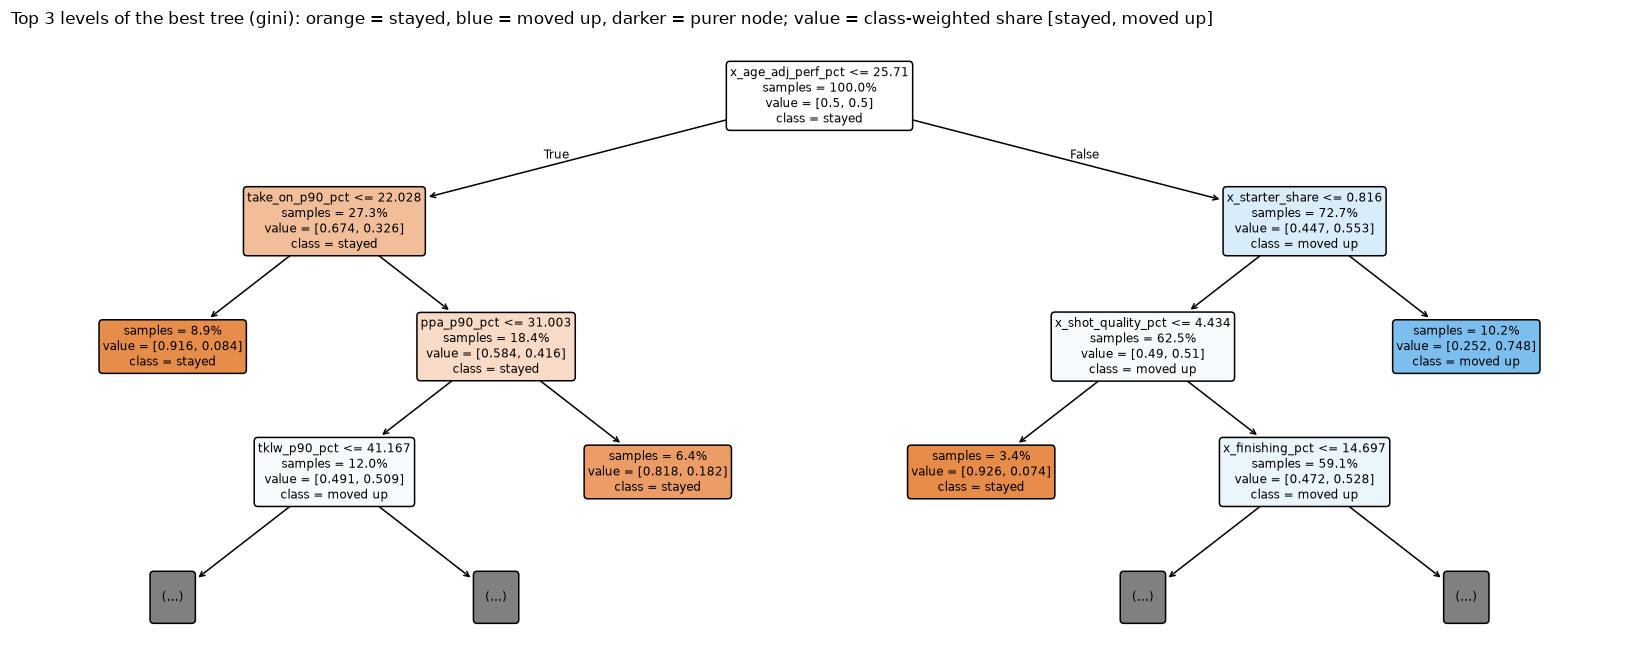

In [45]:
# ---- trace of the best tree: its rules, and the exact path of individual unseen-season players
Y_tr = WF[-1]
tr_t, te_t = pool_lab[pool_lab['yr'] <= Y_tr - 2], pool_lab[pool_lab['yr'] == Y_tr]
best_tree = DecisionTreeClassifier(criterion=best_dt['criterion'], max_depth=None if best_dt['max_depth'] == 'none' else int(best_dt['max_depth']),
                                   min_samples_leaf=int(best_dt['min_samples_leaf']), ccp_alpha=float(best_dt['ccp_alpha']), class_weight='balanced', random_state=0)
best_tree.fit(tr_t[FEATS], tr_t['y_up'].astype(int))
print(f"Best tree trained on seasons up to {Y_tr - 2} and applied to {Y_tr}: depth {best_tree.get_depth()}, {best_tree.get_n_leaves()} leaves")
print(export_text(best_tree, feature_names=FEATS, max_depth=4, show_weights=False))

tree_ = best_tree.tree_
dp_tr = best_tree.decision_path(tr_t[FEATS])
n_node = np.asarray(dp_tr.sum(axis=0)).ravel(); up_node = np.asarray(dp_tr.T @ tr_t['y_up'].astype(int).values).ravel()
p_te = pd.Series(best_tree.predict_proba(te_t[FEATS])[:, 1], index=te_t.index)
picked_ = p_te.sort_values(ascending=False, kind='mergesort').head(K_PICK).index
y_te_ = te_t['y_up'].astype(bool)
cases = {'mover the tree picked (true positive)': [i for i in picked_ if y_te_[i]],
         'mover the tree missed (false negative)': list(p_te[y_te_ & ~te_t.index.isin(picked_)].sort_values().index),
         'non-mover the tree picked (false positive)': [i for i in picked_ if not y_te_[i]]}

def tree_trace(idx):
    x_ = te_t.loc[[idx], FEATS]; path = best_tree.decision_path(x_).indices; steps = []
    for k_, nid in enumerate(path):
        share = up_node[nid] / n_node[nid] if n_node[nid] else np.nan
        if tree_.children_left[nid] == tree_.children_right[nid]:
            steps.append({'step': k_ + 1, 'node': int(nid), 'test at this node': 'LEAF', "player's value": '', 'goes': '',
                          'training players here': int(n_node[nid]), 'of whom moved up': f'{share:.0%}'})
        else:
            f_ = FEATS[tree_.feature[nid]]; th = tree_.threshold[nid]; v_ = float(x_.iloc[0][f_])
            steps.append({'step': k_ + 1, 'node': int(nid), 'test at this node': f'{f_} <= {th:.2f}', "player's value": round(v_, 2), 'goes': 'left (yes)' if v_ <= th else 'right (no)',
                          'training players here': int(n_node[nid]), 'of whom moved up': f'{share:.0%}'})
    return pd.DataFrame(steps)

for title_, ids in cases.items():
    if not ids: continue
    r_ = te_t.loc[ids[0]]
    print(f"\n{title_}: {r_['player']} ({r_['squad']}, {r_['comp']}, age {r_['age_num']:.0f}, {r_['pos_group']}); tree score {p_te[ids[0]]:.2f}; outcome: {r_['outcome']}")
    display(tree_trace(ids[0]))

fig_t, ax_t = plt.subplots(figsize=(15, 6.2), dpi=110)
plot_tree(best_tree, max_depth=3, feature_names=FEATS, class_names=['stayed', 'moved up'], filled=True, rounded=True, impurity=False, proportion=True, fontsize=8, ax=ax_t)
ax_t.set_title(f"Top 3 levels of the best tree ({best_dt['criterion']}): orange = stayed, blue = moved up, darker = purer node; value = class-weighted share [stayed, moved up]", fontsize=11, loc='left')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/s7b_best_tree.png', dpi=140, bbox_inches='tight'); plt.show()
imp_t = pd.Series(best_tree.feature_importances_, index=FEATS).sort_values(ascending=False)
legend('pct', 'x_starter_share', 'composite_perf_index', 'archetype', title='Legend: each step tests one feature against a threshold; "left (yes)" means the value is at or below it; the last row is the leaf that gives the prediction')
takeaway(shows="The best tree's first four levels as if-then rules, the root-to-leaf path of three real test-season players, and a drawing of the top three levels.",
         insight=f"The tree splits first on {FEATS[tree_.feature[0]]} and leans most on {', '.join(imp_t.index[:3])} ({imp_t.iloc[:3].sum():.0%} of its importance). "
                 "The traces show why a player is picked or missed: each step is a readable scouting condition, and the leaf shows how often similar training players really moved up.",
         use="A missed mover usually fails one early split (often playing time); that is a cue to check him manually rather than to trust the tree blindly.")

In [46]:
final_models = make_models()
for mdl in final_models.values(): mdl.fit(pool_lab[FEATS], pool_lab['y_up'].astype(int))
tree = final_models['Decision tree']
print('Decision tree trained on all labelled seasons (read it as scouting rules; class 1 = moved up):')
print(export_text(tree, feature_names=FEATS, max_depth=3))
rf = final_models['Random forest']; imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values().tail(12)
lr_ = final_models['Logistic regression'][-1]; coef = pd.Series(lr_.coef_[0], index=FEATS).sort_values()
cc = pd.concat([coef.head(6), coef.tail(6)])
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.22, subplot_titles=('Random forest: top 12 importances', 'Logistic regression: top coefficients'))
fig.add_trace(go.Bar(y=imp.index, x=imp.values, orientation='h', marker_color=BLUE, showlegend=False, hovertemplate='%{y}: %{x:.3f}<extra></extra>'), row=1, col=1)
fig.add_trace(go.Bar(y=cc.index, x=cc.values, orientation='h', marker_color=[BLUE if v > 0 else ORANGE for v in cc.values], showlegend=False,
                     hovertemplate='%{y}: %{x:+.2f} log-odds per 1 SD<extra></extra>'), row=1, col=2)
fig.update_xaxes(title_text='mean decrease in impurity', row=1, col=1); fig.update_xaxes(title_text='log-odds per 1 SD (blue raises the odds)', row=1, col=2)
fig.update_layout(title='What drives the models? (all labelled seasons)', height=490)
show(fig, 's3_model_drivers', concept='Model interpretation (random forest, logistic regression)')

T_all_lab = build_tx(pool_lab); yb = pool_lab['y_up'].astype(int).values
bb_full = BucketBrigade(CTX, TRAITS, r_up=(1 - yb.mean()) / yb.mean()).fit(T_all_lab, yb)
print('Bucket-brigade classifier: strongest learned "UP" classifiers (strength accumulated through credit assignment)')
display(bb_full.top_rules(6))

legend('pct', 'x_starter_share', 'composite_perf_index', 'archetype', 'LEAGUE_x', 'LCS', title='Legend (feature names end in _pct = percentile)')
takeaway(shows="The decision tree as if-then rules, the random forest's most used inputs, the logistic regression's strongest positive (blue) and negative (orange) inputs, and the bucket-brigade's strongest classifiers.",
         insight=f"Top forest inputs: {', '.join(imp.index[::-1][:3])}; the logistic model's strongest positive input is {coef.idxmax()} and negative {coef.idxmin()}. Playing time and overall quality dominate; single style traits add little.")

Decision tree trained on all labelled seasons (read it as scouting rules; class 1 = moved up):
|--- x_age_adj_perf_pct <= 26.33
|   |--- age_num <= 20.50
|   |   |--- npxg_p90_pct <= 19.64
|   |   |   |--- class: 0
|   |   |--- npxg_p90_pct >  19.64
|   |   |   |--- class: 1
|   |--- age_num >  20.50
|   |   |--- anom_if <= 0.38
|   |   |   |--- class: 1
|   |   |--- anom_if >  0.38
|   |   |   |--- class: 0
|--- x_age_adj_perf_pct >  26.33
|   |--- x_starter_share <= 0.70
|   |   |--- LEAGUE_L1 <= 0.50
|   |   |   |--- class: 0
|   |   |--- LEAGUE_L1 >  0.50
|   |   |   |--- class: 1
|   |--- x_starter_share >  0.70
|   |   |--- kp_p90_pct <= 23.90
|   |   |   |--- class: 0
|   |   |--- kp_p90_pct >  23.90
|   |   |   |--- class: 1



Bucket-brigade classifier: strongest learned "UP" classifiers (strength accumulated through credit assignment)


stage-2 condition,message,strength,best stage-1 context for that message
HI_ast + HI_clr,2,7,POS_FW / LEAGUE_SA
HI_sh + HI_blocks,0,5.2,POS_DF / POS_MF
HI_aer_won,2,5.2,POS_FW / LEAGUE_SA
HI_sh + HI_clr,3,5,POS_FW / AGE_21_22
HI_sca + HI_aer_won,3,5,POS_FW / AGE_21_22
HI_sca + HI_blocks,1,4.9,POS_DF / AGE_21_22


**Why these charts.** Prediction is only useful if a scout can see *why*. The decision-tree text gives literal if-then scouting rules; the **forest importance bars** show which inputs it leans on (magnitude only); the **logistic coefficients** add direction (blue raises, orange lowers the odds), drawn as a diverging bar around zero. The bucket-brigade table lists its strongest learned classifiers with the stage-1 context that routes to them.

## 9B. Prediction (regression): how good will he be two seasons from now? <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Regression (numeric prediction)</span>
Moving up depends on development, so this regression predicts the composite performance index two seasons later from today's profile, using players still in the top-5 leagues at t+2. It is compared with the obvious benchmark, **persistence** ("he will be as good as he is now"), and with a mean-only predictor. Training uses t0 <= 2019, testing t0 2020-2021. Measures: MAE, RMSE, R-squared and a paired bootstrap of the MAE difference.

In [47]:
reg_pool = pool_lab[pool_lab['seen_t2'] & pool_lab['perf_t2'].notna()]
rtr, rte = reg_pool[reg_pool['yr'] <= 2019], reg_pool[reg_pool['yr'] >= 2020]
ridge = make_pipeline(StandardScaler(), Ridge(alpha=30.0)).fit(rtr[FEATS], rtr['perf_t2'])
gbr = GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=0).fit(rtr[FEATS], rtr['perf_t2'])
preds = {'Mean of training targets': np.full(len(rte), rtr['perf_t2'].mean()), 'Persistence (same index as now)': rte['composite_perf_index'].values,
         'Ridge regression': ridge.predict(rte[FEATS]), 'Gradient boosting': gbr.predict(rte[FEATS])}
yt = rte['perf_t2'].values
reg_tbl = pd.DataFrame([{'model': k, 'MAE': np.mean(np.abs(yt - v)), 'RMSE': np.sqrt(np.mean((yt - v) ** 2)), 'R2': 1 - np.sum((yt - v) ** 2) / np.sum((yt - yt.mean()) ** 2)} for k, v in preds.items()]).sort_values('MAE')
display(reg_tbl.round(3))
best_reg = reg_tbl.iloc[0]['model']; err_best, err_pers = np.abs(yt - preds[best_reg]), np.abs(yt - preds['Persistence (same index as now)'])
rr = np.random.default_rng(1); bidx = rr.integers(0, len(yt), (5000, len(yt)))
diff = (err_pers[bidx] - err_best[bidx]).mean(1)
print(f"Best model: {best_reg}. MAE improvement over persistence = {err_pers.mean() - err_best.mean():+.2f} index points, 95% bootstrap CI [{np.percentile(diff, 2.5):+.2f}, {np.percentile(diff, 97.5):+.2f}] "
      f"(test n = {len(yt)}; survivors only: players who left the top-5 leagues have no t+2 index).")
lim = [float(min(yt.min(), preds[best_reg].min())) - 2, float(max(yt.max(), preds[best_reg].max())) + 2]
fig = go.Figure()
fig.add_trace(go.Scatter(x=lim, y=lim, mode='lines', line=dict(color=GREY, dash='dash'), showlegend=False, hoverinfo='skip'))
fig.add_trace(go.Scatter(x=preds[best_reg], y=yt, mode='markers', marker=dict(color=BLUE, size=7, opacity=0.55), showlegend=False, customdata=np.c_[rte['player'], rte['squad'], rte['yr'], rte['composite_perf_index']],
                         hovertemplate='<b>%{customdata[0]}</b> (%{customdata[1]}, %{customdata[2]})<br>index now %{customdata[3]}<br>predicted %{x:.1f}, actual %{y:.1f}<extra></extra>'))
fig.update_layout(title=f'{best_reg}: predicted vs actual index two seasons later', xaxis=dict(title='predicted index at t+2', range=lim), yaxis=dict(title='actual index at t+2', range=lim), height=520, width=640)
show(fig, 's4_regression', concept='Prediction · regression diagnostics')
reg_final = (ridge if best_reg == 'Ridge regression' else gbr) if best_reg in ('Ridge regression', 'Gradient boosting') else ridge

legend('MAE', 'RMSE', 'R²', title='Legend')
takeaway(shows="Four predictors of the composite index two seasons later, compared on unseen seasons, and predicted vs actual for the best one.",
         insight=f"{best_reg} beats persistence by {err_pers.mean() - err_best.mean():+.2f} index points (95% CI [{np.percentile(diff, 2.5):+.2f}, {np.percentile(diff, 97.5):+.2f}]) with R² {reg_tbl.iloc[0]['R2']:.2f}: "
                 "development is partly predictable, and high scorers regress towards the mean.")

,model,MAE,RMSE,R2
2,Ridge regression,6.811,8.61,0.418
3,Gradient boosting,7.017,8.861,0.383
1,Persistence (same index as now),7.647,9.667,0.266
0,Mean of training targets,9.291,11.286,-0.001


Best model: Ridge regression. MAE improvement over persistence = +0.84 index points, 95% bootstrap CI [+0.44, +1.24] (test n = 480; survivors only: players who left the top-5 leagues have no t+2 index).


**Why this chart.** Predicted-versus-actual scatter with the y = x line is the standard regression diagnostic: points hugging the line mean accurate predictions, a flat cloud means the model only predicts the average, and a tilt shows regression to the mean (young high scorers cool off, low scorers improve). Single series, single colour, no legend needed.

# Part VI. From patterns to a decision: the latest-season scouting list
## 10. Bringing the evidence together <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Decision support · combining evidence</span>
Rules and models are re-fitted on **all** labelled seasons and applied to the latest season's eligible feeders from all five leagues. Three independent pieces of evidence are shown for every candidate: **role fit** (cosine similarity to a current elite starter, from the shortlist), **model probability** of moving up (the best classifier from the walk-forward leaderboard, ranked among all latest-season feeders) and **rule support** (how many mined rules the player satisfies). A **priority target** needs role fit *and* a model probability in the top quartile. The regression adds a projected performance index two seasons ahead, and the archetype and anomaly score give context. The latest season's outcome is not in the dataset, so this list is a forecast, not a score.

In [48]:
rules_full, _, _ = mine_rules(tx_all)
rules_full['rule'] = rules_full['antecedent'].map(lambda a: ' + '.join(sorted(a)))
top_full = rules_full.head(min(10, len(rules_full)))
sk_models = ['Logistic regression', 'Decision tree', 'Random forest', 'Naive Bayes']
best_sk = lb[lb['method'].isin(sk_models)].sort_values('mean_AP', ascending=False).iloc[0]['method']
print(f"classifier used for the forecast: {best_sk} (highest mean average precision among the four classifiers in the walk-forward test); {len(top_full)} mined rules applied")

now_all = MODEL[(MODEL['yr'] == LAST_YEAR) & MODEL['feeder']].copy()
raw_p = final_models[best_sk].predict_proba(now_all[FEATS])[:, 1]
if best_sk != 'Naive Bayes':   # class-balanced training inflates probabilities; shift the odds back to the real base rate
    pi_ = pool_lab['y_up'].mean(); odds_ = raw_p / (1 - raw_p + 1e-12) * pi_ / (1 - pi_); raw_p = odds_ / (1 + odds_)
now_all['p_up'] = raw_p
now_all['p_up_rank'] = now_all['p_up'].rank(pct=True)
now_all['proj_perf_t2'] = reg_final.predict(now_all[FEATS])

now = shortlist(LAST_YEAR).join(now_all[['p_up', 'p_up_rank', 'proj_perf_t2']], on='lake_idx')
tx_now = build_tx(lake.loc[now['lake_idx']], with_outcome=False); tx_now.index = now.index
M_now = rule_match(tx_now, top_full)
now['rules_matched'] = M_now.sum(axis=1).values
now['priority'] = now['p_up_rank'] >= 0.75
final = now[['player', 'age_num', 'pos_group', 'squad', 'comp', 'archetype', 'matched_star', 'star_league', 'similarity', 'p_up', 'p_up_rank', 'rules_matched', 'proj_perf_t2', 'priority']].round(3).reset_index(drop=True)
final['age_num'] = final['age_num'].astype(int)
display(final)

model_top = now_all.nlargest(12, 'p_up')[['player', 'age_num', 'pos_group', 'squad', 'comp', 'archetype', 'p_up', 'proj_perf_t2', 'composite_perf_index', 'anom_if']].copy()
model_top['also_role_fit_shortlist'] = model_top.index.isin(now['lake_idx'])
print(f"Highest model probability among all {len(now_all)} eligible {LAST_YEAR}-{str(LAST_YEAR + 1)[2:]} feeders (mean probability {now_all['p_up'].mean():.1%}):")
display(model_top.round(3).reset_index(drop=True))

legend('similarity', 'p_up', 'rules_matched', 'proj_perf_t2', 'priority', 'archetype', 'anom_if', title='Legend')
takeaway(shows=f"First table: the role-fit shortlist for {LAST_YEAR}-{str(LAST_YEAR + 1)[2:]} with model probability and rule support. Second table: the highest model probabilities among all {len(now_all)} feeders.",
         insight=f"{int(final['priority'].sum())} of {len(final)} shortlisted players are priority targets (role fit and a top-quartile probability); "
                 f"{int(model_top['also_role_fit_shortlist'].sum())} of the model's top 12 are also on the role-fit list, so the two signals overlap only partly.",
         use="Priority targets have two independent signals agreeing: they are the first names to send to video scouting.")

classifier used for the forecast: Logistic regression (highest mean average precision among the four classifiers in the walk-forward test); 10 mined rules applied


player,age num,pos group,squad,comp,archetype,matched star,star league,similarity,p up,p up rank,rules matched,proj perf t2,priority
Logan Costa,22,DF,Toulouse,Ligue 1,DF-A0,Willi Orban (RB Leipzig),BL,0.981,0.534,0.949,1,46.537,✓
Victor Osimhen,24,FW,Napoli,Serie A,FW-A2,Dušan Vlahović (Juventus),SA,0.981,0.29,0.681,0,40.368,–
Johan Vásquez,24,DF,Genoa,Serie A,DF-A0,Brendan Chardonnet (Brest),L1,0.98,0.294,0.694,0,48.992,–
Moritz Jenz,24,DF,Wolfsburg,Bundesliga,DF-A0,Gleison Bremer (Juventus),SA,0.979,0.084,0.097,0,39.792,–
Leo Skiri Østigård,23,DF,Napoli,Serie A,DF-A0,Axel Witsel (Atlético Madrid),LL,0.978,0.153,0.296,0,39.746,–
Víctor Chust,23,DF,Cádiz,La Liga,DF-A0,Pau Cubarsí (Barcelona),LL,0.978,0.086,0.112,0,39.843,–
Sepp van den Berg,21,DF,Mainz 05,Bundesliga,DF-A0,Dan-Axel Zagadou (Stuttgart),BL,0.978,0.5,0.931,1,45.778,✓
Abdel Abqar,24,DF,Alavés,La Liga,DF-A0,Diego Carlos (Aston Villa),PL,0.977,0.084,0.102,0,36.896,–
Jorge Herrando,22,DF,Osasuna,La Liga,DF-A0,Milan Škriniar (Paris S-G),L1,0.975,0.052,0.036,0,34.662,–
Luca Ranieri,24,DF,Fiorentina,Serie A,DF-A0,Lilian Brassier (Brest),L1,0.975,0.161,0.321,0,42.13,–


Highest model probability among all 392 eligible 2023-24 feeders (mean probability 24.7%):


player,age num,pos group,squad,comp,archetype,p up,proj perf t2,composite perf index,anom if,also role fit shortlist
Souleymane Touré,20,DF,Lorient,Ligue 1,DF-A0,0.677,53.044,58.1,0.41,–
Arthur Theate,23,DF,Rennes,Ligue 1,DF-A0,0.651,50.964,57.3,0.461,✓
Matìas Soulé,20,FW,Frosinone,Serie A,FW-A1,0.645,61.217,62.3,0.538,–
Désiré Doué,18,MF,Rennes,Ligue 1,MF-A1,0.64,63.866,67.7,0.487,–
Khvicha Kvaratskhelia,22,FW,Napoli,Serie A,FW-A1,0.632,61.914,67.1,0.457,–
Christian Mawissa,18,DF,Toulouse,Ligue 1,DF-A2,0.617,55.285,58.5,0.508,–
Habib Diarra,19,MF,Strasbourg,Ligue 1,MF-A0,0.599,51.235,47,0.399,–
Georges Mikautadze,22,FW,Metz,Ligue 1,FW-A1,0.581,55.911,58.5,0.413,✓
Muhammed Cham,22,MF,Clermont Foot,Ligue 1,MF-A1,0.581,59.178,59.4,0.471,–
Adrien Truffert,21,DF,Rennes,Ligue 1,DF-A1,0.573,57.158,56.5,0.391,–


In [49]:
# Interactive decision table: filter by league with the drop-down
DT = final.copy()
DT['p_up'] = (DT['p_up'] * 100).round(1); DT['similarity'] = DT['similarity'].round(3); DT['proj_perf_t2'] = DT['proj_perf_t2'].round(1)
DT['priority'] = np.where(DT['priority'], 'yes', '')
DT = DT.sort_values(['priority', 'p_up'], ascending=False)
cols_ = ['player', 'age_num', 'pos_group', 'squad', 'comp', 'matched_star', 'similarity', 'p_up', 'rules_matched', 'proj_perf_t2', 'priority']
heads_ = ['Player', 'Age', 'Pos', 'Club', 'League', 'Matched elite starter', 'Similarity', 'Move-up prob. %', 'Rules', 'Projected index t+2', 'Priority']
views = [('All leagues', DT)] + [(L_, DT[DT['comp'] == L_]) for L_ in LEAGUES if (DT['comp'] == L_).any()]
fig = go.Figure()
for vi, (nm_, d_) in enumerate(views):
    fill = [['#ffffff' if i % 2 == 0 else '#fafaf8' for i in range(len(d_))]] * len(cols_)
    fig.add_trace(go.Table(columnwidth=[150, 40, 40, 115, 95, 210, 70, 85, 50, 85, 60], visible=(vi == 0),
                           header=dict(values=[f'<b>{h}</b>' for h in heads_], fill_color='#f0efec', line_color=GRID, align='left', font=dict(color=INK, size=12), height=30),
                           cells=dict(values=[d_[c].tolist() for c in cols_], fill_color=fill, line_color=GRID, align='left', font=dict(color=INK, size=12), height=26)))
fig.update_layout(updatemenus=[dict(buttons=[dict(label=nm_, method='update', args=[{'visible': [j == i for j in range(len(views))]}]) for i, (nm_, _) in enumerate(views)],
                                    direction='down', x=1, xanchor='right', y=1.0, yanchor='bottom', bgcolor='white', bordercolor=GRID, font=dict(size=12))],
                  title=f'Scouting shortlist {LAST_YEAR}-{str(LAST_YEAR + 1)[2:]} (use the drop-down to filter by league)', height=min(130 + 27 * (len(DT) + 1), 860))
show(fig, 'f0_decision_table', concept='Interactive decision table')

In [50]:
mt = model_top.sort_values('p_up')
fig = go.Figure()
for flag_, nm_, c_ in ((True, 'also on the role-fit shortlist', BLUE), (False, 'model only', GREY)):
    g_ = mt[mt['also_role_fit_shortlist'] == flag_]
    fig.add_trace(go.Bar(y=[f"{r.player} ({r.squad})" for r in g_.itertuples()], x=g_['p_up'], orientation='h', name=nm_, marker_color=c_,
                         customdata=np.c_[g_['age_num'], g_['pos_group'], g_['archetype'], g_['proj_perf_t2'].round(1), g_['composite_perf_index']],
                         hovertemplate='<b>%{y}</b>, age %{customdata[0]:.0f}, %{customdata[1]} (%{customdata[2]})<br>move-up probability %{x:.1%}<br>projected index in 2 seasons %{customdata[3]} (now %{customdata[4]})<extra></extra>'))
fig.add_vline(x=now_all['p_up'].mean(), line_dash='dash', line_color=ORANGE, annotation_text='average feeder', annotation_position='top')
fig.update_layout(title=f'Highest move-up probability, {LAST_YEAR}-{str(LAST_YEAR + 1)[2:]} feeders', xaxis=dict(title=f'estimated probability of moving up ({best_sk}, odds re-based to the true {pool_lab["y_up"].mean():.1%} base rate)', tickformat='.0%'),
                  yaxis=dict(categoryorder='array', categoryarray=[f"{r.player} ({r.squad})" for r in mt.itertuples()]), height=520, legend=dict(orientation='h'))
show(fig, 'f1_model_top', concept='Classification · scoring the latest season')

legend('p_up', 'proj_perf_t2', 'archetype', title='Legend')
takeaway(shows="The twelve feeders with the highest estimated chance of moving up; blue bars are also on the role-fit shortlist.",
         insight=f"The top probability is {mt['p_up'].max():.0%} against an average of {now_all['p_up'].mean():.1%}, so even the strongest candidates are far from certain to move: the list ranks, it does not guarantee.")

**Why this chart.** A ranked list of named players with one quantity (probability) is a **sorted horizontal bar chart**. The dashed line is the average feeder, so each bar reads as "this many times more likely than a typical player"; blue marks players who also pass the role-fit filter (two independent signals agreeing), grey those found only by the model.

In [51]:
pick = now.sort_values(['priority', 'similarity'], ascending=False).head(6)
labels, vals = [], []
for _, r in pick.iterrows():
    star_name = r['matched_star'].rsplit(' (', 1)[0]
    s_row = lake[(lake['yr'] == LAST_YEAR) & (lake['player'] == star_name) & lake['elite']].iloc[0]
    labels += [f"{r['player']} ({r['squad']})", f"  matched: {star_name}"]
    vals += [r[[f + '_pct' for f in active_features]].astype(float).values, s_row[[f + '_pct' for f in active_features]].astype(float).values]
xl_ = [f.replace('_p90', '') for f in active_features]
fig = go.Figure(go.Heatmap(z=np.array(vals), x=xl_, y=labels, colorscale=SEQ_SCALE, zmin=0, zmax=100, text=np.where(np.array(vals) >= 55, np.char.add(np.char.add("<span style='color:white'>", np.round(np.array(vals)).astype(int).astype(str)), '</span>'), np.round(np.array(vals)).astype(int).astype(str)), texttemplate='%{text}', textfont=dict(size=10, color=INK),
                           colorbar=dict(title='percentile'), hovertemplate='%{y}<br>%{x}: percentile %{z:.0f}<extra></extra>'))
fig.update_layout(title='Do the picks really look like the stars they replace? (percentile profiles, position- and style-weighted)', height=120 + 36 * len(labels), yaxis=dict(autorange='reversed'))
show(fig, 'v6_profile_match', concept='Similarity search · profile comparison')

legend(*xl_, 'pct', title='Legend')
takeaway(shows="Each pick (row) above the elite starter he was matched to (row below), as percentiles on all 16 metrics.",
         insight="Pairs with matching dark and light cells across the row have the same shape of game; where a pick is lighter overall, he plays the same role at a lower level, which is what a younger replacement usually looks like.")

**Why this chart.** A scout wants to *see* whether two players have the same shape across 16 metrics. A **heatmap of percentiles** (rows = player and the star he replaces, stacked in pairs; columns = metrics) uses a single-hue sequential ramp because the values are one magnitude from 0 to 100, and printing the numbers lets the eye compare pairs row to row. A radar chart would be harder to read with 16 spokes and cannot hold six pairs at once.

## 11. What the data mining discovered (written from the computed results) <span style="background:#e8f1fc;color:#184f95;border:1px solid #86b6ef;border-radius:11px;padding:2px 10px;font-size:12px;font-weight:600;vertical-align:middle;white-space:nowrap">Big Data · Knowledge discovery summary</span>
The next cell writes the conclusions **from the numbers above**, topic by topic, and says plainly where a technique did *not* deliver.

In [52]:
fp_s, fp_b = timing.iloc[-1], timing_big.iloc[-1]
def faster(x): return f"FP-Growth {x:.1f}x faster" if x >= 1 else f"Apriori {1 / x:.1f}x faster"
best_arch = arch_tbl[arch_tbl['feeder n'] >= 20].iloc[0]
top_rule = rules.iloc[0]
learned = lb[~lb['method'].isin(['Best composite (baseline)', 'Similarity to elite starters'])]; bl = learned.iloc[0]
sig_list = lb.loc[lb['binomial_p'] < 0.05, 'method'].tolist()
print("OUTCOME DEFINITION AND REFERENCE SET (5, 5B, 8C)")
print(f"  - Moves up found: {int((cmp_['best_tier'] >= 1).sum())} with the new rule vs {int(cmp_['y_up_v1'].sum())} with the original rule on the same feeders; {len(missed)} real moves (mostly to elite clubs outside the PL) were invisible before.")
print(f"  - Reference sets: best = {best_s['reference']} (hit rate {best_s['hit_rate']:.1%}); original PL top 3 = {orig_s['hit_rate']:.1%}.")
print("TEAM STYLE AND LEAGUE WEIGHTS (4A-4E)")
print(f"  - Understat tactical data matched {len(name_map)} clubs one-to-one; {int(elas.loc[elas['term'] != 'x_str', 'significant'].sum())} of {int((elas['term'] != 'x_str').sum())} position x metric x style-variable elasticities are statistically supported "
      f"(largest: {'; '.join(f'{r.pos} {r.metric} vs {r.term} {r.beta:+.2f}' for r in top_.head(3).itertuples())}); {int(off_sig.values.sum())} of {off_sig.size} league offsets from {len(mv)} cross-league moves are supported.")
W_, R_ = 'team-style + league weighted', 'raw per-90 percentiles'
print(f"  - Bias check: mean variance explained by tactical family fell from {eta['style_raw'].mean():.3f} to {eta['style_weighted'].mean():.3f}; by league from {eta['league_raw'].mean():.3f} to {eta['league_weighted'].mean():.3f}. "
      "Ablation (weighted minus raw features, mean AUC): " + "; ".join(f"{m_} {d_auc.loc[m_, W_] - d_auc.loc[m_, R_]:+.3f}" for m_ in d_auc.index) + ".")
print(f"    Reading: the weights make stats fairer across tactical systems ({'bias cut' if eta['style_weighted'].mean() < eta['style_raw'].mean() else 'no bias cut'}), but they "
      f"{'improve' if (d_auc[W_] - d_auc[R_]).mean() > 0.01 else 'do not improve'} out-of-time prediction of who gets bought (clubs buy on reputation and raw output as much as on context-adjusted output); league weights did not reduce league variance.")
print("DESCRIPTIVE / PRE-PROCESSING (6A-6C)")
print(f"  - Metrics are right-skewed (median skewness {desc['skewness'].median():.2f}) and differ by role, so every trait is ranked within position and season; "
      f"{int((pairs.abs() > 0.7).sum())} of {len(pairs)} metric pairs are strongly correlated. Engineered features in the top 8 single signals: "
      f"{[k for k in top_f.head(8).index if k.startswith('x_') or k in ('starter_share', 'composite_index')]}.")
print("DIMENSIONALITY REDUCTION (6D)")
print(f"  - {n80} principal components keep 80% of the variance of 16 metrics (PC1 alone {ev[0]:.0%}); movers sit between stayers and elite starters along the main axis.")
print("CLUSTERING (6E) AND OUTLIERS (6F)")
print(f"  - K-Means found {sum(best_k.values())} archetypes ({best_k}). Archetype vs move-up is {'significant' if p_chi < 0.05 else 'not significant'} (chi-square p = {p_chi:.3f}, Cramer's V = {cramers_v:.2f}); "
      f"most 'bought' style: {best_arch['archetype']} ({best_arch['move-up rate']:.0%} vs pool {lab_pool['y_up'].mean():.0%}; {best_arch['defining traits (mean z)']}).")
print(f"  - Outlier score vs moving up: Spearman rho = {rho_a:.3f} (p = {p_a:.3f}) -> unusual profiles are {'more' if (p_a < 0.05 and rho_a > 0) else 'not clearly more'} likely to be bought; detectors agree only partly (mean Jaccard {jac.values[np.triu_indices(3, 1)].mean():.2f}).")
print("ASSOCIATION RULES (7) AND RECENT ADVANCES")
print(f"  - Apriori and FP-Growth returned identical itemsets everywhere; on this data {faster(fp_s['speedup_x'])} ({len(tx_train):,} rows) and {faster(fp_b['speedup_x'])} ({int(fp_b['rows']):,} rows).")
print(f"  - {n_cand} candidate class rules -> {len(rules)} after lift, FDR and pruning; strongest [{top_rule['rule']}] -> {top_rule['consequent']}: lift {top_rule['lift']:.1f}x on {int(top_rule['n_joint'])} players.")
print(f"  - Closed itemsets: {cm['closed / frequent'].iloc[-1]:.0%} of the frequent set (lossless, verified: {ok_loss}) - little compression because these binary traits rarely share identical support; maximal itemsets (lossy) shrink it to {cm['maximal / frequent'].iloc[-1]:.0%}.")
print(f"  - Out of time the mined rules flagged players who moved up {oot['flagged_rate']:.1%} vs {oot['pool_rate']:.1%} (lift {oot['lift']:.2f}x, p = {oot['fisher_p']:.3f}): {'a real but modest signal' if oot['fisher_p'] < 0.05 else 'directionally positive but NOT statistically significant'}.")
lo_c = fim_cmp[(fim_cmp["data"] == "training table") & (fim_cmp["min_support"] == fim_cmp["min_support"].min())].set_index("algorithm")
print(f"  - Course algorithms (7c3): Apriori, DHP, DIC, Eclat, Partition, A-Close and Pincer-Search all matched FP-Growth; scans at support {lo_c['min_support'].iloc[0]}: " + ", ".join(f"{a.split(' (')[0]} {v}" for a, v in lo_c["scans"].items()) + ".")
print("SIMILARITY (8)")
print(f"  - The cosine shortlist hit {(SL['weight'] > 0).mean():.1%} vs {(POOL['weight'] > 0).mean():.1%} pool (permutation p = {p_perm:.4f}, Cohen's h = {h_eff:.2f}), but "
      f"{'did not beat' if np.percentile(boot, 2.5) <= 0 else 'beat'} simply taking the best performers ({(BEST['weight'] > 0).mean():.1%}; bootstrap CI of the difference [{np.percentile(boot, 2.5):+.1%}, {np.percentile(boot, 97.5):+.1%}]).")
print(f"  - Seven similarity measures give hit rates {sv['hit_rate'].min():.0%} to {sv['hit_rate'].max():.0%}, statistically indistinguishable with ~{sv['picks'].iloc[0]} picks each.")
print("SUPERVISED PREDICTION (9)")
print(f"  - Walk-forward test, {K_PICK} picks/season over {len(WF)} seasons (a random scout would find ~{K_PICK * len(WF) * pool_rate:.0f} movers in {K_PICK * len(WF)}): best overall = {best_row['method']} {int(best_row['hits@K'])}/{int(best_row['picks'])} "
      f"({best_row['lift_vs_pool']:.1f}x pool); best learned method = {bl['method']} {int(bl['hits@K'])}/{int(bl['picks'])}; 'best composite' baseline {int(base_row['hits@K'])}/{int(base_row['picks'])}.")
print(f"    Methods significantly above a random scout (binomial p < 0.05): {sig_list}. All 95% intervals overlap widely, so the ORDER among them is not statistically reliable; what is reliable is that "
      f"{'most reasonable methods beat chance' if len(sig_list) >= 4 else 'few methods beat chance'}, and that no method clearly beats the naive best-performer rule.")
print(f"  - Decision tree study (9A-3): best {best_dt['criterion']}, depth {best_dt['max_depth']}, leaf {int(best_dt['min_samples_leaf'])}, ccp_alpha {best_dt['ccp_alpha']}: test AUC {best_dt['test_AUC']:.3f} vs {fixed_dt['test_AUC']:.3f} for the fixed depth-3 tree.")
bbr = lb[lb['method'] == 'Bucket-brigade LCS'].iloc[0]
print(f"  - Bucket-brigade classifier system: {int(bbr['hits@K'])}/{int(bbr['picks'])} hits, mean AUC {bbr['mean_AUC']:.2f} (rank {int(lb.index[lb['method'] == 'Bucket-brigade LCS'][0]) + 1} of {len(lb)}).")
print(f"  - Regression of the index at t+2: best {best_reg} MAE {reg_tbl.iloc[0]['MAE']:.2f} vs persistence {reg_tbl[reg_tbl['model'].str.startswith('Persistence')].iloc[0]['MAE']:.2f}, R2 {reg_tbl.iloc[0]['R2']:.2f}.")
pri = final[final['priority']]
print(f"DECISION (10): priority targets for {LAST_YEAR}-{str(LAST_YEAR + 1)[2:]} (role fit AND model top quartile): " + (", ".join(f"{r.player} ({r.squad}, {r.age_num}, p={r.p_up:.2f})" for r in pri.itertuples()) if len(pri) else 'none'))
print("  Model-only top 5: " + ", ".join(f"{r.player} ({r.squad}, p={r.p_up:.2f})" for r in model_top.head(5).itertuples()))
print("CAVEATS: outcomes use the club recorded two seasons later in the same FBref data (not a transfer-history feed); standings are season-final, not per matchweek; "
      "consecutive cohorts share players and test seasons are few, so intervals are wide and p-values optimistic; archetypes and anomaly scores use unsupervised fits on all seasons (no outcome labels); "
      "players are matched by name between seasons.")

takeaway(shows="The whole notebook in one paragraph per technique, written from the numbers above.",
         insight=f"Defining 'moving up' across all five leagues finds {int((cmp_['best_tier'] >= 1).sum())} moves instead of {int(cmp_['y_up_v1'].sum())}, and a five-league reference gives a far larger, more varied set of elite profiles. "
                 f"Similarity and learned models beat random scouting, but none clearly beats simply ranking the best young performers yet; the value is in a shorter, explainable watch list.")

OUTCOME DEFINITION AND REFERENCE SET (5, 5B, 8C)
  - Moves up found: 524 with the new rule vs 67 with the original rule on the same feeders; 457 real moves (mostly to elite clubs outside the PL) were invisible before.
  - Reference sets: best = PL top 3 (hit rate 37.6%); original PL top 3 = 37.6%.
TEAM STYLE AND LEAGUE WEIGHTS (4A-4E)
  - Understat tactical data matched 145 clubs one-to-one; 49 of 96 position x metric x style-variable elasticities are statistically supported (largest: FW ppa vs x_dom +0.37; MF ppa vs x_dom +0.30; FW att_pen vs x_dom +0.25); 39 of 64 league offsets from 467 cross-league moves are supported.
  - Bias check: mean variance explained by tactical family fell from 0.052 to 0.023; by league from 0.010 to 0.011. Ablation (weighted minus raw features, mean AUC): Logistic regression -0.001; Random forest -0.002.
    Reading: the weights make stats fairer across tactical systems (bias cut), but they do not improve out-of-time prediction of who gets bought (clubs b

  - The cosine shortlist hit 22.4% vs 26.7% pool (permutation p = 0.8877, Cohen's h = -0.10), but did not beat simply taking the best performers (43.2%; bootstrap CI of the difference [-32.0%, -9.6%]).
  - Seven similarity measures give hit rates 22% to 30%, statistically indistinguishable with ~125 picks each.
SUPERVISED PREDICTION (9)
  - Walk-forward test, 25 picks/season over 3 seasons (a random scout would find ~21 movers in 75): best overall = Logistic regression 46/75 (2.2x pool); best learned method = Logistic regression 46/75; 'best composite' baseline 31/75.
    Methods significantly above a random scout (binomial p < 0.05): ['Logistic regression', 'Decision tree', 'Mined rules (ARM)', 'Random forest', 'Best composite (baseline)', 'Naive Bayes']. All 95% intervals overlap widely, so the ORDER among them is not statistically reliable; what is reliable is that most reasonable methods beat chance, and that no method clearly beats the naive best-performer rule.
  - Decision tree 

In [53]:

import json as _j, numpy as _np
_M = {}
def _put(k, f):
    try: _M[k] = f()
    except Exception as e: _M[k] = f'ERROR: {type(e).__name__}: {e}'
_put('minutes_column', lambda: col_map['min'])
_put('min_num_describe', lambda: df_raw['min_num'].describe().round(1).to_dict())
_put('rows_raw', lambda: len(df_raw)); _put('rows_outfield_900', lambda: len(df))
_put('n_metrics', lambda: len(active_features))
_put('pool_n', lambda: len(pool_all))
_put('pool_hit_rate', lambda: float((pool_all['weight'] > 0).mean()))
_put('pool_weighted_precision', lambda: float(pool_all['weight'].mean()))
_put('pool_top_club_rate', lambda: float((pool_all['weight'] >= W_TOP6_MOVE).mean()))
_put('base_rate_by_tier', lambda: pool_all['best_tier'].value_counts(normalize=True).sort_index().round(4).to_dict())
_put('base_count_by_tier', lambda: pool_all['best_tier'].value_counts().sort_index().to_dict())
_put('base_by_season', lambda: base.reset_index().to_dict('records'))
_put('base_by_league', lambda: by_lg.reset_index().to_dict('records'))
_put('tier_by_season', lambda: pool_all.groupby('yr')['best_tier'].value_counts(normalize=True).unstack(fill_value=0).round(4).reset_index().to_dict('records'))
_put('moves_new_rule', lambda: int((cmp_['best_tier'] >= 1).sum())); _put('moves_old_rule', lambda: int(cmp_['y_up_v1'].sum()))
_put('eta_style_raw', lambda: float(eta['style_raw'].mean())); _put('eta_style_weighted', lambda: float(eta['style_weighted'].mean()))
_put('eta_league_raw', lambda: float(eta['league_raw'].mean())); _put('eta_league_weighted', lambda: float(eta['league_weighted'].mean()))
_put('elasticities_supported', lambda: int(elas.loc[elas['term'] != 'x_str', 'significant'].sum()))
_put('clubs_matched_understat', lambda: len(name_map))
_put('shortlist_hit_rate', lambda: float((SL['weight'] > 0).mean())); _put('best_composite_hit_rate', lambda: float((BEST['weight'] > 0).mean()))
_put('shortlist_perm_p', lambda: float(p_perm))
_put('shortlist_minus_best_ci95', lambda: [float(_np.percentile(boot, 2.5)), float(_np.percentile(boot, 97.5))])
_put('similarity_measures', lambda: sv.to_dict('records'))
_put('rules_oot', lambda: {k: float(v) for k, v in dict(oot).items() if isinstance(v, (int, float, _np.floating, _np.integer))})
_put('leaderboard', lambda: lb.to_dict('records'))
_put('K_PICK', lambda: K_PICK); _put('walk_forward_seasons', lambda: list(map(int, WF)))
_put('ablation_auc', lambda: d_auc.reset_index().to_dict('records'))
_put('regression', lambda: reg_tbl.to_dict('records'))

# export the mid-sem computed tables so the end-sem code reuses them instead of re-deriving them
import os as _os, pandas as _pd
_os.makedirs('lake/midsem', exist_ok=True)
def _save(name, d):
    d = d.copy(); d.columns = [str(c) for c in d.columns]
    for c in d.columns:
        if d[c].dtype == object: d[c] = d[c].astype(str).where(d[c].notna(), None)
    d.to_parquet(f'lake/midsem/{name}.parquet', index=False)
_save('df_raw', df_raw); _save('lake', lake); _save('ctx', ctx); _save('elas', elas); _save('league_table', LEAGUE_TABLE)
_save('league_offsets', off.reset_index(names='league')); _save('league_offsets_sig', off_sig.reset_index(names='league'))
_save('name_map', _pd.DataFrame([(c, t, v) for (c, t), v in name_map.items()], columns=['comp', 'understat_title', 'squad']))
_j.dump({'EPS_C': EPS_C, 'active_features': active_features, 'drift': dict(zip(mets, map(float, b_hat[0]))), 'GIANTS': GIANTS, 'LEAGUE_RANK': LEAGUE_RANK,
         'ELITE_TOP_N': ELITE_TOP_N, 'CL_TOP_N': CL_TOP_N, 'FEEDER_MAX_AGE': FEEDER_MAX_AGE, 'FEEDER_MIN_MIN': FEEDER_MIN_MIN, 'ELITE_MIN_MIN': ELITE_MIN_MIN,
         'TRAIN_LAST_T0': TRAIN_LAST_T0, 'LAST_YEAR': LAST_YEAR, 'ALIAS': ALIAS, 'col_map': col_map}, open('lake/midsem/config.json', 'w'), indent=1)
_j.dump(_M, open('outputs/baseline_metrics.json', 'w'), indent=1, default=str)
print({k: v for k, v in _M.items() if isinstance(v, str) and v.startswith('ERROR')})


{}
